# End-to-End Data Management Pipeline for a Book Recommendation System
**Course:** Data Management for Machine Learning — Assignment 2  
**Dataset:** Goodreads Books metadata (20,068 books, real) + synthetic users / interactions grounded in the real star-rating distributions  
**Environment:** 100 % **Kaggle / Jupyter** — no cloud account needed. Ingestion → validation → preparation → transformation → features → training → evaluation → **orchestration**, the architecture diagram, the data-validation report, the feature catalog, the **final PDF report**, README, requirements and a GitHub-ready repository are all produced *by this notebook*.

**Contents:** (a) Executive Summary · (b) Objective · (c) Problem Statement · (d) Dataset · (e) Packages, Tools & Set-up · (f) Ingestion & EDA · (g) Preprocessing · (h) Machine Learning · (i) Serving & Reporting layer · (j) Orchestration & Reproducibility · (k) Inferences & Conclusion · (l) Submission pack & deliverables check · (m) Execution evidence (screenshots)

> **Execution environment (Kaggle):** the Goodreads CSV (`Goodreadss Books.csv`) is attached to the notebook as a Kaggle dataset and Internet is enabled so that `pip` can install the libraries. The notebook is executed top to bottom with **Run All** (≈ 3–4 minutes on CPU), and everything is written to `/kaggle/working/recommendation-pipeline/` following the suggested project structure. Outside Kaggle, the environment variable `GOODREADS_CSV` points the pipeline to the CSV.

## (a) Executive Summary

This notebook builds a complete, reproducible, **modular** data-management pipeline for a recommender system and automates it end to end:

`Ingestion → Validation → Preparation → Transformation → Feature Management → Model Training → Model Evaluation → Orchestration`

**How the notebook is organised.** Each stage is a real Python module (`src/<stage>/…`). A notebook cell *writes* the module (`%%writefile`), the next cell *runs* it and shows its outputs. In section (j) the very same modules are executed again by a dependency-aware **workflow engine**, and the results are checked to be identical to the stage-by-stage run — so the notebook doubles as the source code of the GitHub repository.

**What was done**
1. **Ingested** the real Goodreads catalogue (items). Because it holds only book-level metadata, a documented **simulator** generates `users` and time-stamped `interactions` (ratings are drawn from each book's *real* 1–5 star histogram). A small, reproducible fraction of faults is injected so validation can be demonstrated and *measured* against a ledger.
2. **Validated** all three tables with **Pandera** schemas plus custom rules (duplicates, referential integrity, temporal consistency). Rejected rows go to an **error dataset**; soft problems are logged and repaired. An HTML **validation report** is produced.
3. **Prepared / transformed**: cleaning, imputation with flags, a leakage-free **time-based split**, user-activity summaries, item-popularity scores and a sparse **user–item matrix**.
4. **Managed features**: user, item and interaction features (Parquet), a documented **feature catalog**, and a reusable `FeatureStore` that serves training *and* prediction.
5. **Trained 7 models** — Random floor, **Popularity baseline**, **ALS**, **SVD**, **ItemKNN**, **Content-based** and a **Hybrid** — tuned on a *temporal validation fold*, every trial tracked in **MLflow**.
6. **Evaluated** with Precision / Recall / NDCG @5, @10, Coverage, Diversity, RMSE, MAE, plus **bootstrap confidence intervals and paired significance tests**.
7. **Served**: top-10 batch recommendations with a popularity **cold-start fallback**, built from the same feature layer.
8. **Orchestrated** the whole workflow (retries, quality gate, resume/caching, run log, DAG-run graph) and exported the same task registry as an **Apache Airflow DAG**.
9. **Packaged** the deliverables: README, `requirements.txt`, final 2–3 page **PDF report**, repository zip, optional push to GitHub.

The headline numbers are generated programmatically in sections (h)–(k), so they always match the executed run.

> **Honesty note:** interactions are simulated. The pipeline engineering (validation, splitting, features, evaluation, tracking, orchestration) is real and reusable on any real interaction log, but model scores reflect the simulator and must **not** be read as real-world Goodreads performance.

## (b) Objective

Design and implement a modular, reproducible, end-to-end data-management pipeline for a recommender system that:

- ingests user, item and interaction data;
- **automatically validates** quality and separates invalid records into an error dataset;
- prepares / transforms data (cleaning, time-based split, derived datasets);
- creates and documents **reusable features** (identical logic for training and prediction);
- trains **≥ 2 models** (popularity baseline + personalised recommenders) with experiment tracking;
- evaluates them with ranking *and* rating metrics and compares them in one table;
- **automates the full workflow** with correct task dependencies, so that it runs end to end from one command.

The emphasis is on **pipeline quality and reproducibility**, not on maximising accuracy.

## (c) Problem Statement

An online book platform wants to recommend books a reader is likely to enjoy, using each reader's past interactions and the books' metadata.

Formally, given users *U*, items *I* and timestamped ratings *r(u, i, t)*, produce for each user a ranked list of **K unseen items** that maximises the chance of being rated ≥ 4 in the **future** (time-based evaluation), while remaining diverse and covering the catalogue. Data issues (missing values, duplicates, invalid ratings, orphan keys, bad timestamps) must be detected and isolated *before* they reach feature engineering or model training.

**Key questions**
1. How clean is the raw data, and which records must be rejected vs. repaired?
2. Do personalised models beat a popularity baseline on future interactions — and is the difference statistically meaningful?
3. What is the trade-off between accuracy, coverage and diversity?
4. Can the whole workflow be re-run automatically and reproduce the same results?

## (d) Dataset

| Table | Source | Key columns |
|---|---|---|
| **items** | Real: `Goodreadss_Books.csv` (20,068 rows) | `bookId`, `title`, `author`, `genres`, `language`, `num_pages`, `avg_rating`, `num_ratings`, `rated_1 … rated_5`, publish dates |
| **users** | Synthetic (documented simulator) | `user_id`, `signup_date`, `country`, `age_group` |
| **interactions** | Synthetic, **ratings sampled from each book's real star histogram** | `interaction_id`, `user_id`, `item_id`, `rating (1–5)`, `timestamp` |

**Why synthetic users / interactions?** The Goodreads file has no reader-level rows or timestamps, but the assignment requires user–item interactions with time-based splitting. The assignment explicitly allows *"synthetic data … clearly documented"*.

**How the simulator stays realistic**
- Book choice ∝ real popularity (`num_ratings`) × taste match (latent user/genre vectors) → realistic long tail + a personalisation signal.
- Star ratings are drawn from the book's **real** `rated_1…rated_5` distribution and nudged by user bias and taste match.
- Users sign up over 2019–2024 and rate only after signing up; activity is log-normal (few heavy users, many light ones).
- ~2 % faults are injected (see f.1) to exercise the validation layer.

**Known quirks of the real file** (handled in the pipeline): near-empty rows, duplicate `bookId`s, ~17 % missing `rated_*`, a **29-genre boilerplate prefix repeated twice** in the `genres` string, mixed date formats (`July 16th 2005`, `1997`), `num_pages` of 0 / missing.

## (e) Packages, Tools, Libraries & Set-up

| Stage | Tool |
|---|---|
| Data handling | `pandas`, `numpy`, `scipy.sparse`, `pyarrow` (Parquet) |
| Validation | **Pandera** (+ custom rules) |
| Visualisation | `matplotlib`, `seaborn` |
| Baseline model | Popularity recommender (custom, NumPy) |
| Personalised models | **`implicit`** (ALS), **`scikit-surprise`** (SVD), custom ItemKNN, content-based and hybrid |
| Experiment tracking | **MLflow** (local SQLite backend + artifact store — nothing to host) |
| Feature layer | Custom Parquet-backed `FeatureStore` class (Feast-compatible design) |
| Orchestration | Dependency-aware **Python workflow engine** (assignment option: *"clearly structured scheduled Python workflow"*) **+** an **Apache Airflow DAG** generated from the same task registry |
| Reporting | `reportlab` (PDF), `matplotlib` |

**Repository layout produced by this notebook** (the *suggested project structure* of the assignment, plus `src/serving` and `src/reporting`):

```
recommendation-pipeline/
├── data/{raw, processed, features, errors}/
├── src/
│   ├── config.py                 common/            (logging, genre parser)
│   ├── ingestion/  validation/  preparation/  transformation/  features/
│   ├── training/  evaluation/  serving/  reporting/
│   └── pipeline/                 (orchestrator.py, tasks.py, run.py  ← CLI entry point)
├── dags/recommendation_pipeline_dag.py
├── configs/pipeline_config.json   models/   reports/   mlruns/ + mlflow.db
├── requirements.txt   README.md
```

**Assignment requirement → where it is implemented**

| Requirement | Implemented in | Main artefact |
|---|---|---|
| Data ingestion | section (f), `src/ingestion` | `data/raw/*.csv` |
| Data validation (missing, duplicates, dtypes, ratings, timestamps, referential integrity; error dataset) | g.1, `src/validation` | `data/errors/`, `reports/data_validation_report.html` |
| Preparation & transformation (time split, activity, popularity, matrix) | g.2–g.4 | `data/processed/` |
| Feature management (+ catalog, reuse for train & predict) | g.5, `src/features` | `data/features/`, `reports/feature_catalog.csv/.md` |
| ≥ 2 models + experiment tracking | h.2–h.3, MLflow | `models/`, `mlflow.db`, `mlruns/` |
| Evaluation (P/R/NDCG@K, Coverage, Diversity, RMSE, MAE; comparison table) | h.4–h.5 | `reports/model_results.csv` |
| Orchestration (DAG + successful-run screenshot) | (j) | `dags/…py`, `reports/orchestration_run.png` |
| Architecture diagram | below | `reports/architecture_diagram.png` |
| README, requirements, final report | (l) | `README.md`, `requirements.txt`, `reports/final_report.pdf` |

In [1]:
%pip install -q pandera mlflow implicit scikit-surprise pyarrow reportlab

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, time, shutil, warnings, platform, importlib
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")          # recommended by `implicit` for ALS on CPU
from pathlib import Path
warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- project skeleton (suggested structure) + import path
ON_KAGGLE = Path("/kaggle/input").exists()
BASE = Path("/kaggle/working/recommendation-pipeline") if ON_KAGGLE else Path("./recommendation-pipeline").resolve()
BASE.mkdir(parents=True, exist_ok=True)
os.chdir(BASE); sys.path.insert(0, str(BASE))                # `%%writefile src/...` and `import src...` work from here

for d in ["data/raw", "data/processed", "data/features", "data/errors", "models", "reports/metrics", "reports/orchestration", "configs", "dags"]:
    (BASE / d).mkdir(parents=True, exist_ok=True)
for pkg in ["", "common", "ingestion", "validation", "preparation", "transformation", "features", "training", "evaluation", "serving", "reporting", "pipeline"]:
    (BASE / "src" / pkg).mkdir(parents=True, exist_ok=True); (BASE / "src" / pkg / "__init__.py").touch()

# ---------------------------------------------------------------- locate the Goodreads CSV (env var, Kaggle input, working dir)
def find_goodreads_csv():
    if os.environ.get("GOODREADS_CSV") and Path(os.environ["GOODREADS_CSV"]).exists():
        return Path(os.environ["GOODREADS_CSV"])
    for root in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd().parent, Path.home()]:
        if root.exists():
            hits = [p for p in list(root.rglob("*oodread*.csv")) if "recommendation-pipeline" not in p.parts]
            if hits:
                return hits[0]
    raise FileNotFoundError("Goodreads CSV not found: upload it as a Kaggle dataset (Add Data) or set GOODREADS_CSV.")

RAW_CSV = find_goodreads_csv()

import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt, seaborn as sns, joblib, mlflow
import pandera, implicit, surprise
from IPython.display import display, Image, HTML
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def load(module):                                             # import (or re-import after editing) a module written by this notebook
    importlib.invalidate_caches()
    m = importlib.import_module(module)
    return importlib.reload(m)

print("python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| pandera", pandera.__version__,
      "| mlflow", mlflow.__version__, "| implicit", implicit.__version__, "| surprise", surprise.__version__)
print("Running on Kaggle:", ON_KAGGLE, "\nDataset found    :", RAW_CSV, "\nProject directory:", BASE)

python 3.13.16 | pandas 2.3.3 | numpy 2.1.3 | pandera 0.36.0 | mlflow 3.18.0 | implicit 0.7.3 | surprise 1.1.5
Running on Kaggle: True 
Dataset found    : /kaggle/input/datasets/karthiksundararajan/goodread-books/Goodreadss Books.csv 
Project directory: /kaggle/working/recommendation-pipeline


### e.1 Configuration, paths and logging (the foundation every stage imports)
`src/config.py` is the **single source of truth** (seed, split fractions, thresholds, K values, quality-gate threshold) and `Paths` encodes the suggested folder structure. `src/common/` holds the logger and the parser for the messy `genres` field.

In [3]:
%%writefile src/config.py
"""Central configuration + path helpers: the single source of truth shared by every pipeline stage."""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

DEFAULT_CFG = dict(
    seed=42,
    # --- simulator (users + interactions are synthetic, grounded in the real Goodreads star histograms)
    n_users=4000, catalog_size=3000, min_num_ratings=2000,
    start_date="2019-01-01", end_date="2024-06-30",
    fault_rate=0.02,
    # --- modelling
    test_fraction=0.20,        # last 20 % of interactions (by time) -> test
    val_fraction=0.15,         # last 15 % of TRAIN (by time) -> validation fold used for tuning
    positive_threshold=4,      # rating >= 4  => "relevant"
    ks=[5, 10],
    bayes_prior=20,            # shrinkage strength of the Bayesian item average
    # --- orchestration
    max_reject_ratio=0.05,     # quality gate: stop the pipeline if > 5 % of interaction rows are rejected
    source_csv=None,           # path of the real Goodreads items file (filled in by the notebook / CLI)
)

SUBDIRS = ["data/raw", "data/processed", "data/features", "data/errors", "models",
           "reports", "reports/metrics", "reports/orchestration", "configs", "dags"]


class Paths:
    """All folders of the suggested project structure, relative to one base directory."""

    def __init__(self, base):
        self.base = Path(base).resolve()
        self.raw = self.base / "data/raw"
        self.processed = self.base / "data/processed"
        self.features = self.base / "data/features"
        self.errors = self.base / "data/errors"
        self.models = self.base / "models"
        self.reports = self.base / "reports"
        self.metrics = self.base / "reports/metrics"
        self.orchestration = self.base / "reports/orchestration"
        self.configs = self.base / "configs"
        self.dags = self.base / "dags"
        self.mlflow_db = self.base / "mlflow.db"
        self.mlruns = self.base / "mlruns"

    def ensure(self):
        for d in SUBDIRS:
            (self.base / d).mkdir(parents=True, exist_ok=True)
        return self


def save_config(base, cfg) -> Path:
    P = Paths(base).ensure()
    path = P.configs / "pipeline_config.json"
    path.write_text(json.dumps(cfg, indent=2))
    return path


def load_config(base) -> dict:
    return json.loads((Paths(base).configs / "pipeline_config.json").read_text())


def config_hash(cfg) -> str:
    """Short fingerprint of a configuration (used by the orchestrator's resume logic)."""
    return hashlib.sha256(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:12]

Writing src/config.py


In [4]:
%%writefile src/common/log.py
"""Tiny logging helper: prints to the notebook / console and (optionally) to a log file."""
import logging


class _PrintHandler(logging.Handler):
    def emit(self, record):
        print(self.format(record))


def get_logger(stage: str) -> logging.Logger:
    log = logging.getLogger(f"recsys.{stage}")
    log.setLevel(logging.INFO)
    root = logging.getLogger("recsys")
    root.setLevel(logging.INFO)
    if not any(isinstance(h, _PrintHandler) for h in root.handlers):
        h = _PrintHandler()
        h.setFormatter(logging.Formatter("[%(name)s] %(message)s"))
        root.addHandler(h)
    return log

Writing src/common/log.py


In [5]:
%%writefile src/common/genres.py
"""Parsing of the messy Goodreads `genres` field (29-genre boilerplate prefix, repeated twice)."""
from __future__ import annotations

import pandas as pd

NON_CATEGORY = {"Fiction", "Nonfiction", "Audiobook", "Ebooks", "Audiobooks", "Adult", "Novels", "Contemporary",
                "Book Club", "Adult Fiction", "Childrens", "Literature", "American", "School", "Academic"}


class GenreParser:
    """Learns the boilerplate prefix from the data, then returns the de-duplicated list of *real* genres."""

    def __init__(self, prefix):
        self.prefix = list(prefix)

    @classmethod
    def fit(cls, genres: pd.Series, n_prefix: int = 29) -> "GenreParser":
        return cls(genres.dropna().iloc[0].split(",")[:n_prefix])

    def prefix_share(self, genres: pd.Series) -> float:
        n = len(self.prefix)
        return float(genres.dropna().map(lambda s: s.split(",")[:n] == self.prefix).mean())

    def parse(self, s):
        if not isinstance(s, str) or not s.strip():
            return []
        toks = [t.strip() for t in s.split(",") if t.strip()]
        n = len(self.prefix)
        for _ in range(2):                                   # strip the repeated boilerplate prefix
            if toks[:n] == self.prefix:
                toks = toks[n:]
        seen, out = set(), []
        for t in toks:
            if "Goodreads" in t:                             # scraping artefact such as "Goodreads' Transgender Books page"
                continue
            if t not in seen:
                seen.add(t)
                out.append(t)
        return out

    @staticmethod
    def primary(genres):
        for g in genres:
            if g not in NON_CATEGORY:
                return g
        return None

Writing src/common/genres.py


In [6]:
from src.config import DEFAULT_CFG, Paths, save_config, config_hash
CFG = {**DEFAULT_CFG, "source_csv": str(RAW_CSV)}
SEED = CFG["seed"]; np.random.seed(SEED); POS = CFG["positive_threshold"]
save_config(BASE, CFG)                                        # stages (and the orchestrator) read the SAME file -> reproducible
print(json.dumps(CFG, indent=2)); print("config fingerprint:", config_hash(CFG))

{
  "seed": 42,
  "n_users": 4000,
  "catalog_size": 3000,
  "min_num_ratings": 2000,
  "start_date": "2019-01-01",
  "end_date": "2024-06-30",
  "fault_rate": 0.02,
  "test_fraction": 0.2,
  "val_fraction": 0.15,
  "positive_threshold": 4,
  "ks": [
    5,
    10
  ],
  "bayes_prior": 20,
  "max_reject_ratio": 0.05,
  "source_csv": "/kaggle/input/datasets/karthiksundararajan/goodread-books/Goodreadss Books.csv"
}
config fingerprint: 8726e8b0e8a8


### e.2 Architecture diagram
The diagram is drawn by `src/reporting/architecture.py` (also regenerated by the pipeline's last task) and saved to `reports/architecture_diagram.png` for the report and README.

In [7]:
%%writefile src/reporting/architecture.py
"""Architecture diagram of the pipeline (saved to reports/architecture_diagram.png)."""
from __future__ import annotations

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from src.config import Paths


def draw(base, show=False):
    P = Paths(base).ensure()
    fig, ax = plt.subplots(figsize=(16, 7.4)); ax.axis("off"); ax.set_xlim(0, 16); ax.set_ylim(0, 7.4)

    def box(x, y, w, h, title, sub, color, fs=10):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=color, ec="#333", lw=1.1))
        ax.text(x + w / 2, y + h * 0.68, title, ha="center", va="center", fontsize=fs, fontweight="bold")
        ax.text(x + w / 2, y + h * 0.27, sub, ha="center", va="center", fontsize=7.4, color="#222")

    def arrow(x1, y1, x2, y2, ls="-", c="#333"):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=13, lw=1.3, color=c, ls=ls))

    row = [("1 Ingestion", "Goodreads items (real)\nusers + interactions\n(documented simulator)", "#dbe9f6"),
           ("2 Validation", "Pandera schemas, dup /\nref-integrity / temporal\nrules -> error dataset", "#fde0dc"),
           ("3 Preparation", "clean, impute, standardise\ngenre parsing", "#e2f0d9"),
           ("4 Transformation", "time-based split\nactivity, popularity,\nuser-item matrix", "#e2f0d9"),
           ("5 Feature mgmt", "user / item / interaction\nfeatures -> Parquet\n+ catalog + FeatureStore", "#fff2cc")]
    for k, (t, s, c) in enumerate(row):
        box(0.3 + k * 3.1, 5.0, 2.5, 1.75, t, s, c)
        if k:
            arrow(0.3 + k * 3.1 - 0.6, 5.88, 0.3 + k * 3.1, 5.88)
    box(0.3, 2.55, 4.6, 1.75, "6 Model training", "Random | Popularity | ALS | SVD\nItemKNN | Content | Hybrid\ntuned on a temporal validation fold", "#e4dcf1")
    box(5.7, 2.55, 4.0, 1.75, "7 Evaluation", "P@K  R@K  NDCG@K  Coverage\nDiversity  RMSE  MAE\nbootstrap CIs + significance tests", "#e4dcf1")
    box(10.5, 2.55, 5.2, 1.75, "Serving / reporting", "top-10 batch lists + cold-start fallback\nfeature catalog, validation report,\nresults table, final PDF report", "#d9ead3")
    arrow(4.9, 3.42, 5.7, 3.42); arrow(9.7, 3.42, 10.5, 3.42)
    arrow(13.4, 5.0, 2.6, 4.3)
    ax.add_patch(FancyBboxPatch((0.3, 0.35), 15.4, 1.45, boxstyle="round,pad=0.04,rounding_size=0.12", fc="#eeeeee", ec="#333", lw=1.1, ls="--"))
    ax.text(8.0, 1.52, "8 Orchestration - dependency-aware Python workflow engine (retries, quality gate, resume, run log)  |  same task registry exported as an Apache Airflow DAG",
            ha="center", fontsize=9.6, fontweight="bold")
    ax.text(8.0, 0.86, "ingest -> validate -> QUALITY GATE -> prepare -> transform -> features -> train x7 -> evaluate -> batch recommend -> publish reports\n"
            "MLflow (SQLite backend): params | metrics | model artifacts  -  data/{raw,processed,features,errors}/ as Parquet / CSV",
            ha="center", fontsize=8.2, color="#222")
    for x, t in [(3.5, "data/errors/\n(rejected rows + log)"), (9.7, "data/processed/"), (12.8, "data/features/")]:
        ax.text(x, 4.78, t, ha="center", va="top", fontsize=7.2, color="#555")
    ax.set_title("Recommendation data-management pipeline - architecture", fontweight="bold", fontsize=13)
    plt.tight_layout()
    fig.savefig(P.reports / "architecture_diagram.png", dpi=150)
    if not show:
        plt.close(fig)
    return P.reports / "architecture_diagram.png"

Writing src/reporting/architecture.py


In [8]:
%%writefile src/reporting/figures.py
"""Result figures saved to reports/ (used by the PDF report and displayed in the notebook)."""
from __future__ import annotations

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import Paths

PALETTE = ["#cfcfcf", "#8c8c8c", "#4C72B0", "#C44E52", "#55A868", "#CCB974", "#8172B2"]


def results_figure(base, show=False):
    P = Paths(base)
    cfg = json.loads((P.configs / "pipeline_config.json").read_text()); K = max(cfg["ks"])
    res = pd.read_csv(P.reports / "model_results.csv", index_col=0)
    ci = pd.read_csv(P.reports / "model_results_ci.csv")
    short = [n.split(" (")[0] for n in res.index]
    fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
    for ax, metric in zip(axes[:3], [f"Precision@{K}", f"Recall@{K}", f"NDCG@{K}"]):
        c = ci[ci.metric == metric].set_index("Model").loc[res.index]
        ax.bar(short, c["mean"], yerr=[c["mean"] - c["ci_low"], c["ci_high"] - c["mean"]], color=PALETTE[:len(res)], capsize=3, ecolor="#333")
        ax.set_title(f"{metric} (95% bootstrap CI)"); ax.tick_params(axis="x", rotation=35)
        for i, v in enumerate(c["mean"]):
            ax.text(i, c["ci_high"].iloc[i], f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax, x, w = axes[3], np.arange(len(res)), 0.38
    ax.bar(x - w / 2, res[f"Coverage@{K}"], w, label="Coverage", color="#55A868"); ax.bar(x + w / 2, res[f"Diversity@{K}"], w, label="Diversity", color="#CCB974")
    ax.set_xticks(x); ax.set_xticklabels(short, rotation=35); ax.set_title(f"Coverage & Diversity @{K}"); ax.legend()
    plt.tight_layout(); fig.savefig(P.reports / "results_overview.png", dpi=140)
    if not show:
        plt.close(fig)
    return P.reports / "results_overview.png"


def validation_figure(base, show=False):
    P = Paths(base)
    log = pd.read_csv(P.errors / "validation_error_log.csv")
    plot = log.groupby(["table", "rule", "severity"]).size().rename("rows").reset_index()
    plot["label"] = plot["table"] + " | " + plot["rule"]
    plot = plot.sort_values("rows")
    fig, ax = plt.subplots(figsize=(10, 5.6))
    ax.barh(plot["label"], plot["rows"], color=plot["severity"].map({"reject": "#C44E52", "warning": "#CCB974"}))
    ax.set(title="Validation findings per rule (red = rejected, yellow = repaired warning)", xlabel="rows affected (log scale)", xscale="log")
    plt.tight_layout(); fig.savefig(P.reports / "validation_findings.png", dpi=140)
    if not show:
        plt.close(fig)
    return P.reports / "validation_findings.png"

Writing src/reporting/figures.py


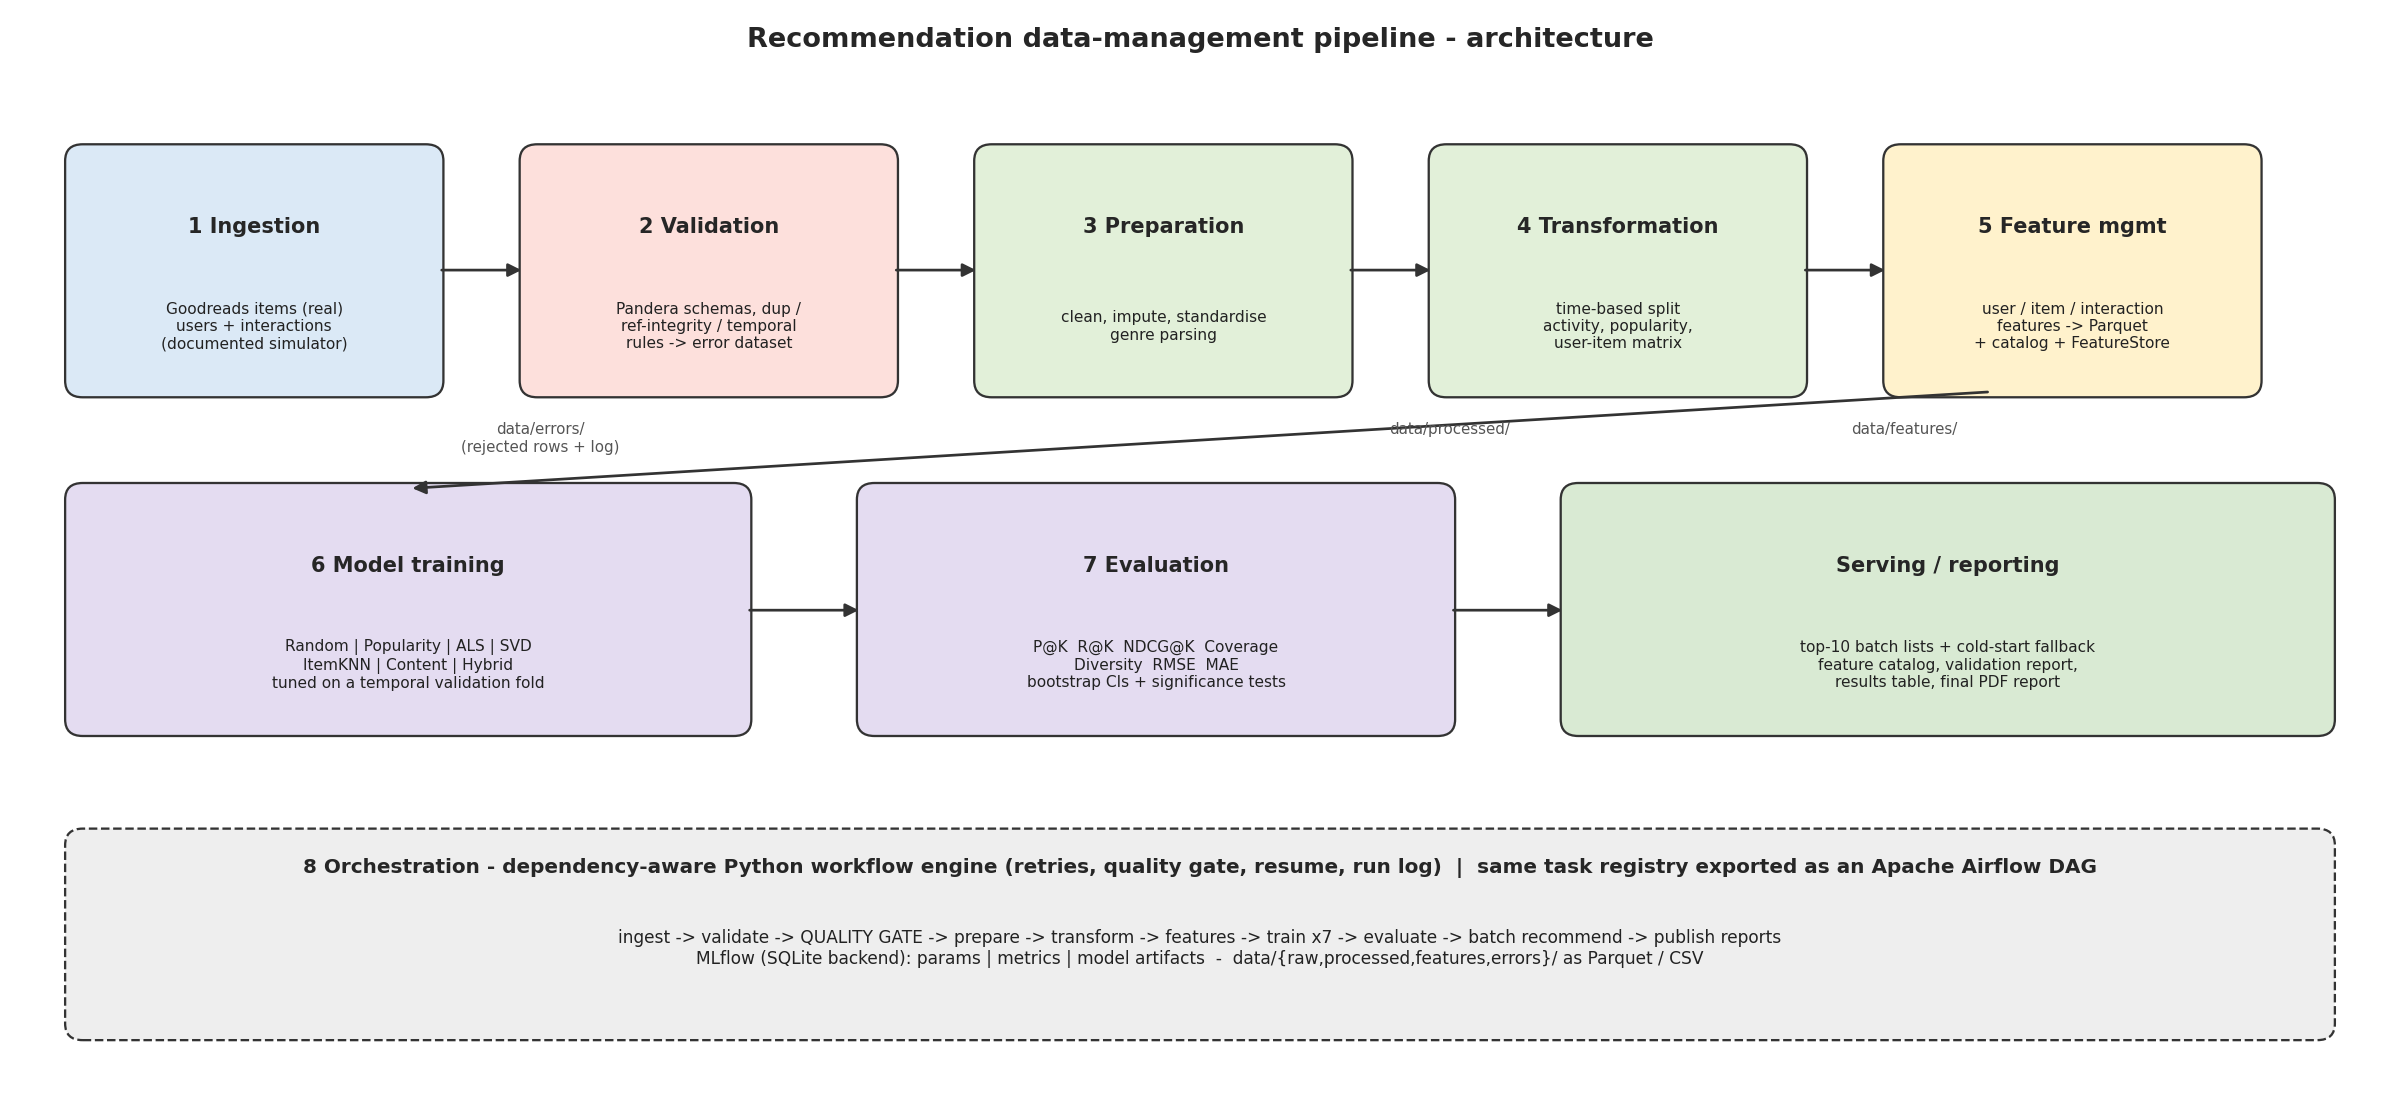

In [9]:
load("src.reporting.architecture"); load("src.reporting.figures")
from src.reporting import architecture, figures
display(Image(filename=str(architecture.draw(BASE))))

## (f) Data Ingestion & Exploratory Data Analysis

### f.1 Ingestion
Three steps: (1) load the real **items** file, (2) **simulate** the `users` and `interactions` source extracts (saved to `data/raw/` as messy CSVs, exactly like an upstream system export) and inject a documented, reproducible set of faults, (3) **re-ingest** all three tables as *raw strings* so nothing is silently coerced before validation.

In [10]:
%%writefile src/ingestion/ingest.py
"""Stage 1 - Data ingestion.

* loads the REAL Goodreads items file,
* simulates the `users` and `interactions` source extracts (documented simulator, ratings drawn from each
  book's real 1-5 star histogram),
* injects a small, reproducible fraction of faults so that the validation layer can be demonstrated,
* writes the three messy extracts to data/raw/ exactly like an upstream system export.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from src.common.genres import GenreParser
from src.common.log import get_logger
from src.config import Paths

log = get_logger("ingestion")


def load_items(csv_path) -> pd.DataFrame:
    return pd.read_csv(csv_path).drop(columns=["Unnamed: 0"], errors="ignore")


def simulate_users_and_interactions(items: pd.DataFrame, cfg: dict, parser: GenreParser):
    rng = np.random.default_rng(cfg["seed"])
    it = items.copy()
    it["genres_list"] = it["genres"].map(parser.parse)
    it["category"] = it["genres_list"].map(parser.primary)
    hist_cols = [f"rated_{k}" for k in range(1, 6)]
    ok = (it[hist_cols].notna().all(axis=1) & (it["num_ratings"] >= cfg["min_num_ratings"])
          & it["category"].notna() & ~it["bookId"].duplicated())
    cat = it[ok].sort_values("num_ratings", ascending=False).head(cfg["catalog_size"]).reset_index(drop=True)
    n_items, n_users = len(cat), cfg["n_users"]

    # keep the 14 biggest categories, everything else -> "Other"
    top_cats = cat["category"].value_counts().head(14).index
    cat["sim_cat"] = np.where(cat["category"].isin(top_cats), cat["category"], "Other")
    cats = sorted(cat["sim_cat"].unique()); K = len(cats)
    cat_idx = cat["sim_cat"].map({c: i for i, c in enumerate(cats)}).to_numpy()

    # latent taste space: items cluster around their category centroid, users mix 1-3 favourite categories
    D = 8
    centroids = rng.normal(size=(K, D))
    item_vec = centroids[cat_idx] + 0.7 * rng.normal(size=(n_items, D))
    taste = rng.dirichlet(np.full(K, 0.25), size=n_users)
    user_vec = taste @ centroids + 0.5 * rng.normal(size=(n_users, D))
    item_vec /= np.linalg.norm(item_vec, axis=1, keepdims=True)
    user_vec /= np.linalg.norm(user_vec, axis=1, keepdims=True)
    aff = user_vec @ item_vec.T
    aff_z = (aff - aff.mean()) / aff.std()
    pop_z = np.log(cat["num_ratings"].to_numpy()); pop_z = (pop_z - pop_z.mean()) / pop_z.std()
    choice_score = 0.8 * pop_z[None, :] + 1.6 * aff_z                      # popularity + taste

    # users
    start, end = pd.Timestamp(cfg["start_date"]), pd.Timestamp(cfg["end_date"])
    span_days = (end - start).days - 90
    signup = start + pd.to_timedelta(rng.integers(0, span_days, n_users), unit="D")
    users = pd.DataFrame({
        "user_id": [f"U{i+1:05d}" for i in range(n_users)],
        "signup_date": signup.strftime("%Y-%m-%d"),
        "country": rng.choice(["IN", "US", "GB", "CA", "AU", "DE", "SG", "AE"], n_users,
                              p=[.30, .28, .12, .08, .06, .06, .05, .05]),
        "age_group": rng.choice(["18-24", "25-34", "35-44", "45-54", "55+"], n_users, p=[.22, .36, .22, .12, .08]),
    })

    # interactions: Gumbel-top-n sampling = weighted sampling without replacement
    n_per_user = np.clip(rng.lognormal(np.log(24), 0.75, n_users).round().astype(int), 6, 250)
    rows_u, rows_i = [], []
    for u in range(n_users):
        g = choice_score[u] + rng.gumbel(size=n_items)
        top = np.argpartition(-g, n_per_user[u])[: n_per_user[u]]
        rows_u.append(np.full(len(top), u)); rows_i.append(top)
    u_idx, i_idx = np.concatenate(rows_u), np.concatenate(rows_i)

    # rating = draw from the book's REAL star histogram, nudged by taste match + user bias
    H = cat[hist_cols].to_numpy(float); H = H / H.sum(axis=1, keepdims=True)
    cdf = np.cumsum(H, axis=1)[i_idx]
    base = (rng.random(len(i_idx))[:, None] > cdf).sum(axis=1) + 1
    user_bias = rng.normal(0, 0.30, n_users)
    rating = np.clip(np.rint(base + 0.45 * aff_z[u_idx, i_idx] + user_bias[u_idx] + rng.normal(0, 0.3, len(base))), 1, 5).astype(int)

    # timestamp: between the user's signup and end_date
    s_ts = pd.to_datetime(users["signup_date"]).to_numpy()[u_idx].astype("datetime64[s]").astype("int64")
    e_ts = np.int64(end.value // 10**9)
    ts = (s_ts + (e_ts - s_ts) * rng.beta(1.0, 1.25, len(u_idx))).astype("int64")
    inter = pd.DataFrame({
        "user_id": users["user_id"].to_numpy()[u_idx],
        "item_id": cat["bookId"].to_numpy()[i_idx],
        "rating": rating,
        "timestamp": pd.to_datetime(ts, unit="s").strftime("%Y-%m-%d %H:%M:%S"),
    }).sample(frac=1, random_state=cfg["seed"]).reset_index(drop=True)
    inter.insert(0, "interaction_id", [f"I{i+1:07d}" for i in range(len(inter))])
    return users, inter


def inject_faults(users: pd.DataFrame, inter: pd.DataFrame, cfg: dict):
    """Documented + reproducible fault injection. Returns (users, interactions, ledger)."""
    rng = np.random.default_rng(cfg["seed"] + 1)
    u, x = users.astype(object).copy(), inter.astype(object).copy()
    n = len(x); nf = int(n * cfg["fault_rate"] / 10)
    perm = rng.permutation(n); slot = lambda k: perm[k * nf:(k + 1) * nf]
    led = {}

    x.loc[slot(0), "rating"] = rng.choice(["0", "6", "-1", "11", "7"], nf);               led["interactions: rating out of range"] = nf
    x.loc[slot(1), "rating"] = rng.choice(["five", "4 stars", "excellent", "good"], nf);   led["interactions: rating wrong dtype"] = nf
    x.loc[slot(2), "rating"] = np.nan;                                                     led["interactions: rating missing"] = nf
    x.loc[slot(3), "user_id"] = np.nan;                                                    led["interactions: user_id missing"] = nf
    x.loc[slot(4), "timestamp"] = rng.choice(["not_a_date", "32/13/2020", "0000-00-00"], nf); led["interactions: timestamp invalid"] = nf
    x.loc[slot(5), "timestamp"] = [f"{y}-0{m}-15 10:00:00" for y, m in zip(rng.integers(2026, 2032, nf), rng.integers(1, 9, nf))]; led["interactions: timestamp in future"] = nf
    x.loc[slot(6), "user_id"] = [f"U9{k:04d}" for k in rng.integers(0, 9999, nf)];          led["interactions: orphan user_id"] = nf
    x.loc[slot(7), "item_id"] = rng.integers(9_000_000, 9_999_999, nf).astype(str);        led["interactions: orphan item_id"] = nf
    # timestamp before the user's signup
    sd = pd.to_datetime(u.set_index("user_id")["signup_date"])
    b = slot(8); bad_ts = (sd.reindex(x.loc[b, "user_id"]).to_numpy() - pd.to_timedelta(rng.integers(5, 400, nf), unit="D"))
    x.loc[b, "timestamp"] = pd.Series(bad_ts).dt.strftime("%Y-%m-%d 12:00:00").to_numpy();   led["interactions: timestamp before signup"] = nf
    dups = x.iloc[slot(9)].copy(); x = pd.concat([x, dups], ignore_index=True);            led["interactions: exact duplicate rows"] = nf
    x = x.sample(frac=1, random_state=cfg["seed"]).reset_index(drop=True)

    nu = len(u)
    u.loc[rng.choice(nu, 40, replace=False), "country"] = np.nan;                           led["users: country missing"] = 40
    u.loc[rng.choice(nu, 30, replace=False), "age_group"] = rng.choice(["unknown", "150", "-"], 30); led["users: invalid age_group"] = 30
    u.loc[rng.choice(nu, 5, replace=False), "signup_date"] = ["2031-05-01", "unknown", "2030-01-01", "2045-12-31", "00-00-0000"]; led["users: invalid/future signup_date"] = 5
    u = pd.concat([u, u.iloc[rng.choice(nu, 15, replace=False)]], ignore_index=True);       led["users: duplicate user_id rows"] = 15
    return u.sample(frac=1, random_state=cfg["seed"]).reset_index(drop=True), x, pd.Series(led, name="injected").to_frame()


def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    if not cfg.get("source_csv"):
        raise ValueError("cfg['source_csv'] must point to the Goodreads items CSV")
    items = load_items(cfg["source_csv"])
    parser = GenreParser.fit(items["genres"])
    log.info(f"items loaded: {items.shape} | boilerplate genre prefix in {parser.prefix_share(items['genres']):.1%} of genre strings")
    users_ok, inter_ok = simulate_users_and_interactions(items, cfg, parser)
    users_src, inter_src, ledger = inject_faults(users_ok, inter_ok, cfg)
    items.to_csv(P.raw / "items_raw.csv", index=False)
    users_src.to_csv(P.raw / "users_raw.csv", index=False)
    inter_src.to_csv(P.raw / "interactions_raw.csv", index=False)
    ledger.to_csv(P.raw / "injected_fault_ledger.csv")
    log.info(f"source extracts written to data/raw/: items={items.shape} users={users_src.shape} interactions={inter_src.shape}")
    return {"items": len(items), "users": len(users_src), "interactions": len(inter_src), "faults_injected": int(ledger["injected"].sum())}

Writing src/ingestion/ingest.py


In [11]:
ingest = load("src.ingestion.ingest")
print(ingest.run(BASE, CFG))

from src.common.genres import GenreParser, NON_CATEGORY
items_raw = pd.read_csv(BASE / "data/raw/items_raw.csv")
users_raw = pd.read_csv(BASE / "data/raw/users_raw.csv", dtype=str)               # read as text: nothing is silently coerced
inter_raw = pd.read_csv(BASE / "data/raw/interactions_raw.csv", dtype=str)
parser = GenreParser.fit(items_raw["genres"])
print(f"Boilerplate genre prefix present in {parser.prefix_share(items_raw['genres']):.1%} of non-null genre strings")
for name, df in [("items", items_raw), ("users", users_raw), ("interactions", inter_raw)]:
    print(f"{name:13s} rows={len(df):>7,}  cols={df.shape[1]:>2}  memory={df.memory_usage(deep=True).sum()/1e6:6.1f} MB")
display(items_raw.head(3).T.head(14)); display(users_raw.head(3)); display(inter_raw.head(3))
print("Faults injected by the simulator (ledger, used later to MEASURE the validators):")
display(pd.read_csv(BASE / "data/raw/injected_fault_ledger.csv", index_col=0))

[recsys.ingestion] items loaded: (20068, 23) | boilerplate genre prefix in 100.0% of genre strings
[recsys.ingestion] source extracts written to data/raw/: items=(20068, 23) users=(4015, 4) interactions=(126106, 5)
{'items': 20068, 'users': 4015, 'interactions': 126106, 'faults_injected': 2600}
Boilerplate genre prefix present in 100.0% of non-null genre strings
items         rows= 20,068  cols=23  memory=  50.4 MB
users         rows=  4,015  cols= 4  memory=   0.9 MB
interactions  rows=126,106  cols= 5  memory=  35.7 MB


,0,1,2
bookId,1,2,3
title,Harry Potter and the Half-Blood Prince,Harry Potter and the Order of the Phoenix,Harry Potter and the Sorcerer's Stone
author,J.K. Rowling,"J.K. Rowling,Mary GrandPré","J.K. Rowling,Mary GrandPré"
series,Harry Potter #6,Harry Potter #5,Harry Potter #1
description,The war against Voldemort is not going well; e...,There is a door at the end of a silent corrido...,Harry Potter's life is miserable. His parents ...
genres,"Art,Biography,Business,Children's,Christian,Cl...","Art,Biography,Business,Children's,Christian,Cl...","Art,Biography,Business,Children's,Christian,Cl..."
awards,Locus Award Nominee for Best Young Adult Novel...,Bram Stoker Award for Works for Young Readers ...,Mythopoeic Fantasy Award for Children's Litera...
characters,"Draco Malfoy,Ron Weasley,Petunia Dursley,Verno...","Sirius Black,Draco Malfoy,Ron Weasley,Petunia ...","Draco Malfoy,Ron Weasley,Petunia Dursley,Verno..."
places,"Hogwarts School of Witchcraft and Wizardry,Eng...","Hogwarts School of Witchcraft and Wizardry,Lon...","London, England,Hogwarts School of Witchcraft ..."
isbn,NaN,0439358078,NaN


,user_id,signup_date,country,age_group
0,U01072,2021-01-23,IN,25-34
1,U01201,2022-11-30,US,25-34
2,U02719,2020-01-11,IN,25-34


,interaction_id,user_id,item_id,rating,timestamp
0,I0093878,U02702,11759,5,2019-11-29 11:51:03
1,I0017498,U03536,12998,4,2022-12-17 21:37:02
2,I0018105,U01315,5913,5,2024-01-19 09:16:29


Faults injected by the simulator (ledger, used later to MEASURE the validators):


,injected
interactions: rating out of range,251
interactions: rating wrong dtype,251
interactions: rating missing,251
interactions: user_id missing,251
interactions: timestamp invalid,251
interactions: timestamp in future,251
interactions: orphan user_id,251
interactions: orphan item_id,251
interactions: timestamp before signup,251
interactions: exact duplicate rows,251


### f.2 Items – completeness and structure
EDA is done on the **raw** data (before cleaning) so that quality problems are visible. Interaction columns are coerced *only for plotting*; the real validation happens in section (g).

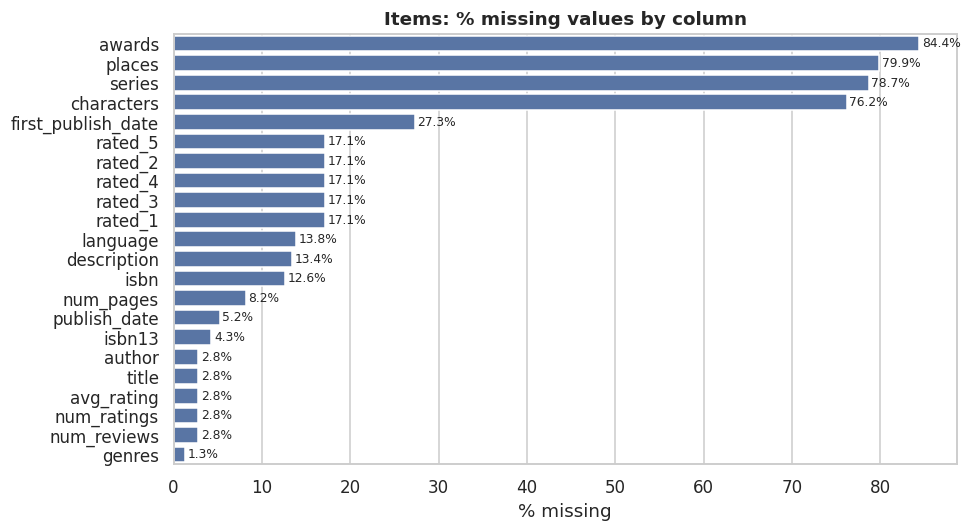

Duplicate bookId rows : 127
Rows with no title    : 559
Rows with 0 ratings   : 1686


,num_pages,num_ratings,num_reviews,avg_rating
count,18428.00,19509.00,19509.00,19509.00
mean,292.45,74103.52,2073.16,3.69
std,307.33,330281.16,7394.39,1.00
min,0.00,0.00,0.00,0.00
25%,148.00,20.00,2.00,3.67
50%,252.00,437.00,32.00,3.93
75%,369.00,11146.00,567.00,4.14
max,23931.00,7444102.00,117992.00,5.00


In [12]:
# ---- missingness profile of the real items file
miss = (items_raw.isna().mean() * 100).sort_values(ascending=False); miss = miss[miss > 0]
if not miss.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.barplot(x=miss.values, y=miss.index, color="#4C72B0", ax=ax)
    for i, v in enumerate(miss.values): ax.text(v + .3, i, f"{v:.1f}%", va="center", fontsize=8)
    ax.set(title="Items: % missing values by column", xlabel="% missing", ylabel=""); plt.tight_layout(); plt.show()
print("Duplicate bookId rows :", int(items_raw["bookId"].duplicated().sum()))
print("Rows with no title    :", int(items_raw["title"].isna().sum()))
print("Rows with 0 ratings   :", int((items_raw["num_ratings"].fillna(0) == 0).sum()))
display(items_raw[[c for c in ["num_pages", "num_ratings", "num_reviews", "avg_rating"] if c in items_raw.columns]].describe().round(2))

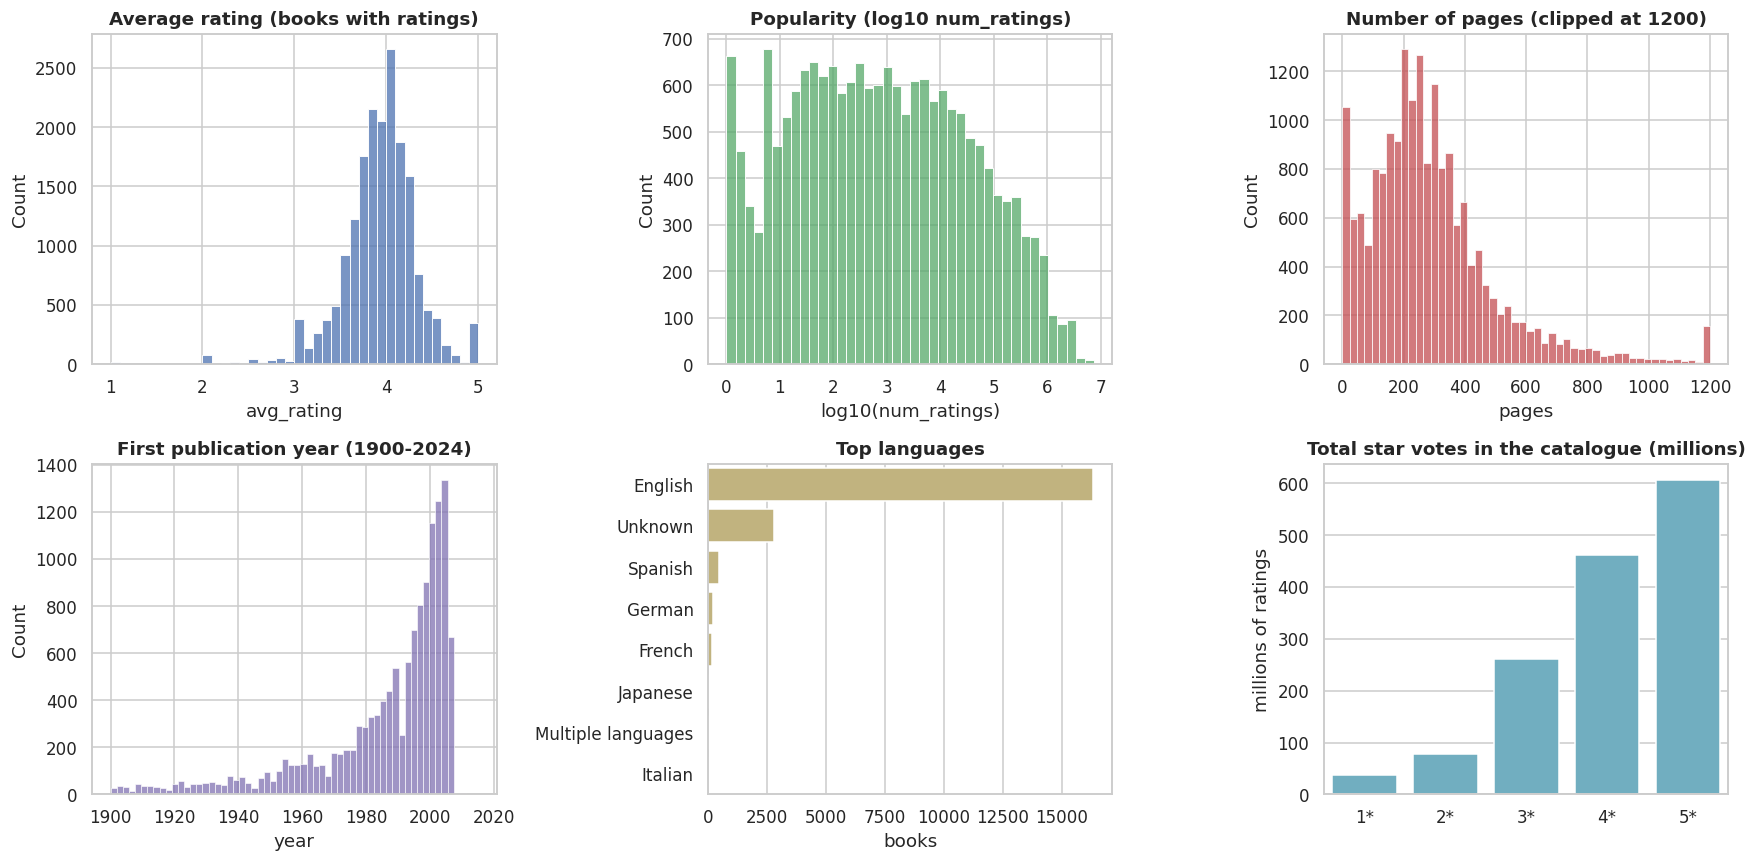

In [13]:
# ---- distributions of the main numeric attributes
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
r = items_raw[items_raw["num_ratings"] > 0]
sns.histplot(r["avg_rating"], bins=40, ax=axes[0, 0], color="#4C72B0"); axes[0, 0].set(title="Average rating (books with ratings)", xlabel="avg_rating")
sns.histplot(np.log10(r["num_ratings"]), bins=40, ax=axes[0, 1], color="#55A868"); axes[0, 1].set(title="Popularity (log10 num_ratings)", xlabel="log10(num_ratings)")
sns.histplot(items_raw["num_pages"].clip(upper=1200).dropna(), bins=50, ax=axes[0, 2], color="#C44E52"); axes[0, 2].set(title="Number of pages (clipped at 1200)", xlabel="pages")
yr = items_raw["first_publish_date"].str.extract(r"(\d{4})")[0].astype(float)
sns.histplot(yr[(yr >= 1900) & (yr <= 2024)], bins=60, ax=axes[1, 0], color="#8172B2"); axes[1, 0].set(title="First publication year (1900-2024)", xlabel="year")
lang = items_raw["language"].fillna("Unknown").value_counts().head(8)
sns.barplot(x=lang.values, y=lang.index, ax=axes[1, 1], color="#CCB974"); axes[1, 1].set(title="Top languages", xlabel="books", ylabel="")
stars = items_raw[[f"rated_{k}" for k in range(1, 6)]].sum()
sns.barplot(x=[f"{k}*" for k in range(1, 6)], y=stars.values / 1e6, ax=axes[1, 2], color="#64B5CD"); axes[1, 2].set(title="Total star votes in the catalogue (millions)", ylabel="millions of ratings")
plt.tight_layout(); plt.show()

Books with NO usable genre after cleaning: 25.3%


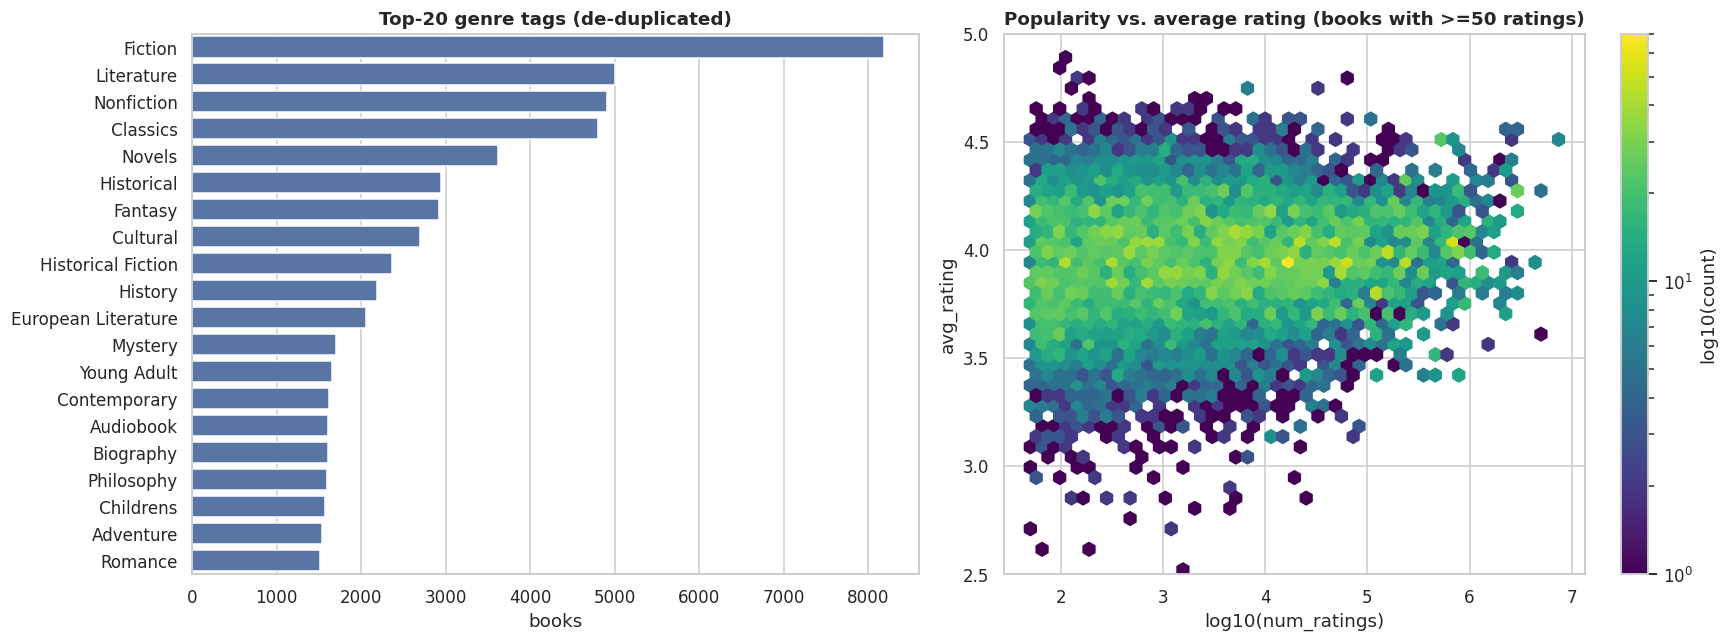

Top 10 most-rated books:


,bookId,title,author,num_ratings,avg_rating
15948,15868,Harry Potter y la piedra filosofal,"J.K. Rowling,Alicia Dellepiane Rawson,Dolores ...",7444102.0,4.48
15951,15871,Harry Potter à l'école des sorciers,"J.K. Rowling,Jean-François Ménard",7444102.0,4.48
15960,15880,Harrius Potter et Philosophi Lapis,"J.K. Rowling,Peter Needham",7444102.0,4.48
4249,4255,Harry Potter and the Philosopher's Stone,J.K. Rowling,7437005.0,4.48
3351,3356,Harry Potter y la piedra filosofal,J.K. Rowling,7436916.0,4.48
3352,3357,Harry Potter Y La Piedra Filosofal,J.K. Rowling,7436916.0,4.48
2,3,Harry Potter and the Sorcerer's Stone,"J.K. Rowling,Mary GrandPré",7434783.0,4.48
12110,12024,Twilight,Stephenie Meyer,5173079.0,3.61
2649,2654,To Kill a Mockingbird,Harper Lee,4712812.0,4.28
2655,2660,To Kill a Mockingbird,Harper Lee,4712812.0,4.28


In [14]:
# ---- genres (after removing the boilerplate prefix) and the popularity/quality relationship
tmp = items_raw.copy()
tmp["genres_list"] = tmp["genres"].map(parser.parse)
tmp["category"] = tmp["genres_list"].map(GenreParser.primary)
from collections import Counter
gc = Counter(g for l in tmp["genres_list"] for g in l)
topg = pd.Series(dict(gc.most_common(20)))
print(f"Books with NO usable genre after cleaning: {(tmp['genres_list'].map(len) == 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=topg.values, y=topg.index, ax=axes[0], color="#4C72B0"); axes[0].set(title="Top-20 genre tags (de-duplicated)", xlabel="books", ylabel="")
rr = tmp[(tmp["num_ratings"] >= 50)]
hb = axes[1].hexbin(np.log10(rr["num_ratings"]), rr["avg_rating"], gridsize=45, cmap="viridis", mincnt=1, bins="log")
plt.colorbar(hb, ax=axes[1], label="log10(count)")
axes[1].set(title="Popularity vs. average rating (books with >=50 ratings)", xlabel="log10(num_ratings)", ylabel="avg_rating", ylim=(2.5, 5))
plt.tight_layout(); plt.show()
print("Top 10 most-rated books:")
display(items_raw.nlargest(10, "num_ratings")[["bookId", "title", "author", "num_ratings", "avg_rating"]])

### f.3 Users and interactions – raw snapshot

,count,%
rows,126106,100.0
rating not parseable (non-null),251,0.2
rating missing,251,0.2
rating outside 1-5,251,0.2
timestamp not parseable,251,0.2
user_id missing,251,0.2
exact duplicate rows,251,0.2


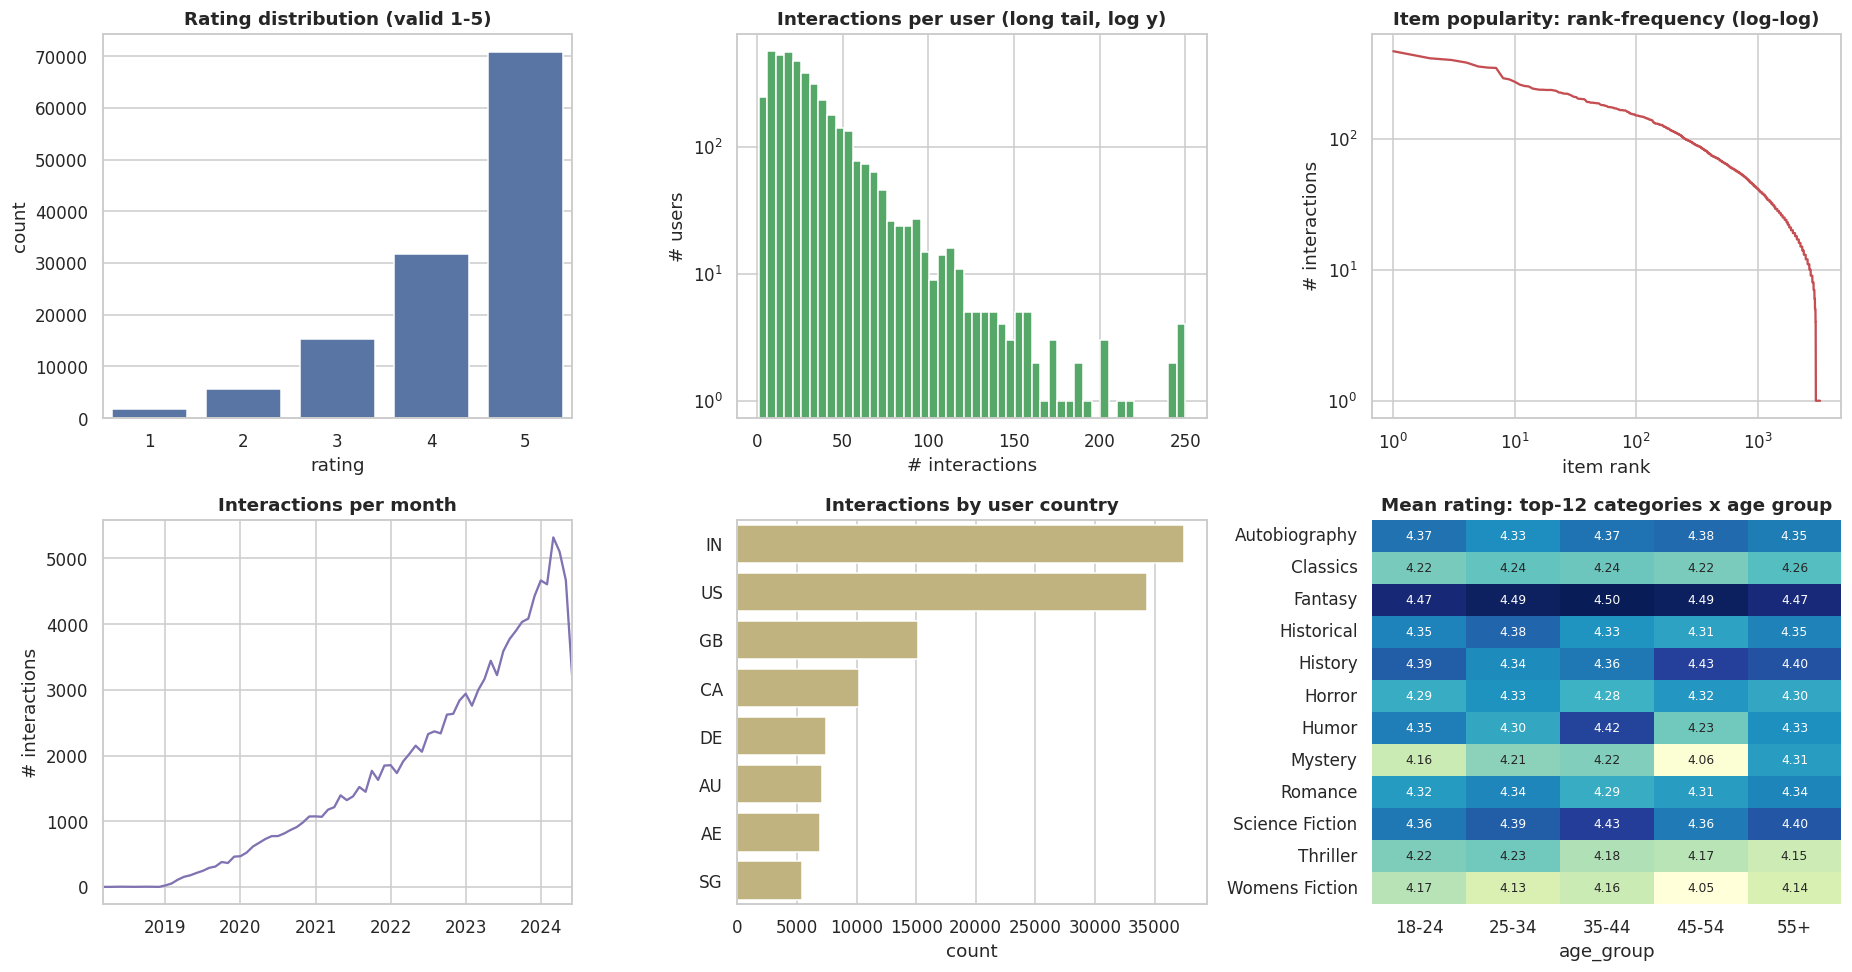

Top 1% of items receive 6.8% of interactions  |  density = 0.913%


In [15]:
# coerce ONLY for plotting; validation (section g) re-does this rigorously
ie = inter_raw.copy()
ie["rating_n"] = pd.to_numeric(ie["rating"], errors="coerce")
ie["ts"] = pd.to_datetime(ie["timestamp"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
ie["item_n"] = pd.to_numeric(ie["item_id"], errors="coerce")
cat_map = (tmp.drop_duplicates("bookId").set_index("bookId")["category"])
ie["category"] = ie["item_n"].map(cat_map)
ie = ie.merge(users_raw.drop_duplicates("user_id")[["user_id", "country", "age_group"]], on="user_id", how="left")

snap = pd.Series({
    "rows": len(ie),
    "rating not parseable (non-null)": int((ie["rating"].notna() & ie["rating_n"].isna()).sum()),
    "rating missing": int(ie["rating"].isna().sum()),
    "rating outside 1-5": int((ie["rating_n"].notna() & ~ie["rating_n"].between(1, 5)).sum()),
    "timestamp not parseable": int((ie["timestamp"].notna() & ie["ts"].isna()).sum()),
    "user_id missing": int(ie["user_id"].isna().sum()),
    "exact duplicate rows": int(inter_raw.duplicated().sum()),
}, name="count").to_frame(); snap["%"] = (snap["count"] / len(ie) * 100).round(2)
display(snap)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
sns.countplot(x=ie.loc[ie["rating_n"].between(1, 5), "rating_n"].astype(int), ax=axes[0, 0], color="#4C72B0"); axes[0, 0].set(title="Rating distribution (valid 1-5)", xlabel="rating")
per_user = ie.groupby("user_id").size()
axes[0, 1].hist(per_user, bins=50, color="#55A868", log=True); axes[0, 1].set(title="Interactions per user (long tail, log y)", xlabel="# interactions", ylabel="# users")
per_item = ie.groupby("item_n").size().sort_values(ascending=False).to_numpy()
axes[0, 2].loglog(np.arange(1, len(per_item) + 1), per_item, color="#C44E52"); axes[0, 2].set(title="Item popularity: rank-frequency (log-log)", xlabel="item rank", ylabel="# interactions")
monthly = ie.dropna(subset=["ts"]).query("ts <= '2024-07-01'").set_index("ts").resample("MS").size()
monthly.plot(ax=axes[1, 0], color="#8172B2"); axes[1, 0].set(title="Interactions per month", xlabel="", ylabel="# interactions")
sns.countplot(data=ie.dropna(subset=["country"]), y="country", order=ie["country"].value_counts().index, ax=axes[1, 1], color="#CCB974"); axes[1, 1].set(title="Interactions by user country", ylabel="")
top_c = ie["category"].value_counts().head(12).index
piv = ie[ie["rating_n"].between(1, 5) & ie["category"].isin(top_c)].dropna(subset=["age_group"]).pivot_table(index="category", columns="age_group", values="rating_n", aggfunc="mean")
piv = piv[[c for c in ["18-24", "25-34", "35-44", "45-54", "55+"] if c in piv.columns]]
sns.heatmap(piv, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[1, 2], cbar=False, annot_kws={"size": 8}); axes[1, 2].set(title="Mean rating: top-12 categories x age group", ylabel="")
plt.tight_layout(); plt.show()
top1 = per_item[: max(1, int(0.01 * len(per_item)))].sum() / per_item.sum()
print(f"Top 1% of items receive {top1:.1%} of interactions  |  density = {len(ie)/(per_user.shape[0]*len(per_item)):.3%}")

## (g) Preprocessing

### g.1 Data validation (Pandera + custom rules)

Rules are split by **severity**:

| Severity | Meaning | Action |
|---|---|---|
| **reject** | the row cannot be trusted or joined (null keys, invalid rating, bad timestamp, duplicate, orphan key, timestamp before signup…) | moved to the **error dataset** (`data/errors/`) |
| **warning** | the row is usable but a field is poor (missing country, `num_pages = 0`, missing genres…) | logged, **repaired** in g.2 |

Pandera performs the *schema* checks (nullability, dtype, ranges, regex formats) with `lazy=True` so **all** failures are collected; rules that need context (duplicates, referential integrity, temporal consistency) are explicit masks. Tables are validated in dependency order **users → items → interactions**, so that referential integrity is checked against the *validated* parents. Besides the machine-readable log, the stage writes a human-readable **HTML validation report** and compares what it found with the simulator's fault ledger.

In [16]:
%%writefile src/validation/validate.py
"""Stage 2 - Automated data validation (Pandera schemas + custom rules).

Rule severity
* reject  -> row cannot be trusted / joined: moved to the error dataset (data/errors/)
* warning -> row is usable but a field is poor: logged and repaired in the preparation stage
Tables are validated in dependency order: users -> items -> interactions (referential integrity).
"""
from __future__ import annotations

import json

import numpy as np
import pandas as pd

try:
    import pandera.pandas as pa      # pandera >= 0.24
except ImportError:                  # pragma: no cover
    import pandera as pa

from src.common.genres import GenreParser
from src.common.log import get_logger
from src.config import Paths

log = get_logger("validation")

MIN_DATE = pd.Timestamp("2000-01-01")
AGE_GROUPS = ["18-24", "25-34", "35-44", "45-54", "55+"]
LOG_COLS = ["table", "row_index", "column", "rule", "value", "severity"]
HIST_COLS = [f"rated_{k}" for k in range(1, 6)]


# ----------------------------------------------------------------------------- helpers
def run_schema(df, schema, table, severity):
    """Lazy Pandera validation -> failures in a tidy log format."""
    try:
        schema.validate(df, lazy=True)
        return pd.DataFrame(columns=LOG_COLS)
    except pa.errors.SchemaErrors as e:
        fc = e.failure_cases
    schema_level = fc[fc["index"].isna()]
    if len(schema_level):
        log.info(f"[{table}] schema-level findings (not row-specific): {schema_level[['column', 'check']].drop_duplicates().values.tolist()}")
    fc = fc[fc["index"].notna()]
    return pd.DataFrame({"table": table, "row_index": fc["index"].astype(int).to_numpy(), "column": fc["column"].to_numpy(),
                         "rule": fc["check"].astype(str).to_numpy(), "value": fc["failure_case"].astype(str).to_numpy(), "severity": severity})


def flag(mask, table, rule, column, values, severity="reject"):
    """Boolean mask -> log rows."""
    idx = np.flatnonzero(np.asarray(mask))
    return pd.DataFrame({"table": table, "row_index": idx, "column": column, "rule": rule,
                         "value": np.asarray(values, dtype=object)[idx].astype(str), "severity": severity})


def typed_check(raw, parsed, table, column):
    """Raw value present but could not be parsed into the expected dtype => 'dtype_mismatch'."""
    return flag(raw.notna().to_numpy() & parsed.isna().to_numpy(), table, "dtype_mismatch", column, raw.to_numpy())


def drop_null_dupes(lg):
    """A failed parse is reported once as dtype_mismatch (not additionally as 'null')."""
    dt = lg.loc[lg["rule"] == "dtype_mismatch", ["table", "row_index", "column"]].assign(_d=1)
    m = lg.merge(dt, on=["table", "row_index", "column"], how="left")
    return lg[~((m["rule"] == "not_nullable").to_numpy() & m["_d"].notna().to_numpy())].reset_index(drop=True)


# ----------------------------------------------------------------------------- per-table validators
def validate_users(users_raw, end_date):
    ut = users_raw.copy()
    ut["signup_date"] = pd.to_datetime(users_raw["signup_date"], errors="coerce", format="%Y-%m-%d")
    hard = pa.DataFrameSchema({
        "user_id": pa.Column(str, [pa.Check(lambda s: s.str.match(r"^U\d{5}$"), name="user_id_format")], nullable=False),
        "signup_date": pa.Column(nullable=False, checks=[pa.Check(lambda s: s <= end_date, name="signup_date<=end_date"),
                                                          pa.Check(lambda s: s >= MIN_DATE, name="signup_date>=2000")]),
    }, strict=False)
    soft = pa.DataFrameSchema({
        "country": pa.Column(str, nullable=False),
        "age_group": pa.Column(str, [pa.Check(lambda s: s.isin(AGE_GROUPS), name="age_group_valid")], nullable=False),
    }, strict=False)
    lg = pd.concat([
        run_schema(ut, hard, "users", "reject"),
        typed_check(users_raw["signup_date"], ut["signup_date"], "users", "signup_date"),
        flag(users_raw["user_id"].duplicated(keep="first"), "users", "duplicate_user_id", "user_id", users_raw["user_id"]),
        run_schema(ut, soft, "users", "warning"),
    ], ignore_index=True)
    return drop_null_dupes(lg), ut


def validate_items(items_raw, parser: GenreParser):
    hard = pa.DataFrameSchema({
        "bookId": pa.Column(int, nullable=False),
        "title": pa.Column(str, nullable=False),
        "num_ratings": pa.Column(float, [pa.Check(lambda s: s >= 0, name="num_ratings>=0")], nullable=False),
        "avg_rating": pa.Column(float, [pa.Check(lambda s: s.between(0, 5), name="avg_rating_in_[0,5]")], nullable=False),
    }, strict=False)
    soft = pa.DataFrameSchema({
        "num_pages": pa.Column(float, [pa.Check(lambda s: s.between(1, 10000), name="num_pages_in_[1,10000]")], nullable=True),
    }, strict=False)
    hist_sum = items_raw[HIST_COLS].sum(axis=1, min_count=5)
    gen_empty = items_raw["genres"].map(parser.parse).map(len) == 0
    return pd.concat([
        run_schema(items_raw, hard, "items", "reject"),
        flag(items_raw["bookId"].duplicated(keep="first"), "items", "duplicate_bookId", "bookId", items_raw["bookId"]),
        run_schema(items_raw, soft, "items", "warning"),
        flag(items_raw["num_pages"].isna(), "items", "missing_num_pages", "num_pages", items_raw["num_pages"], "warning"),
        flag(gen_empty, "items", "no_usable_genres", "genres", items_raw["genres"].fillna("<null>").str[:30], "warning"),
        flag(items_raw["language"].isna(), "items", "missing_language", "language", items_raw["language"], "warning"),
        flag(items_raw["rated_1"].isna(), "items", "missing_star_histogram", "rated_1..5", items_raw["rated_1"], "warning"),
        flag(hist_sum.notna() & ((hist_sum - items_raw["num_ratings"]).abs() > 0.02 * items_raw["num_ratings"].clip(lower=1) + 5),
             "items", "histogram_sum_mismatch", "rated_1..5", hist_sum, "warning"),
        flag(items_raw["first_publish_date"].isna() & items_raw["publish_date"].isna(), "items", "missing_publish_date", "publish_date", items_raw["publish_date"], "warning"),
    ], ignore_index=True)


def parse_interactions(inter_raw):
    xt = inter_raw.copy()
    xt["rating"] = pd.to_numeric(inter_raw["rating"], errors="coerce")
    xt["item_id"] = pd.to_numeric(inter_raw["item_id"], errors="coerce")
    xt["timestamp"] = pd.to_datetime(inter_raw["timestamp"], errors="coerce", format="%Y-%m-%d %H:%M:%S")
    return xt


def validate_interactions(inter_raw, valid_user_ids, valid_item_ids, signup_map, end_date):
    xt = parse_interactions(inter_raw)
    schema = pa.DataFrameSchema({
        "interaction_id": pa.Column(str, nullable=False),
        "user_id": pa.Column(str, [pa.Check(lambda s: s.str.match(r"^U\d{5}$"), name="user_id_format")], nullable=False),
        "item_id": pa.Column(nullable=False, checks=[pa.Check(lambda s: (s > 0) & (s % 1 == 0), name="item_id_positive_integer")]),
        "rating": pa.Column(float, [pa.Check(lambda s: s.isin([1, 2, 3, 4, 5]), name="rating_in_{1..5}")], nullable=False),
        "timestamp": pa.Column(nullable=False, checks=[pa.Check(lambda s: s <= end_date, name="timestamp<=end_date"),
                                                        pa.Check(lambda s: s >= MIN_DATE, name="timestamp>=2000")]),
    }, strict=False)
    uid_ok = inter_raw["user_id"].notna()
    signup_for_row = inter_raw["user_id"].map(signup_map)
    lg = pd.concat([
        run_schema(xt, schema, "interactions", "reject"),
        typed_check(inter_raw["rating"], xt["rating"], "interactions", "rating"),
        typed_check(inter_raw["item_id"], xt["item_id"], "interactions", "item_id"),
        typed_check(inter_raw["timestamp"], xt["timestamp"], "interactions", "timestamp"),
        flag(inter_raw.duplicated(keep="first"), "interactions", "duplicate_row", "interaction_id", inter_raw["interaction_id"]),
        # referential integrity against the *validated* parent tables
        flag(uid_ok & ~inter_raw["user_id"].isin(valid_user_ids), "interactions", "ref_integrity_user", "user_id", inter_raw["user_id"]),
        flag(xt["item_id"].notna() & ~xt["item_id"].isin(valid_item_ids), "interactions", "ref_integrity_item", "item_id", inter_raw["item_id"]),
        # temporal consistency: cannot interact before signing up
        flag(xt["timestamp"].notna() & signup_for_row.notna() & (xt["timestamp"] < signup_for_row), "interactions", "timestamp>=signup_date", "timestamp", inter_raw["timestamp"]),
    ], ignore_index=True)
    return drop_null_dupes(lg)


# ----------------------------------------------------------------------------- detection check + HTML report
def detection_check(error_log, ledger):
    """Compare what the simulator injected with what the validators found."""
    def n(table, rule=None, column=None):
        m = (error_log.table == table)
        if rule: m &= error_log.rule == rule
        if column: m &= error_log.column == column
        return int(error_log[m]["row_index"].nunique())
    detected = {
        "interactions: rating out of range": n("interactions", "rating_in_{1..5}"),
        "interactions: rating wrong dtype": n("interactions", "dtype_mismatch", "rating"),
        "interactions: rating missing": n("interactions", "not_nullable", "rating"),
        "interactions: user_id missing": n("interactions", "not_nullable", "user_id"),
        "interactions: timestamp invalid": n("interactions", "dtype_mismatch", "timestamp"),
        "interactions: timestamp in future": n("interactions", "timestamp<=end_date"),
        "interactions: orphan user_id": n("interactions", "ref_integrity_user"),
        "interactions: orphan item_id": n("interactions", "ref_integrity_item"),
        "interactions: timestamp before signup": n("interactions", "timestamp>=signup_date"),
        "interactions: exact duplicate rows": n("interactions", "duplicate_row"),
        "users: country missing": n("users", "not_nullable", "country"),
        "users: invalid age_group": n("users", "age_group_valid"),
        "users: invalid/future signup_date": n("users", column="signup_date"),
        "users: duplicate user_id rows": n("users", "duplicate_user_id"),
    }
    cmp = ledger.assign(detected=pd.Series(detected))
    cmp["match"] = np.where(cmp["detected"] >= cmp["injected"] - 1, "OK", "CHECK")
    return cmp


def write_html_report(P, summary, error_log, cmp, generated_at):
    css = ("body{font-family:Arial,Helvetica,sans-serif;margin:32px;color:#222}h1{color:#1f3b73}h2{border-bottom:2px solid #1f3b73;padding-bottom:4px;margin-top:28px}"
           "table{border-collapse:collapse;margin:8px 0;font-size:13px}th,td{border:1px solid #ccc;padding:4px 10px;text-align:left}th{background:#eef2fa}"
           ".OK{color:#1a7f37;font-weight:bold}.CHECK{color:#b42318;font-weight:bold}")
    rows = "".join(f"<tr><td>{t}</td><td>{v['rows']:,}</td><td>{v['rejected_rows']:,}</td><td>{v['rejected_rows']/v['rows']:.2%}</td><td>{v['warning_rows']:,}</td></tr>" for t, v in summary.items())
    rules = (error_log.groupby(["table", "rule", "column", "severity"]).size().rename("rows").reset_index().sort_values(["table", "severity", "rows"], ascending=[True, True, False]))
    sample = (error_log.groupby(["table", "rule"]).head(2)[["table", "rule", "column", "row_index", "value", "severity"]].sort_values(["table", "rule"]))
    det = ""
    if cmp is not None:
        det = ("<h2>3. Detection check - injected vs detected faults</h2><table><tr><th>Fault family</th><th>Injected</th><th>Detected</th><th>Status</th></tr>"
               + "".join(f"<tr><td>{i}</td><td>{r.injected}</td><td>{r.detected}</td><td class='{r.match}'>{r.match}</td></tr>" for i, r in cmp.iterrows()) + "</table>"
               "<p><i>'orphan user_id' can exceed the injected count because interactions of users rejected for an invalid signup_date also become orphans (cascade).</i></p>")
    html = (f"<html><head><meta charset='utf-8'><title>Data validation report</title><style>{css}</style></head><body>"
            f"<h1>Data validation report</h1><p>Generated {generated_at} - Pandera schemas + custom rules (duplicates, referential integrity, temporal consistency).</p>"
            f"<h2>1. Summary per table</h2><table><tr><th>Table</th><th>Rows</th><th>Rejected</th><th>Reject %</th><th>Rows with warnings</th></tr>{rows}</table>"
            f"<h2>2. Findings per rule</h2>{rules.to_html(index=False)}{det}"
            f"<h2>4. Example offending values (2 per rule)</h2>{sample.to_html(index=False)}</body></html>")
    (P.reports / "data_validation_report.html").write_text(html, encoding="utf-8")


# ----------------------------------------------------------------------------- stage entry point
def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    end_date = pd.Timestamp(cfg["end_date"])
    items_raw = pd.read_csv(P.raw / "items_raw.csv")
    users_raw = pd.read_csv(P.raw / "users_raw.csv", dtype=str)          # read as text: nothing is silently coerced
    inter_raw = pd.read_csv(P.raw / "interactions_raw.csv", dtype=str)
    parser = GenreParser.fit(items_raw["genres"])

    # users -> items -> interactions (dependency order)
    log_users, ut = validate_users(users_raw, end_date)
    good_users = users_raw.index.difference(log_users.loc[log_users.severity == "reject", "row_index"])
    valid_user_ids = set(users_raw.loc[good_users, "user_id"])
    signup_map = ut.loc[good_users].set_index("user_id")["signup_date"]
    log_items = validate_items(items_raw, parser)
    good_items = items_raw.index.difference(log_items.loc[log_items.severity == "reject", "row_index"])
    valid_item_ids = set(items_raw.loc[good_items, "bookId"].astype(int))
    log_inter = validate_interactions(inter_raw, valid_user_ids, valid_item_ids, signup_map, end_date)
    rej_inter = log_inter.loc[log_inter.severity == "reject", "row_index"].unique()

    # error dataset + machine-readable log
    error_log = pd.concat([log_users, log_items, log_inter], ignore_index=True)
    error_log.to_csv(P.errors / "validation_error_log.csv", index=False)
    for name, raw, lg in [("users", users_raw, log_users), ("items", items_raw, log_items), ("interactions", inter_raw, log_inter)]:
        rej = lg[lg.severity == "reject"].groupby("row_index")["rule"].agg(lambda s: "; ".join(sorted(set(s))))
        bad = raw.loc[rej.index].copy(); bad["error_reasons"] = rej
        bad = bad.astype({c: "string" for c in bad.columns if bad[c].dtype == object})
        bad.to_parquet(P.errors / f"{name}_rejected.parquet", index=False)
        bad.to_csv(P.errors / f"{name}_rejected.csv", index=False)
        log.info(f"{name:13s} rows={len(raw):>7,} | rejected={len(bad):>6,} | warning rows={lg.query('severity==\"warning\"')['row_index'].nunique():>5,}")

    summary = {t: {"rows": int(len(r)), "rejected_rows": int(l.loc[l.severity == "reject", "row_index"].nunique()),
                   "warning_rows": int(l.loc[l.severity == "warning", "row_index"].nunique()),
                   "rules": {k: int(v) for k, v in l.groupby("rule").size().to_dict().items()}}
               for t, r, l in [("users", users_raw, log_users), ("items", items_raw, log_items), ("interactions", inter_raw, log_inter)]}
    (P.reports / "validation_report.json").write_text(json.dumps(summary, indent=2))

    ledger_path = P.raw / "injected_fault_ledger.csv"
    cmp = detection_check(error_log, pd.read_csv(ledger_path, index_col=0)) if ledger_path.exists() else None
    if cmp is not None:
        cmp.to_csv(P.reports / "injection_detection_check.csv")
    write_html_report(P, summary, error_log, cmp, pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"))
    ratio = len(rej_inter) / len(inter_raw)
    log.info(f"interactions rejected: {len(rej_inter):,} ({ratio:.2%}) | report -> reports/data_validation_report.html")
    return {"interaction_reject_ratio": ratio, "all_injected_faults_detected": bool((cmp["match"] == "OK").all()) if cmp is not None else None}


def rejected_ratio(base) -> float:
    """Used by the orchestrator's quality gate."""
    rep = json.loads((Paths(base).reports / "validation_report.json").read_text())["interactions"]
    return rep["rejected_rows"] / rep["rows"]

Writing src/validation/validate.py


[recsys.validation] users         rows=  4,015 | rejected=    20 | warning rows=   69
[recsys.validation] items         rows= 20,068 | rejected=   684 | warning rows=7,110
[recsys.validation] interactions  rows=126,106 | rejected= 2,772 | warning rows=    0
[recsys.validation] interactions rejected: 2,772 (2.20%) | report -> reports/data_validation_report.html
{'interaction_reject_ratio': 0.02198150762057317, 'all_injected_faults_detected': True}


,rows,rejected_rows,warning_rows
users,4015,20,69
items,20068,684,7110
interactions,126106,2772,0


rows
table        rule                   column         severity      
interactions dtype_mismatch         rating         reject     251
                                    timestamp      reject     251
             duplicate_row          interaction_id reject     251
             not_nullable           rating         reject     251
                                    user_id        reject     251
             rating_in_{1..5}       rating         reject     251
             ref_integrity_item     item_id        reject     251
             ref_integrity_user     user_id        reject     516
             timestamp<=end_date    timestamp      reject     251
             timestamp>=signup_date timestamp      reject     250
items        duplicate_bookId       bookId         reject     127
             missing_language       language       warning   2779
             missing_num_pages      num_pages      warning   1640
             missing_publish_date   publish_date   warning    644
             missing_star_histogram rated_1..5     warning   3430
             no_usable_genres       genres         warning   5087
             not_nullable           avg_rating     reject     559
                                    num_ratings    reject     559
                                    title          reject     559
             num_pages_in_[1,10000] num_pages      warning    652
users        age_group_valid        age_group      warning     30
             dtype_mismatch         signup_date    reject       2
             duplicate_user_id      user_id        reject      15
             not_nullable           country        warning     40
             signup_date<=end_date  signup_date    reject       3

,injected,detected,match
interactions: rating out of range,251,251,OK
interactions: rating wrong dtype,251,251,OK
interactions: rating missing,251,251,OK
interactions: user_id missing,251,251,OK
interactions: timestamp invalid,251,251,OK
interactions: timestamp in future,251,251,OK
interactions: orphan user_id,251,516,OK
interactions: orphan item_id,251,251,OK
interactions: timestamp before signup,251,250,OK
interactions: exact duplicate rows,251,251,OK


Notes: (1) 'orphan user_id' detected > injected because interactions of users rejected for an invalid signup_date also become orphans (cascade).
       (2) 'timestamp before signup' can be 1 lower because a row whose user was rejected has no signup date to compare with - it is rejected as an orphan instead.


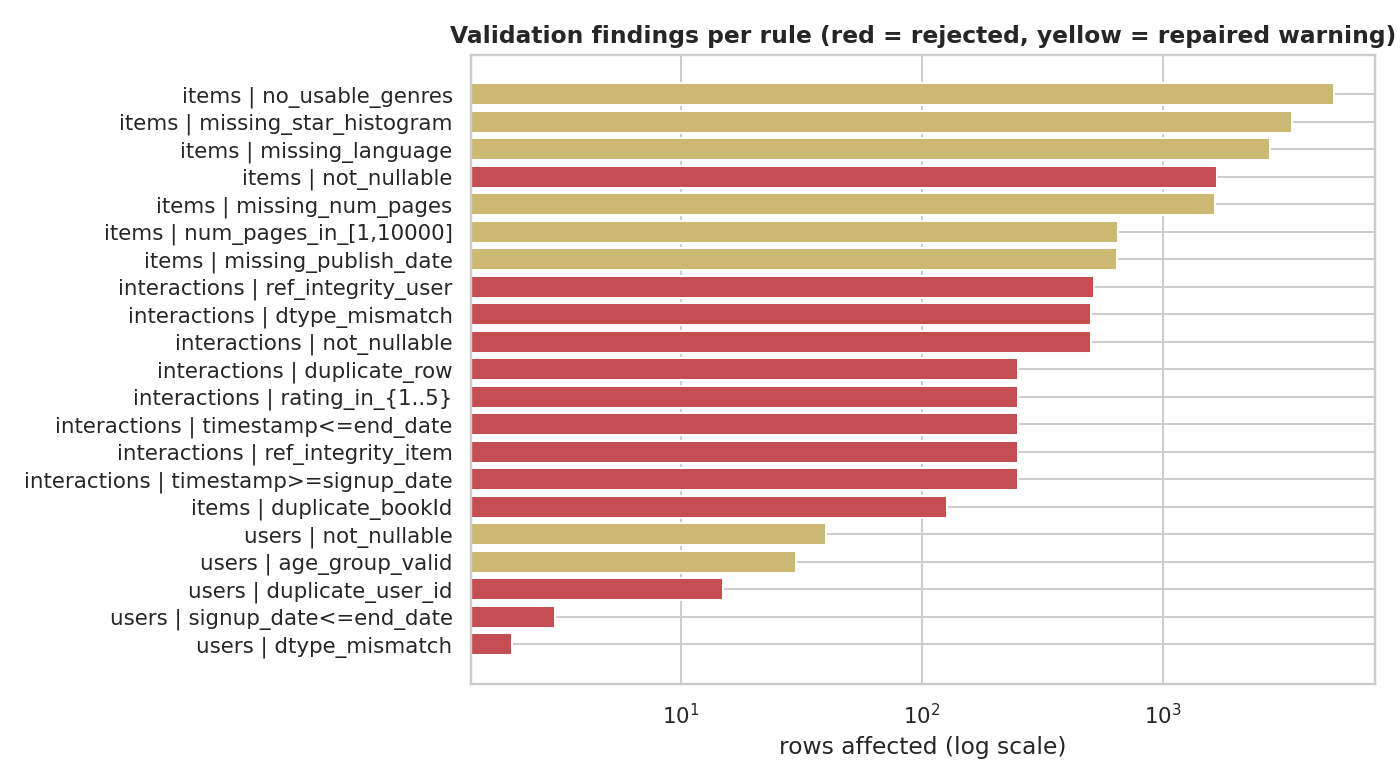

Example rejected interaction rows (error dataset):


,interaction_id,user_id,item_id,rating,timestamp,error_reasons
0,I0109186,U02573,19096,4,2021-12-27 12:00:00,timestamp>=signup_date
1,I0111885,U03535,4675,5,2021-01-10 12:00:00,timestamp>=signup_date
2,I0007048,<NA>,4670,5,2024-06-20 23:02:00,not_nullable
3,I0111254,<NA>,706,5,2021-10-31 00:00:56,not_nullable
4,I0018353,<NA>,17663,4,2024-04-01 00:48:26,not_nullable


HTML validation report -> /kaggle/working/recommendation-pipeline/reports/data_validation_report.html


In [17]:
validate = load("src.validation.validate")
print(validate.run(BASE, CFG))

vr = json.loads((BASE / "reports/validation_report.json").read_text())
display(pd.DataFrame({t: {k: v for k, v in d.items() if k != "rules"} for t, d in vr.items()}).T)
error_log = pd.read_csv(BASE / "data/errors/validation_error_log.csv")
display(error_log.groupby(["table", "rule", "column", "severity"]).size().rename("rows").to_frame())

# ---- detection check: did the validators find what the simulator injected?
cmp = pd.read_csv(BASE / "reports/injection_detection_check.csv", index_col=0); display(cmp)
print("Notes: (1) 'orphan user_id' detected > injected because interactions of users rejected for an invalid signup_date also become orphans (cascade).\n"
      "       (2) 'timestamp before signup' can be 1 lower because a row whose user was rejected has no signup date to compare with - it is rejected as an orphan instead.")
display(Image(filename=str(figures.validation_figure(BASE))))
print("Example rejected interaction rows (error dataset):"); display(pd.read_parquet(BASE / "data/errors/interactions_rejected.parquet").head(5))
print("HTML validation report ->", BASE / "reports/data_validation_report.html")

### g.2 Cleaning, standardisation & missing-value handling

- **Items:** drop rejected rows; parse genres (remove boilerplate), derive `category` (primary genre), `primary_author`; title / language standardised; `num_pages` (0 / missing) and `publish_year` imputed with the **category median** (with `*_imputed` flags so models can tell real from imputed); `has_series`, `num_awards` derived.
- **Users:** missing `country` / invalid `age_group` → `"Unknown"`; `signup_date` typed.
- **Interactions:** keep only validated rows, cast to `int` / `datetime`, drop repeated (user, item) pairs keeping the **latest**, sort chronologically.

In [18]:
%%writefile src/preparation/clean.py
"""Stage 3 - Data preparation: cleaning, standardisation, imputation (with *_imputed flags), de-duplication."""
from __future__ import annotations

import numpy as np
import pandas as pd

from src.common.genres import GenreParser
from src.common.log import get_logger
from src.config import Paths
from src.validation.validate import AGE_GROUPS, HIST_COLS, parse_interactions

log = get_logger("preparation")


def _good_rows(error_log: pd.DataFrame, table: str, n: int) -> np.ndarray:
    rejected = error_log.loc[(error_log.table == table) & (error_log.severity == "reject"), "row_index"].unique()
    return np.setdiff1d(np.arange(n), rejected)


def clean_items(items_raw, good, parser, end_year):
    ic = items_raw.iloc[good].copy()
    ic["genres_list"] = ic["genres"].map(parser.parse)
    ic["category"] = ic["genres_list"].map(parser.primary).fillna("Unknown")
    ic["genres"] = ic["genres_list"].map("|".join)
    ic["title"] = ic["title"].str.strip()
    ic["primary_author"] = ic["author"].fillna("Unknown").str.split(",").str[0].str.strip()
    ic["language"] = ic["language"].fillna("Unknown").str.strip().str.title()
    ic["num_pages_imputed"] = ic["num_pages"].isna() | (ic["num_pages"] < 1)
    ic["num_pages"] = ic["num_pages"].where(~ic["num_pages_imputed"])
    ic["num_pages"] = ic["num_pages"].fillna(ic.groupby("category")["num_pages"].transform("median")).fillna(ic["num_pages"].median()).round()
    yr = ic["first_publish_date"].str.extract(r"(\d{4})")[0].fillna(ic["publish_date"].str.extract(r"(\d{4})")[0]).astype(float)
    yr = yr.where(yr.between(1000, end_year))
    ic["publish_year_imputed"] = yr.isna()
    ic["publish_year"] = yr.fillna(yr.groupby(ic["category"]).transform("median")).fillna(yr.median()).astype(int)
    ic["has_series"] = ic["series"].notna()
    ic["num_awards"] = ic["awards"].fillna("").map(lambda s: len([a for a in s.split(",") if a.strip()]))
    ic["n_genres"] = ic["genres_list"].map(len)
    out = ic.rename(columns={"bookId": "item_id", "avg_rating": "gr_avg_rating", "num_ratings": "gr_num_ratings"})
    out["gr_log_num_ratings"] = np.log1p(out["gr_num_ratings"])
    keep = ["item_id", "title", "primary_author", "category", "genres", "n_genres", "language", "num_pages", "num_pages_imputed", "publish_year",
            "publish_year_imputed", "has_series", "num_awards", "gr_avg_rating", "gr_num_ratings", "gr_log_num_ratings"] + HIST_COLS
    out = out[keep].reset_index(drop=True)
    out["item_id"] = out["item_id"].astype(int)
    return out


def clean_users(users_raw, good):
    uc = users_raw.iloc[good].copy()
    uc["signup_date"] = pd.to_datetime(uc["signup_date"], errors="coerce", format="%Y-%m-%d")
    uc["country"] = uc["country"].fillna("Unknown")
    uc["age_group"] = uc["age_group"].where(uc["age_group"].isin(AGE_GROUPS), "Unknown")
    return uc.reset_index(drop=True)


def clean_interactions(inter_raw, good):
    xt = parse_interactions(inter_raw)
    ic = xt.iloc[good][["interaction_id", "user_id", "item_id", "rating", "timestamp"]].copy()
    ic["item_id"] = ic["item_id"].astype(int)
    ic["rating"] = ic["rating"].astype(int)
    before = len(ic)
    ic = ic.sort_values("timestamp").drop_duplicates(["user_id", "item_id"], keep="last").reset_index(drop=True)
    return ic, before - len(ic)


def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    items_raw = pd.read_csv(P.raw / "items_raw.csv")
    users_raw = pd.read_csv(P.raw / "users_raw.csv", dtype=str)
    inter_raw = pd.read_csv(P.raw / "interactions_raw.csv", dtype=str)
    error_log = pd.read_csv(P.errors / "validation_error_log.csv")
    parser = GenreParser.fit(items_raw["genres"])

    items_clean = clean_items(items_raw, _good_rows(error_log, "items", len(items_raw)), parser, int(cfg["end_date"][:4]))
    users_clean = clean_users(users_raw, _good_rows(error_log, "users", len(users_raw)))
    inter_clean, n_repeat = clean_interactions(inter_raw, _good_rows(error_log, "interactions", len(inter_raw)))
    log.info(f"repeated (user,item) pairs removed (kept latest): {n_repeat}")
    for name, df in [("items_clean", items_clean), ("users_clean", users_clean), ("interactions_clean", inter_clean)]:
        df.to_parquet(P.processed / f"{name}.parquet", index=False)
        nulls = int(df.drop(columns=[c for c in df.columns if c.startswith("rated_")]).isna().sum().sum())
        log.info(f"{name:20s} {df.shape}  nulls (excl. optional star-histogram cols) = {nulls}")
    return {"items_clean": len(items_clean), "users_clean": len(users_clean), "interactions_clean": len(inter_clean), "repeated_pairs_removed": int(n_repeat)}

Writing src/preparation/clean.py


In [19]:
clean = load("src.preparation.clean")
print(clean.run(BASE, CFG))
items_clean = pd.read_parquet(BASE / "data/processed/items_clean.parquet")
print("share of imputed values  ->", items_clean[["num_pages_imputed", "publish_year_imputed"]].mean().round(3).to_dict())
display(items_clean.head(3))

[recsys.preparation] repeated (user,item) pairs removed (kept latest): 0
[recsys.preparation] items_clean          (19384, 21)  nulls (excl. optional star-histogram cols) = 0
[recsys.preparation] users_clean          (3995, 4)  nulls (excl. optional star-histogram cols) = 0
[recsys.preparation] interactions_clean   (123334, 5)  nulls (excl. optional star-histogram cols) = 0
{'items_clean': 19384, 'users_clean': 3995, 'interactions_clean': 123334, 'repeated_pairs_removed': 0}
share of imputed values  -> {'num_pages_imputed': 0.089, 'publish_year_imputed': 0.005}


,item_id,title,primary_author,category,genres,n_genres,language,num_pages,num_pages_imputed,publish_year,...,has_series,num_awards,gr_avg_rating,gr_num_ratings,gr_log_num_ratings,rated_1,rated_2,rated_3,rated_4,rated_5
0,1,Harry Potter and the Half-Blood Prince,J.K. Rowling,Fantasy,Fantasy|Young Adult|Fiction|Magic|Childrens|Ad...,10,English,652.0,False,2005,...,True,3,4.57,2553909.0,14.753136,13147.0,29020.0,174312.0,608825.0,1728605.0
1,2,Harry Potter and the Order of the Phoenix,J.K. Rowling,Fantasy,Fantasy|Young Adult|Fiction|Magic|Childrens|Ad...,10,English,870.0,False,2003,...,True,9,4.50,2631427.0,14.783037,16236.0,41738.0,231438.0,665628.0,1676387.0
2,3,Harry Potter and the Sorcerer's Stone,J.K. Rowling,Fantasy,Fantasy|Fiction|Young Adult|Magic|Childrens|Mi...,10,English,309.0,False,1997,...,True,28,4.48,7434783.0,15.821680,126344.0,147184.0,627803.0,1694206.0,4839246.0


### g.3 Time-based train / test split & g.4 derived datasets

A **random** split would leak the future into training. We cut at the **80th percentile of interaction time**: everything before is *train*, everything on/after is *test* (asserted leak-free in code). A temporal **validation fold** (last 15 % of train) is used for hyper-parameter tuning so the test set is touched only once.

Derived datasets — all computed from **train only**: a **user-activity summary** (counts, mean/std rating, positive ratio, active span, activity quartile), **item-popularity scores** (count, users, Bayesian-shrunk average rating, log-scaled popularity score and rank) and the sparse **user–item matrix** (CSR, explicit ratings).

In [20]:
%%writefile src/transformation/transform.py
"""Stage 4 - Transformation: leakage-free time-based split + derived datasets (all derived from TRAIN only)."""
from __future__ import annotations

import json

import numpy as np
import pandas as pd
import scipy.sparse as sp

from src.common.log import get_logger
from src.config import Paths

log = get_logger("transformation")


def time_split(inter_clean: pd.DataFrame, test_fraction: float, val_fraction: float):
    """train = before the (1 - test_fraction) time-quantile; validation fold = last val_fraction of train (by time)."""
    cutoff = inter_clean["timestamp"].quantile(1 - test_fraction)
    train = inter_clean[inter_clean["timestamp"] < cutoff].reset_index(drop=True)
    test = inter_clean[inter_clean["timestamp"] >= cutoff].reset_index(drop=True)
    val_cut = train["timestamp"].quantile(1 - val_fraction)
    train_fit = train[train["timestamp"] < val_cut].reset_index(drop=True)
    val = train[train["timestamp"] >= val_cut].reset_index(drop=True)
    assert train.timestamp.max() < test.timestamp.min(), "temporal leakage!"
    return cutoff, val_cut, train, test, train_fit, val


def derive_datasets(train, items_clean, users_clean, pos, prior):
    tr = (train.merge(items_clean[["item_id", "category"]], on="item_id", how="left")
               .merge(users_clean[["user_id", "age_group"]], on="user_id", how="left"))
    tr["is_pos"] = (tr["rating"] >= pos).astype(int)
    global_mean = tr["rating"].mean()

    ua = tr.groupby("user_id").agg(n_interactions=("rating", "size"), avg_rating=("rating", "mean"), rating_std=("rating", "std"),
                                   n_positive=("is_pos", "sum"), n_categories=("category", "nunique"),
                                   first_interaction=("timestamp", "min"), last_interaction=("timestamp", "max")).reset_index()
    ua["positive_ratio"] = ua["n_positive"] / ua["n_interactions"]
    ua["active_span_days"] = (ua["last_interaction"] - ua["first_interaction"]).dt.days
    ua["activity_segment"] = pd.qcut(ua["n_interactions"].rank(method="first"), 4, labels=["light", "medium", "active", "power"])

    ip = tr.groupby("item_id").agg(n_interactions=("rating", "size"), n_users=("user_id", "nunique"), n_positive=("is_pos", "sum"),
                                   avg_rating=("rating", "mean")).reset_index()
    ip["bayes_avg_rating"] = (prior * global_mean + ip["avg_rating"] * ip["n_interactions"]) / (prior + ip["n_interactions"])
    ip["popularity_score"] = np.log1p(ip["n_interactions"]) / np.log1p(ip["n_interactions"].max())
    ip["popularity_rank"] = ip["n_interactions"].rank(ascending=False, method="min").astype(int)
    ip = ip.merge(items_clean[["item_id", "title", "category"]], on="item_id", how="left").sort_values("popularity_rank")

    u_ids, i_ids = np.sort(train["user_id"].unique()), np.sort(train["item_id"].unique())
    u_map, i_map = {u: k for k, u in enumerate(u_ids)}, {i: k for k, i in enumerate(i_ids)}
    R = sp.csr_matrix((train["rating"].astype(float), (train["user_id"].map(u_map), train["item_id"].map(i_map))), shape=(len(u_ids), len(i_ids)))
    return ua, ip, R, u_ids, i_ids


def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    items_clean = pd.read_parquet(P.processed / "items_clean.parquet")
    users_clean = pd.read_parquet(P.processed / "users_clean.parquet")
    inter_clean = pd.read_parquet(P.processed / "interactions_clean.parquet")

    cutoff, val_cut, train, test, train_fit, val = time_split(inter_clean, cfg["test_fraction"], cfg["val_fraction"])
    cold_users, cold_items = set(test.user_id) - set(train.user_id), set(test.item_id) - set(train.item_id)
    info = dict(cutoff=str(cutoff), val_cut=str(val_cut), n_train=len(train), n_test=len(test), n_train_fit=len(train_fit), n_val=len(val),
                cold_start_users=len(cold_users), test_users=int(test.user_id.nunique()), cold_items=len(cold_items), test_items=int(test.item_id.nunique()))
    log.info(f"cutoff {cutoff} | validation cut {val_cut}")
    log.info(f"train {len(train):,} | test {len(test):,} | (train_fit {len(train_fit):,} / val {len(val):,})")
    log.info(f"test users never seen in train (cold-start): {len(cold_users)} of {info['test_users']} | test items unseen in train: {len(cold_items)} of {info['test_items']}")
    train.to_parquet(P.processed / "train.parquet", index=False)
    test.to_parquet(P.processed / "test.parquet", index=False)

    ua, ip, R, u_ids, i_ids = derive_datasets(train, items_clean, users_clean, cfg["positive_threshold"], cfg["bayes_prior"])
    sp.save_npz(P.processed / "user_item_matrix_train.npz", R)
    pd.DataFrame({"user_id": u_ids}).to_parquet(P.processed / "matrix_users.parquet")
    pd.DataFrame({"item_id": i_ids}).to_parquet(P.processed / "matrix_items.parquet")
    ua.to_parquet(P.processed / "user_activity_summary.parquet", index=False)
    ip.to_parquet(P.processed / "item_popularity.parquet", index=False)
    sparsity = 1 - R.nnz / (R.shape[0] * R.shape[1])
    info["sparsity"] = float(sparsity)
    (P.processed / "split_info.json").write_text(json.dumps(info, indent=2))
    log.info(f"user-item matrix: {R.shape[0]:,} users x {R.shape[1]:,} items | nnz={R.nnz:,} | sparsity={sparsity:.2%}")
    return {**info, "matrix_users": R.shape[0], "matrix_items": R.shape[1]}

Writing src/transformation/transform.py


[recsys.transformation] cutoff 2024-01-17 16:09:40.600000 | validation cut 2023-09-30 23:59:16.800000
[recsys.transformation] train 98,667 | test 24,667 | (train_fit 83,867 / val 14,800)
[recsys.transformation] test users never seen in train (cold-start): 179 of 3401 | test items unseen in train: 1 of 2907
[recsys.transformation] user-item matrix: 3,816 users x 2,999 items | nnz=98,667 | sparsity=99.14%


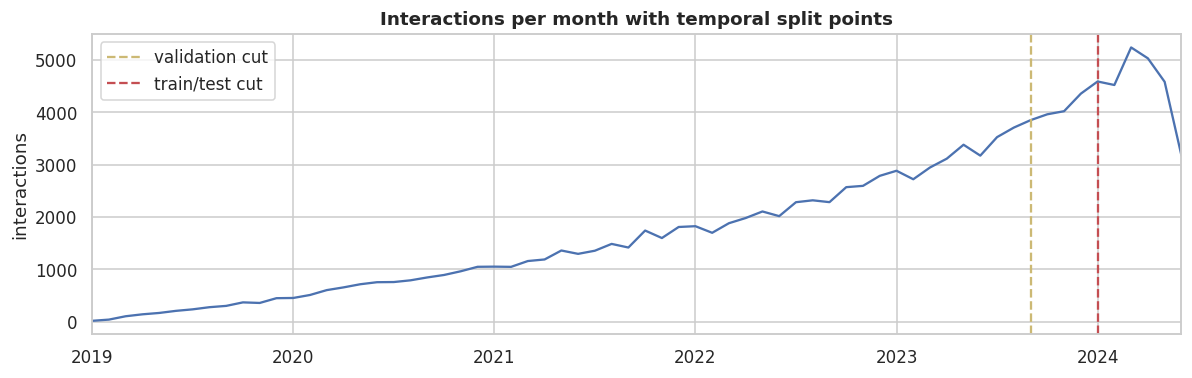

,user_id,n_interactions,avg_rating,rating_std,n_positive,n_categories,first_interaction,last_interaction,positive_ratio,active_span_days,activity_segment
0,U00001,67,4.417910,0.872983,56,18,2020-12-10 22:07:34,2023-12-31 20:41:07,0.835821,1115,power
1,U00002,16,4.312500,0.873212,14,5,2020-11-23 05:40:52,2023-09-20 13:16:32,0.875000,1031,medium
2,U00003,19,4.789474,0.535303,18,10,2020-06-02 16:06:12,2023-09-30 15:24:58,0.947368,1214,medium


,item_id,title,category,n_interactions,avg_rating,bayes_avg_rating,popularity_score
0,3,Harry Potter and the Sorcerer's Stone,Fantasy,367,4.640327,4.623065,1.000000
1,3356,Harry Potter y la piedra filosofal,Fantasy,326,4.610429,4.592850,0.980007
2,4255,Harry Potter and the Philosopher's Stone,Fantasy,315,4.603175,4.585451,0.974215
3,15871,Harry Potter à l'école des sorciers,Fantasy,304,4.648026,4.626932,0.968218
4,15868,Harry Potter y la piedra filosofal,Fantasy,284,4.633803,4.612257,0.956738


In [21]:
transform = load("src.transformation.transform")
info = transform.run(BASE, CFG)

inter_clean = pd.read_parquet(BASE / "data/processed/interactions_clean.parquet")
cutoff, val_cut = pd.Timestamp(info["cutoff"]), pd.Timestamp(info["val_cut"])
fig, ax = plt.subplots(figsize=(11, 3.6))
inter_clean.set_index("timestamp").resample("MS").size().plot(ax=ax, color="#4C72B0")
ax.axvline(val_cut, color="#CCB974", ls="--", label="validation cut"); ax.axvline(cutoff, color="#C44E52", ls="--", label="train/test cut")
ax.set(title="Interactions per month with temporal split points", xlabel="", ylabel="interactions"); ax.legend(); plt.tight_layout(); plt.show()

ua = pd.read_parquet(BASE / "data/processed/user_activity_summary.parquet"); ip = pd.read_parquet(BASE / "data/processed/item_popularity.parquet")
display(ua.head(3)); display(ip.head(5)[["item_id", "title", "category", "n_interactions", "avg_rating", "bayes_avg_rating", "popularity_score"]])

### g.5 Feature management

Features are computed **from the training window only** relative to a fixed reference date (`REF_DATE` = train/test cut-off), so there is no look-ahead. They are persisted as **Parquet**, documented in a **feature catalog**, and served through a small **`FeatureStore`** class. The *same* class and the *same* transformation code produce features for training rows and for prediction-time rows, which guarantees train/serve consistency — verified below with a parity test.

| Entity | Features |
|---|---|
| **User** | average rating, rating std, activity count, positive ratio, days since last interaction, tenure, #categories, preferred category, country, age group, activity segment |
| **Item** | avg rating (train), Bayesian avg rating, popularity (count + score), positive rate, days since last interaction, category, #genres, top audience age group, pages, publish year, Goodreads global rating / volume |
| **Interaction** | user's affinity to the item's category, is-preferred-category flag, item-vs-user rating gap, item age at interaction |

In [22]:
%%writefile src/features/feature_store.py
"""Stage 5 - Feature management.

Features are computed from the TRAINING window only, relative to a fixed reference date (REF_DATE = train/test cut-off),
so there is no look-ahead. They are persisted as Parquet, documented in a catalog and served through `FeatureStore`:
the SAME class and code path produce features for training rows and for prediction-time rows (train/serve consistency).
"""
from __future__ import annotations

import json
from pathlib import Path

import pandas as pd

from src.common.log import get_logger
from src.config import Paths

log = get_logger("features")

CATALOG_ROWS = [
    ("user_avg_rating", "user", "float", "Mean rating given by the user in the training window", "interactions.rating", "train only"),
    ("user_rating_std", "user", "float", "Std-dev of the user's ratings (0 if one rating)", "interactions.rating", "train only"),
    ("user_activity_count", "user", "int", "Number of training interactions", "interactions", "train only"),
    ("user_positive_ratio", "user", "float", "Share of the user's ratings >= 4", "interactions.rating", "train only"),
    ("user_days_since_last_interaction", "user", "float", "Days between the user's last train interaction and REF_DATE", "interactions.timestamp", "REF_DATE = train/test cut-off"),
    ("user_tenure_days", "user", "int", "Days between signup and REF_DATE", "users.signup_date", "REF_DATE"),
    ("user_n_categories", "user", "int", "# distinct item categories the user interacted with", "interactions x items.category", "train only"),
    ("user_preferred_category", "user", "category", "Most frequent category among the user's positive (>=4) ratings", "interactions x items.category", "train only"),
    ("country / age_group", "user", "category", "Demographics (after cleaning, 'Unknown' when missing)", "users", "static"),
    ("activity_segment", "user", "category", "Quartile of activity count: light/medium/active/power", "interactions", "train only"),
    ("item_avg_rating", "item", "float", "Mean rating received in the training window (global mean if cold)", "interactions.rating", "train only"),
    ("item_bayes_avg_rating", "item", "float", "Shrunk mean: (C*m + sum)/(C + n), C=20", "interactions.rating", "train only"),
    ("item_popularity", "item", "int", "# training interactions (0 for cold items)", "interactions", "train only"),
    ("item_popularity_score", "item", "float", "log1p(count)/log1p(max count) in [0,1]", "interactions", "train only"),
    ("item_positive_rate", "item", "float", "Share of the item's ratings >= 4", "interactions.rating", "train only"),
    ("item_days_since_last_interaction", "item", "float", "Days between the item's last train interaction and REF_DATE", "interactions.timestamp", "REF_DATE"),
    ("item_category", "item", "category", "Primary genre (first non-generic genre tag)", "items.genres", "static"),
    ("item_n_genres", "item", "int", "# distinct genre tags", "items.genres", "static"),
    ("item_top_audience_age_group", "item", "category", "Age group that rates the item most", "interactions x users", "train only"),
    ("item_num_pages / item_publish_year", "item", "int", "Pages and year (median-imputed per category when missing/invalid)", "items", "static"),
    ("item_gr_avg_rating / item_gr_log_num_ratings", "item", "float", "Goodreads global rating and log #ratings (external prior)", "items", "static"),
    ("user_category_affinity", "interaction", "float", "Share of the user's train interactions in the item's category", "user_category_share", "train only"),
    ("is_preferred_category", "interaction", "int", "1 if item category == user preferred category", "user x item features", "train only"),
    ("item_vs_user_avg_gap", "interaction", "float", "item_bayes_avg_rating - user_avg_rating", "user x item features", "train only"),
    ("item_age_years_at_interaction", "interaction", "int", "Interaction year - publication year", "interactions x items", "static"),
]


def _mode_first(df, key, col, name):
    return (df.groupby([key, col]).size().rename("c").reset_index()
              .sort_values([key, "c", col], ascending=[True, False, True]).drop_duplicates(key)
              .set_index(key)[col].rename(name))


def build_user_item_features(train, items_clean, users_clean, ua, ip, ref_date, pos):
    tr = (train.merge(items_clean[["item_id", "category"]], on="item_id", how="left")
               .merge(users_clean[["user_id", "age_group"]], on="user_id", how="left"))
    tr["is_pos"] = (tr["rating"] >= pos).astype(int)
    global_mean = tr["rating"].mean()

    # ---- user features
    pref = _mode_first(tr[tr.is_pos == 1], "user_id", "category", "user_preferred_category")
    uf = ua.set_index("user_id").join(pref)
    uf["user_preferred_category"] = uf["user_preferred_category"].fillna("Unknown")
    uf = uf.rename(columns={"avg_rating": "user_avg_rating", "rating_std": "user_rating_std", "n_interactions": "user_activity_count",
                            "positive_ratio": "user_positive_ratio", "n_categories": "user_n_categories"})
    uf["user_rating_std"] = uf["user_rating_std"].fillna(0)
    uf["user_days_since_last_interaction"] = (ref_date - uf["last_interaction"]).dt.total_seconds() / 86400
    uf = uf.join(users_clean.set_index("user_id")[["signup_date", "country", "age_group"]])
    uf["user_tenure_days"] = (ref_date - uf["signup_date"]).dt.days
    user_features = uf.reset_index()[["user_id", "user_avg_rating", "user_rating_std", "user_activity_count", "user_positive_ratio",
                                      "user_days_since_last_interaction", "user_tenure_days", "user_n_categories",
                                      "user_preferred_category", "country", "age_group", "activity_segment"]]
    user_features["activity_segment"] = user_features["activity_segment"].astype(str)

    # ---- item features
    audience = _mode_first(tr.dropna(subset=["age_group"]), "item_id", "age_group", "item_top_audience_age_group")
    last_seen = tr.groupby("item_id")["timestamp"].max()
    itf = items_clean.set_index("item_id")[["category", "n_genres", "num_pages", "publish_year", "gr_avg_rating", "gr_log_num_ratings"]]
    itf = itf.join(ip.set_index("item_id")[["n_interactions", "avg_rating", "bayes_avg_rating", "popularity_score", "n_positive", "n_users"]])
    itf = itf.join(audience)
    itf["item_days_since_last_interaction"] = (ref_date - last_seen.reindex(itf.index)).dt.total_seconds() / 86400
    itf["item_popularity"] = itf["n_interactions"].fillna(0).astype(int)                 # cold items -> popularity 0
    itf["item_popularity_score"] = itf["popularity_score"].fillna(0.0)
    itf["item_avg_rating"] = itf["avg_rating"].fillna(global_mean)
    itf["item_bayes_avg_rating"] = itf["bayes_avg_rating"].fillna(global_mean)
    itf["item_positive_rate"] = (itf["n_positive"] / itf["n_interactions"]).fillna(0)
    itf["item_top_audience_age_group"] = itf["item_top_audience_age_group"].fillna("Unknown")
    itf = itf.rename(columns={"category": "item_category", "n_genres": "item_n_genres", "num_pages": "item_num_pages",
                              "publish_year": "item_publish_year", "gr_avg_rating": "item_gr_avg_rating", "gr_log_num_ratings": "item_gr_log_num_ratings"})
    item_features = itf.reset_index()[["item_id", "item_avg_rating", "item_bayes_avg_rating", "item_popularity", "item_popularity_score",
                                       "item_positive_rate", "item_days_since_last_interaction", "item_category", "item_n_genres",
                                       "item_top_audience_age_group", "item_num_pages", "item_publish_year", "item_gr_avg_rating", "item_gr_log_num_ratings"]]

    # ---- user x category share (used for interaction features at train AND prediction time)
    cat_share = tr.groupby(["user_id", "category"]).size().rename("n").reset_index()
    cat_share["user_category_share"] = cat_share["n"] / cat_share.groupby("user_id")["n"].transform("sum")
    return user_features, item_features, cat_share.drop(columns="n")


class FeatureStore:
    """Parquet-backed feature layer. Same code path for training frames and online / batch prediction."""

    def __init__(self, root):
        root = Path(root)
        self.users = pd.read_parquet(root / "user_features.parquet").set_index("user_id")
        self.items = pd.read_parquet(root / "item_features.parquet").set_index("item_id")
        self.cat_share = pd.read_parquet(root / "user_category_share.parquet")

    def get_user_features(self, user_ids, cols=None):
        out = self.users.reindex(user_ids)
        return out if cols is None else out[cols]

    def get_item_features(self, item_ids, cols=None):
        out = self.items.reindex(item_ids)
        return out if cols is None else out[cols]

    def build_interaction_features(self, inter):
        """`inter` needs user_id, item_id (and optionally timestamp)."""
        df = inter[["user_id", "item_id"] + (["timestamp"] if "timestamp" in inter else [])].copy()
        u = self.get_user_features(df["user_id"]).reset_index(drop=True)
        i = self.get_item_features(df["item_id"]).reset_index(drop=True)
        df = pd.concat([df.reset_index(drop=True), u, i], axis=1)
        df = df.merge(self.cat_share.rename(columns={"category": "item_category"}), on=["user_id", "item_category"], how="left")
        df["user_category_affinity"] = df["user_category_share"].fillna(0.0)
        df["is_preferred_category"] = (df["item_category"] == df["user_preferred_category"]).astype(int)
        df["item_vs_user_avg_gap"] = df["item_bayes_avg_rating"] - df["user_avg_rating"]
        if "timestamp" in df:
            df["item_age_years_at_interaction"] = df["timestamp"].dt.year - df["item_publish_year"]
        return df.drop(columns=["user_category_share"])


def feature_catalog() -> pd.DataFrame:
    return pd.DataFrame(CATALOG_ROWS, columns=["feature", "entity", "dtype", "description", "source", "leakage_guard"])


def write_catalog(P):
    cat = feature_catalog()
    cat.to_csv(P.reports / "feature_catalog.csv", index=False)
    with open(P.reports / "feature_catalog.md", "w") as f:
        f.write("| " + " | ".join(cat.columns) + " |\n|" + "---|" * cat.shape[1] + "\n")
        for r in cat.itertuples(index=False):
            f.write("| " + " | ".join(map(str, r)) + " |\n")
    return cat


def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    items_clean = pd.read_parquet(P.processed / "items_clean.parquet")
    users_clean = pd.read_parquet(P.processed / "users_clean.parquet")
    train = pd.read_parquet(P.processed / "train.parquet")
    test = pd.read_parquet(P.processed / "test.parquet")
    ua = pd.read_parquet(P.processed / "user_activity_summary.parquet")
    ip = pd.read_parquet(P.processed / "item_popularity.parquet")
    ref_date = pd.Timestamp(json.loads((P.processed / "split_info.json").read_text())["cutoff"])

    uf, itf, cat_share = build_user_item_features(train, items_clean, users_clean, ua, ip, ref_date, cfg["positive_threshold"])
    uf.to_parquet(P.features / "user_features.parquet", index=False)
    itf.to_parquet(P.features / "item_features.parquet", index=False)
    cat_share.to_parquet(P.features / "user_category_share.parquet", index=False)
    log.info(f"user_features {uf.shape} | item_features {itf.shape} | user_category_share {cat_share.shape}")

    fs = FeatureStore(P.features)
    train_feat = fs.build_interaction_features(train).assign(rating=train["rating"].to_numpy())
    test_feat = fs.build_interaction_features(test).assign(rating=test["rating"].to_numpy())
    train_feat.to_parquet(P.features / "interaction_features_train.parquet", index=False)
    test_feat.to_parquet(P.features / "interaction_features_test.parquet", index=False)
    cold = int(test_feat["user_avg_rating"].isna().sum())
    log.info(f"training frame {train_feat.shape} | test frame {test_feat.shape} (same code path, train-derived stats) | cold-start test rows: {cold}")
    cat = write_catalog(P)
    return {"n_user_features": uf.shape[1] - 1, "n_item_features": itf.shape[1] - 1, "catalog_rows": len(cat), "cold_start_test_rows": cold}

Writing src/features/feature_store.py


In [23]:
feature_store = load("src.features.feature_store")
print(feature_store.run(BASE, CFG))
catalog = pd.read_csv(BASE / "reports/feature_catalog.csv")
pd.set_option("display.max_colwidth", 80); display(catalog)
print("Catalog also written as Markdown ->", BASE / "reports/feature_catalog.md")

# ---- train/serve parity: rebuild interaction features for random training rows through the SAME FeatureStore and compare with the stored frame
fs = feature_store.FeatureStore(BASE / "data/features")
train = pd.read_parquet(BASE / "data/processed/train.parquet"); test = pd.read_parquet(BASE / "data/processed/test.parquet")
sample = train.sample(2000, random_state=SEED)
rebuilt = fs.build_interaction_features(sample).reset_index(drop=True)
stored = pd.read_parquet(BASE / "data/features/interaction_features_train.parquet").iloc[sample.index].reset_index(drop=True)
pd.testing.assert_frame_equal(rebuilt, stored[rebuilt.columns], check_dtype=False)
print("train/serve parity test PASSED: 2,000 random rows rebuilt via FeatureStore are identical to the stored training features")
display(fs.build_interaction_features(test.head(3)).T.head(25))

[recsys.features] user_features (3816, 12) | item_features (19384, 14) | user_category_share (28390, 3)
[recsys.features] training frame (98667, 32) | test frame (24667, 32) (same code path, train-derived stats) | cold-start test rows: 5887
{'n_user_features': 11, 'n_item_features': 13, 'catalog_rows': 25, 'cold_start_test_rows': 5887}


,feature,entity,dtype,description,source,leakage_guard
0,user_avg_rating,user,float,Mean rating given by the user in the training window,interactions.rating,train only
1,user_rating_std,user,float,Std-dev of the user's ratings (0 if one rating),interactions.rating,train only
2,user_activity_count,user,int,Number of training interactions,interactions,train only
3,user_positive_ratio,user,float,Share of the user's ratings >= 4,interactions.rating,train only
4,user_days_since_last_interaction,user,float,Days between the user's last train interaction and REF_DATE,interactions.timestamp,REF_DATE = train/test cut-off
5,user_tenure_days,user,int,Days between signup and REF_DATE,users.signup_date,REF_DATE
6,user_n_categories,user,int,# distinct item categories the user interacted with,interactions x items.category,train only
7,user_preferred_category,user,category,Most frequent category among the user's positive (>=4) ratings,interactions x items.category,train only
8,country / age_group,user,category,"Demographics (after cleaning, 'Unknown' when missing)",users,static
9,activity_segment,user,category,Quartile of activity count: light/medium/active/power,interactions,train only


Catalog also written as Markdown -> /kaggle/working/recommendation-pipeline/reports/feature_catalog.md
train/serve parity test PASSED: 2,000 random rows rebuilt via FeatureStore are identical to the stored training features


,0,1,2
user_id,U03941,U00629,U03987
item_id,1956,2975,11130
timestamp,2024-01-17 16:14:28,2024-01-17 16:33:53,2024-01-17 16:41:38
user_avg_rating,4.557692,4.238095,4.25
user_rating_std,0.694317,1.091089,0.874234
user_activity_count,104,21,36
user_positive_ratio,0.903846,0.857143,0.833333
user_days_since_last_interaction,0.036986,3.364093,2.6004
user_tenure_days,372,68,121
user_n_categories,23,6,8


## (h) Machine-Learning Portion

### h.1 Evaluation protocol

| Item | Definition |
|---|---|
| **Relevant item** | a *test-window* rating **≥ 4** for a book that exists in the training catalogue |
| **Candidate set** | every book seen in train, **minus** books the user already rated in train |
| **Evaluated users** | users with ≥ 1 train interaction **and** ≥ 1 relevant test item (cold-start users are reported separately and served by a fallback, see (i)) |
| **Precision@K / Recall@K / NDCG@K** | standard top-K ranking metrics, binary relevance |
| **Coverage@K** | share of the candidate catalogue that appears in *any* user's top-K list |
| **Diversity@K** | mean intra-list distance, `1 − cosine(genre-vector)` between every pair in a user's top-K list |
| **RMSE / MAE** | rating-prediction error on all test ratings of known users/items (only for models that predict ratings) |
| **Uncertainty** | 95 % bootstrap CI over users; *paired* bootstrap for differences between models |

K = **5 and 10**.

In [24]:
%%writefile src/evaluation/metrics.py
"""Evaluation protocol: ranking metrics (Precision / Recall / NDCG @K, Coverage, Diversity), rating metrics (RMSE, MAE)
and bootstrap confidence intervals.

Protocol
* relevant item  = a test-window rating >= 4 for a book that exists in the training catalogue
* candidates     = every book seen in train minus the books the user already rated in train
* evaluated users= users with >= 1 train interaction AND >= 1 relevant test item (cold-start users are reported, not scored)
* Coverage@K     = share of the candidate catalogue appearing in ANY user's top-K list
* Diversity@K    = mean intra-list distance, 1 - cosine(genre vector), over all pairs in a user's top-K list
"""
from __future__ import annotations

from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp

from src.common.genres import NON_CATEGORY


def build_vocab(items_clean: pd.DataFrame, top: int = 80):
    gcount = Counter(g for s in items_clean["genres"] for g in s.split("|") if g)
    vocab = [g for g, _ in gcount.most_common(top) if g not in NON_CATEGORY]
    return vocab


class RecData:
    """Index-mapped view of a (train, eval) pair: sparse matrices, relevance sets and genre vectors."""

    def __init__(self, train_df, eval_df, items_clean, pos=4, vocab=None):
        vocab = vocab or build_vocab(items_clean)
        v_idx = {g: k for k, g in enumerate(vocab)}
        self.vocab = vocab
        self.users, self.items = np.sort(train_df["user_id"].unique()), np.sort(train_df["item_id"].unique())
        self.u_map = {u: k for k, u in enumerate(self.users)}
        self.i_map = {i: k for k, i in enumerate(self.items)}
        self.n_users, self.n_items = len(self.users), len(self.items)
        self.tu, self.ti = train_df["user_id"].map(self.u_map).to_numpy(), train_df["item_id"].map(self.i_map).to_numpy()
        self.tr_rating = train_df["rating"].to_numpy(float)
        shape = (self.n_users, self.n_items)
        self.R = sp.csr_matrix((self.tr_rating, (self.tu, self.ti)), shape=shape)
        self.P = sp.csr_matrix(((self.tr_rating >= pos).astype(float), (self.tu, self.ti)), shape=shape)
        self.seen = sp.csr_matrix((np.ones(len(self.tu)), (self.tu, self.ti)), shape=shape)
        e = eval_df[eval_df["user_id"].isin(self.u_map) & eval_df["item_id"].isin(self.i_map)]
        self.eu, self.ei, self.er = e["user_id"].map(self.u_map).to_numpy(), e["item_id"].map(self.i_map).to_numpy(), e["rating"].to_numpy(float)
        m = self.er >= pos
        self.T = sp.csr_matrix((np.ones(m.sum()), (self.eu[m], self.ei[m])), shape=shape)
        self.eval_users = np.flatnonzero(np.asarray(self.T.sum(axis=1)).ravel() > 0)
        n_pos_all = int((eval_df["rating"] >= pos).sum())
        self.info = dict(n_train=len(train_df), n_users=self.n_users, n_items=self.n_items, n_eval_users=len(self.eval_users),
                         n_eval_rows=len(self.er), eval_positives_in_catalog=int(m.sum()), eval_positives_total=n_pos_all)
        by_id = items_clean.set_index("item_id")["genres"]
        G = np.zeros((self.n_items, len(vocab)), dtype=np.float32)
        for r, iid in enumerate(self.items):
            for g in by_id.at[iid].split("|"):
                if g in v_idx:
                    G[r, v_idx[g]] = 1
        self.G = G / np.maximum(np.linalg.norm(G, axis=1, keepdims=True), 1e-9)


def evaluate(model, d: RecData, ks=(5, 10), per_user=False):
    """Score every evaluated user against every candidate item and compute all metrics."""
    ks = list(ks)
    users = d.eval_users
    S = np.asarray(model.score(users), dtype=np.float64)
    S[d.seen[users].toarray() > 0] = -np.inf                       # never re-recommend seen items
    Kmax = max(ks)
    top = np.argpartition(-S, Kmax, axis=1)[:, :Kmax]
    top = np.take_along_axis(top, np.argsort(-np.take_along_axis(S, top, 1), axis=1), 1)
    rel = d.T[users].toarray() > 0
    n_rel = rel.sum(1)
    out, pu = {}, {}
    for K in ks:
        t = top[:, :K]
        hits = np.take_along_axis(rel, t, 1)
        disc = 1 / np.log2(np.arange(2, K + 2))
        ndcg = (hits * disc).sum(1) / np.cumsum(disc)[np.minimum(n_rel, K) - 1]
        Gt = d.G[t]
        sim = np.einsum("nkv,nlv->nkl", Gt, Gt)
        div = 1 - (sim.sum((1, 2)) - np.trace(sim, axis1=1, axis2=2)) / (K * (K - 1))
        prec, rec = hits.sum(1) / K, hits.sum(1) / n_rel
        out[f"Precision@{K}"], out[f"Recall@{K}"], out[f"NDCG@{K}"] = float(prec.mean()), float(rec.mean()), float(ndcg.mean())
        out[f"Coverage@{K}"] = len(np.unique(t)) / d.n_items
        out[f"Diversity@{K}"] = float(div.mean())
        pu[f"precision@{K}"], pu[f"recall@{K}"], pu[f"ndcg@{K}"] = prec, rec, ndcg
    if hasattr(model, "predict"):
        p = np.clip(model.predict(d.eu, d.ei), 1, 5)
        out["RMSE"] = float(np.sqrt(np.mean((p - d.er) ** 2)))
        out["MAE"] = float(np.mean(np.abs(p - d.er)))
    else:
        out["RMSE"] = out["MAE"] = float("nan")
    return (out, pu) if per_user else out


def bootstrap_ci(x, n_boot=2000, seed=0, alpha=0.05):
    """Mean and percentile CI of a per-user metric (resampling users)."""
    x = np.asarray(x, float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1)
    return float(x.mean()), float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2))


def paired_bootstrap(a, b, n_boot=2000, seed=0, alpha=0.05):
    """CI of mean(a - b) over the same users + share of resamples where a <= b (one-sided bootstrap p-value)."""
    d = np.asarray(a, float) - np.asarray(b, float)
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(1)
    return float(d.mean()), float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2)), float((means <= 0).mean())

Writing src/evaluation/metrics.py


In [25]:
metrics = load("src.evaluation.metrics")
from src.evaluation.metrics import RecData, evaluate
d_full = RecData(train, test, items_clean, POS)
display(pd.Series(d_full.info, name="value").to_frame())
print(f"-> {d_full.info['eval_positives_in_catalog']/d_full.info['eval_positives_total']:.1%} of test positives are in the train catalogue (rest are cold items, not scoreable)")

,value
n_train,98667
n_users,3816
n_items,2999
n_eval_users,3061
n_eval_rows,18778
eval_positives_in_catalog,15383
eval_positives_total,20256


-> 75.9% of test positives are in the train catalogue (rest are cold items, not scoreable)


### h.2 Models

0. **Random** – uniformly random unseen books; a sanity floor that any useful model must beat.
1. **Popularity baseline** – ranks books by the number of *positive* (≥ 4★) train ratings; rating prediction = shrunk item mean. Non-personalised.
2. **ALS (implicit)** – Hu-Koren-Volinsky matrix factorisation on positive implicit feedback.
3. **SVD (Surprise)** – biased matrix factorisation (FunkSVD) on explicit 1–5 ratings; used both for **rating prediction** (RMSE/MAE) and for **ranking** by predicted rating.
4. **ItemKNN** – neighbourhood collaborative filtering: shrunk cosine similarity between books on positive feedback, top-k neighbours.
5. **Content-based** – user genre profile (from positively rated books, IDF-weighted) matched against book genre vectors: uses the engineered *content* features and needs no other users.
6. **Hybrid** – standardised blend of ItemKNN + ALS + content + popularity prior; the blend weights are tuned on the validation fold.

Each model only stores NumPy / SciPy arrays, so it is trivially serialisable and portable.

In [26]:
%%writefile src/training/models.py
"""Recommender models. Every model stores only NumPy / SciPy arrays, so it is trivially serialisable and portable.

Interface:  fit(d) -> self   |   score(user_idx) -> (n_users x n_items) scores   |   optional predict(user_idx, item_idx) -> ratings
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import scipy.sparse as sp
from implicit.cpu.als import AlternatingLeastSquares
from surprise import SVD, Dataset, Reader

SEED = 42


def _z(S):
    """Row-wise standardisation so that scores of different models can be blended."""
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)


class RandomModel:
    name = "Random (sanity floor)"

    def __init__(self, seed=SEED):
        self.params = {"seed": seed}

    def fit(self, d):
        self.n_items = d.n_items
        self.rs = np.random.RandomState(self.params["seed"])
        return self

    def score(self, u):
        return self.rs.random_sample((len(u), self.n_items))


class PopularityModel:
    name = "Popularity (baseline)"

    def __init__(self, prior_strength=20):
        self.params = {"prior_strength": prior_strength}

    def fit(self, d):
        pos = np.asarray(d.P.sum(axis=0)).ravel()
        cnt = np.asarray(d.seen.sum(axis=0)).ravel()
        self.pop = pos + 1e-6 * cnt                                   # rank by # positive ratings, tie-break by total interactions
        mu, C = d.tr_rating.mean(), self.params["prior_strength"]
        self.item_mean = (C * mu + np.asarray(d.R.sum(axis=0)).ravel()) / (C + cnt)   # shrunk item mean -> rating prediction
        return self

    def score(self, u):
        return np.tile(self.pop, (len(u), 1))

    def predict(self, u, i):
        return self.item_mean[i]


class ALSModel:
    name = "ALS (implicit MF)"

    def __init__(self, factors=64, regularization=0.1, alpha=20.0, iterations=20):
        self.params = dict(factors=factors, regularization=regularization, alpha=alpha, iterations=iterations)

    def fit(self, d):
        m = AlternatingLeastSquares(factors=self.params["factors"], regularization=self.params["regularization"], alpha=self.params["alpha"],
                                    iterations=self.params["iterations"], random_state=SEED, calculate_training_loss=False)
        m.fit(d.P, show_progress=False)
        self.U, self.V = np.asarray(m.user_factors), np.asarray(m.item_factors)
        return self

    def score(self, u):
        return self.U[u] @ self.V.T


class SVDModel:
    name = "SVD (Surprise MF)"

    def __init__(self, n_factors=50, n_epochs=30, lr_all=0.005, reg_all=0.05):
        self.params = dict(n_factors=n_factors, n_epochs=n_epochs, lr_all=lr_all, reg_all=reg_all)

    def fit(self, d):
        df = pd.DataFrame({"u": d.users[d.tu], "i": d.items[d.ti], "r": d.tr_rating})
        ts = Dataset.load_from_df(df, Reader(rating_scale=(1, 5))).build_full_trainset()
        algo = SVD(random_state=SEED, **self.params)
        algo.fit(ts)
        ui = np.array([ts.to_inner_uid(u) for u in d.users])
        ii = np.array([ts.to_inner_iid(i) for i in d.items])
        self.pu, self.qi, self.bu, self.bi, self.mu = algo.pu[ui], algo.qi[ii], algo.bu[ui], algo.bi[ii], ts.global_mean
        return self

    def score(self, u):
        return self.mu + self.bu[u][:, None] + self.bi[None, :] + self.pu[u] @ self.qi.T

    def predict(self, u, i):
        return self.mu + self.bu[u] + self.bi[i] + (self.pu[u] * self.qi[i]).sum(1)


class ItemKNNModel:
    """Neighbourhood collaborative filtering: cosine similarity between books on positive feedback, top-k neighbours kept."""
    name = "ItemKNN (cosine CF)"

    def __init__(self, k=50, shrink=10.0):
        self.params = dict(k=k, shrink=shrink)

    def fit(self, d):
        P = d.P.astype(np.float64)
        co = (P.T @ P).toarray()
        norms = np.sqrt(np.diag(co))
        sim = co / (np.outer(norms, norms) + self.params["shrink"])
        np.fill_diagonal(sim, 0.0)
        k = min(self.params["k"], sim.shape[1] - 1)
        drop = np.argpartition(-sim, k, axis=1)[:, k:]                # everything except the k nearest neighbours
        np.put_along_axis(sim, drop, 0.0, axis=1)
        self.S = sp.csr_matrix(sim.astype(np.float32))
        self.P = d.P.tocsr()
        return self

    def score(self, u):
        return np.asarray((self.P[u] @ self.S).todense())


class ContentModel:
    """Content-based filtering: user genre profile (from positively rated books) vs. book genre vectors, IDF-weighted."""
    name = "Content-based (genres)"

    def __init__(self, tie_break=1e-3):
        self.params = {"tie_break": tie_break}

    def fit(self, d):
        self.G = d.G.astype(np.float32)
        df_g = (self.G > 0).sum(0)
        self.idf = np.log((self.G.shape[0] + 1) / (df_g + 1)).astype(np.float32) + 1.0
        prof = (d.P @ self.G) * self.idf
        self.prof = np.asarray(prof / np.maximum(np.linalg.norm(prof, axis=1, keepdims=True), 1e-9), dtype=np.float32)
        pop = np.log1p(np.asarray(d.seen.sum(0)).ravel())
        self.pop_z = (pop - pop.mean()) / (pop.std() + 1e-9)
        return self

    def score(self, u):
        return self.prof[u] @ (self.G * self.idf).T + self.params["tie_break"] * self.pop_z[None, :]


class HybridModel:
    """Hybrid = standardised ItemKNN score + w_als * ALS + w_content * content score + w_pop * popularity prior.

    Combines two collaborative signals (neighbourhood + latent factors) with the engineered genre content features and a
    popularity prior; blend weights are tuned on the temporal validation fold.
    """
    name = "Hybrid (ItemKNN + ALS + content)"

    def __init__(self, factors=32, regularization=0.1, alpha=10.0, k=100, shrink=50.0, w_als=1.0, w_content=0.25, w_pop=0.15):
        self.params = dict(factors=factors, regularization=regularization, alpha=alpha, k=k, shrink=shrink,
                           w_als=w_als, w_content=w_content, w_pop=w_pop)

    def fit(self, d):
        p = self.params
        self.als = ALSModel(p["factors"], p["regularization"], p["alpha"]).fit(d)
        self.knn = ItemKNNModel(p["k"], p["shrink"]).fit(d)
        self.content = ContentModel().fit(d)
        return self

    def score(self, u):
        p = self.params
        return (_z(self.knn.score(u)) + p["w_als"] * _z(self.als.score(u))
                + p["w_content"] * _z(self.content.score(u)) + p["w_pop"] * self.content.pop_z[None, :])

Writing src/training/models.py


In [27]:
models = load("src.training.models")
t0 = time.time(); r_pop = evaluate(models.PopularityModel().fit(d_full), d_full, CFG["ks"])
print(f"smoke test OK ({time.time()-t0:.1f}s)  Popularity NDCG@10 = {r_pop['NDCG@10']:.4f}")

smoke test OK (0.3s)  Popularity NDCG@10 = 0.0266


### h.3 Training, hyper-parameter tuning and MLflow tracking

`src/training/train.py` exposes **one callable per model** (`run_model(base, cfg, key)`), which is exactly what the orchestrator runs as one task per model. For each model:

1. hyper-parameters are tuned on the **temporal validation fold** (`train_fit → val`, never the test set); every trial is logged to **MLflow** as a *nested run* with its parameters and validation metrics (ALS and ItemKNN are selected on NDCG@10, SVD on RMSE — its natural objective; the Hybrid reuses the tuned ALS/ItemKNN parameters and tunes only the blend weights);
2. the winner is re-fitted on the full training window and evaluated **once** on the held-out test window;
3. parameters, metrics and the model artifact are logged to MLflow; metrics and per-user scores are saved to `reports/metrics/`.

In [28]:
%%writefile src/training/train.py
"""Stage 6 - Model training: one callable per model (= one orchestrator task each).

For each model
  1. hyper-parameters are tuned on a TEMPORAL validation fold (train_fit -> val); the test set is never touched while tuning,
  2. the model is re-fitted on the full training window and evaluated ONCE on the held-out test window,
  3. parameters, metrics (validation trials as nested runs) and the model artifact are logged to MLflow,
  4. metrics + per-user scores are saved to reports/metrics/ for the evaluation stage.
"""
from __future__ import annotations

import itertools
import json
import os
import re
import time

import joblib
import mlflow
import numpy as np
import pandas as pd

from src.common.log import get_logger
from src.config import Paths
from src.evaluation.metrics import RecData, build_vocab, evaluate
from src.training.models import (ALSModel, ContentModel, HybridModel, ItemKNNModel, PopularityModel, RandomModel, SEED, SVDModel)

log = get_logger("training")
EXPERIMENT = "goodreads-recsys"

# key -> (class, tuning grid, selection rule). The Hybrid reuses the tuned ALS + ItemKNN parameters and only tunes the blend weights.
REGISTRY = {
    "random":     dict(cls=RandomModel, grid=[], select=None),
    "popularity": dict(cls=PopularityModel, grid=[], select=None),
    "als":        dict(cls=ALSModel, select=("NDCG", "max"),
                       grid=[dict(factors=f, regularization=r, alpha=a) for f, r, a in itertools.product([32, 64], [0.01, 0.1], [10, 40])]),
    "svd":        dict(cls=SVDModel, select=("RMSE", "min"),      # SVD is selected on rating error (its natural objective)
                       grid=[dict(n_factors=f, reg_all=r) for f, r in itertools.product([20, 50], [0.02, 0.08])]),
    "itemknn":    dict(cls=ItemKNNModel, select=("NDCG", "max"),
                       grid=[dict(k=k, shrink=s) for k, s in itertools.product([30, 100], [10.0, 50.0])]),
    "content":    dict(cls=ContentModel, grid=[], select=None),
    "hybrid":     dict(cls=HybridModel, select=("NDCG", "max"),
                       grid=[dict(w_als=wa, w_content=wc, w_pop=wp) for wa, wc, wp in itertools.product([0.5, 1.0, 2.0], [0.0, 0.25], [0.0, 0.15])]),
}
ORDER = list(REGISTRY)
mlkey = lambda k: k.replace("@", "_at_").lower()


def setup_mlflow(P: Paths):
    mlflow.set_tracking_uri(f"sqlite:///{P.mlflow_db}")
    if mlflow.get_experiment_by_name(EXPERIMENT) is None:
        mlflow.create_experiment(EXPERIMENT, artifact_location=P.mlruns.resolve().as_uri())
    mlflow.set_experiment(EXPERIMENT)


def _load(P: Paths):
    items_clean = pd.read_parquet(P.processed / "items_clean.parquet")
    train = pd.read_parquet(P.processed / "train.parquet")
    test = pd.read_parquet(P.processed / "test.parquet")
    info = json.loads((P.processed / "split_info.json").read_text())
    return items_clean, train, test, info


def run_model(base, cfg, key: str) -> dict:
    P = Paths(base).ensure()
    spec = REGISTRY[key]
    cls, ks, pos = spec["cls"], cfg["ks"], cfg["positive_threshold"]
    Kmax = max(ks)
    items_clean, train, test, info = _load(P)
    vocab = build_vocab(items_clean)
    d_full = RecData(train, test, items_clean, pos, vocab)
    setup_mlflow(P)
    np.random.seed(SEED)

    base_params = {}
    if key == "hybrid":                                    # depends on the ALS and ItemKNN tasks: reuse their tuned parameters
        for dep in ("als", "itemknn"):
            base_params.update(json.loads((P.metrics / f"{dep}.json").read_text())["best_params"])
    tags = {"pipeline_mode": os.environ.get("RECSYS_RUN_MODE", "interactive"), "pipeline_run_id": os.environ.get("RECSYS_RUN_ID", "-"), "model_key": key}

    with mlflow.start_run(run_name=f"train_{key}", tags=tags) as parent:
        tuning, best = [], {}
        if spec["grid"]:
            val_cut = pd.Timestamp(info["val_cut"])
            train_fit, val = train[train["timestamp"] < val_cut], train[train["timestamp"] >= val_cut]
            d_fit = RecData(train_fit, val, items_clean, pos, vocab)
            mlflow.log_params({"tuning_fold": "temporal validation (last 15% of train)", "val_cut": str(val_cut), "n_val_eval_users": d_fit.info["n_eval_users"]})
            for p in spec["grid"]:
                with mlflow.start_run(run_name=f"{key}_" + "_".join(f"{k}{v}" for k, v in p.items()), nested=True, tags={"model_key": key}):
                    m = cls(**{**base_params, **p}).fit(d_fit)
                    res = evaluate(m, d_fit, ks)
                    mlflow.log_params({"model": key, **m.params})
                    mlflow.log_metrics({mlkey(k): v for k, v in res.items() if not np.isnan(v)})
                    tuning.append({**p, **{f"val_{k}": v for k, v in res.items() if k in (f"NDCG@{Kmax}", f"Recall@{Kmax}", f"Precision@{Kmax}", "RMSE")}})
            tdf = pd.DataFrame(tuning)
            metric, how = spec["select"]
            col = "val_RMSE" if metric == "RMSE" else f"val_NDCG@{Kmax}"
            row = tdf.sort_values(col, ascending=(how == "min")).iloc[0]
            best = {k: (type(v)(row[k]) if not isinstance(v, str) else v) for k, v in spec["grid"][0].items()}
            log.info(f"{key}: best on validation ({col}) -> {best}")

        final_params = {**base_params, **best}
        model = cls(**final_params)
        t0 = time.time(); model.fit(d_full); fit_s = time.time() - t0
        res, pu = evaluate(model, d_full, ks, per_user=True)
        mlflow.log_params({"model": model.name, **model.params, "split_cutoff": info["cutoff"], "positive_threshold": pos, "ks": str(ks),
                           **{f"data_{k}": v for k, v in d_full.info.items()}})
        mlflow.log_metrics({mlkey(k): v for k, v in res.items() if not np.isnan(v)})
        mlflow.log_metric("fit_seconds", fit_s)

        path = P.models / f"{re.sub(r'[^a-z0-9]+', '_', model.name.lower()).strip('_')}.joblib"
        joblib.dump(model, path)
        mlflow.log_artifact(str(path), artifact_path="model")
        out = dict(key=key, name=model.name, params=model.params, best_params=final_params if key != "hybrid" else {**base_params, **best},
                   metrics=res, fit_seconds=fit_s, tuning=tuning, mlflow_run_id=parent.info.run_id, model_path=str(path.relative_to(P.base)),
                   data_info=d_full.info)
        (P.metrics / f"{key}.json").write_text(json.dumps(out, indent=2, default=lambda o: None if (isinstance(o, float) and np.isnan(o)) else float(o)))
        np.savez_compressed(P.metrics / f"{key}_per_user.npz", user_ids=d_full.users[d_full.eval_users], **{k: v for k, v in pu.items()})
        log.info(f"{model.name:36s} fit {fit_s:5.1f}s | NDCG@{Kmax}={res[f'NDCG@{Kmax}']:.4f}  Recall@{Kmax}={res[f'Recall@{Kmax}']:.4f}  RMSE={res['RMSE']:.4f}")
    return {"model": model.name, f"NDCG@{Kmax}": res[f"NDCG@{Kmax}"], "fit_seconds": round(fit_s, 2), "best_params": best}

Writing src/training/train.py


In [29]:
T = load("src.training.train")
MODEL_OUT = {key: T.run_model(BASE, CFG, key) for key in T.ORDER}

2026/11/12 04:40:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/12 04:40:21 INFO mlflow.store.db.utils: Updating database tables


[recsys.training] Random (sanity floor)                fit   0.0s | NDCG@10=0.0028  Recall@10=0.0040  RMSE=nan
[recsys.training] Popularity (baseline)                fit   0.0s | NDCG@10=0.0266  Recall@10=0.0324  RMSE=0.9336
[recsys.training] als: best on validation (val_NDCG@10) -> {'factors': 32, 'regularization': 0.1, 'alpha': 10}
[recsys.training] ALS (implicit MF)                    fit   0.7s | NDCG@10=0.0365  Recall@10=0.0458  RMSE=nan
[recsys.training] svd: best on validation (val_RMSE) -> {'n_factors': 20, 'reg_all': 0.08}
[recsys.training] SVD (Surprise MF)                    fit   1.1s | NDCG@10=0.0015  Recall@10=0.0024  RMSE=0.9317
[recsys.training] itemknn: best on validation (val_NDCG@10) -> {'k': 100, 'shrink': 50.0}
[recsys.training] ItemKNN (cosine CF)                  fit   0.5s | NDCG@10=0.0449  Recall@10=0.0567  RMSE=nan
[recsys.training] Content-based (genres)               fit   0.0s | NDCG@10=0.0112  Recall@10=0.0135  RMSE=nan
[recsys.training] hybrid: best on va

[recsys.training] Popularity (baseline)                fit   0.0s | NDCG@10=0.0266  Recall@10=0.0324  RMSE=0.9336


[recsys.training] als: best on validation (val_NDCG@10) -> {'factors': 32, 'regularization': 0.1, 'alpha': 10}


[recsys.training] ALS (implicit MF)                    fit   0.6s | NDCG@10=0.0365  Recall@10=0.0458  RMSE=nan


[recsys.training] svd: best on validation (val_RMSE) -> {'n_factors': 20, 'reg_all': 0.08}


... (2 outputs left out)

[recsys.training] ItemKNN (cosine CF)                  fit   0.4s | NDCG@10=0.0449  Recall@10=0.0567  RMSE=nan


[recsys.training] Content-based (genres)               fit   0.0s | NDCG@10=0.0112  Recall@10=0.0135  RMSE=nan


[recsys.training] hybrid: best on validation (val_NDCG@10) -> {'w_als': 2.0, 'w_content': 0.25, 'w_pop': 0.15}


[recsys.training] Hybrid (ItemKNN + ALS + content)     fit   1.0s | NDCG@10=0.0442  Recall@10=0.0550  RMSE=nan


In [30]:
runs = {k: json.loads((BASE / f"reports/metrics/{k}.json").read_text()) for k in T.ORDER}
for k in ["als", "svd", "itemknn", "hybrid"]:
    t = pd.DataFrame(runs[k]["tuning"]); col = "val_RMSE" if k == "svd" else "val_NDCG@10"
    print(f"--- {runs[k]['name']}: validation-fold tuning trials (best first)  | selected: {runs[k]['best_params']}")
    display(t.sort_values(col, ascending=(k == "svd")).round(4).reset_index(drop=True))

--- ALS (implicit MF): validation-fold tuning trials (best first)  | selected: {'factors': 32, 'regularization': 0.1, 'alpha': 10}


,factors,regularization,alpha,val_Precision@10,val_Recall@10,val_NDCG@10,val_RMSE
0,32,0.10,10,0.0154,0.0422,0.0317,NaN
1,32,0.01,10,0.0153,0.0425,0.0316,NaN
2,32,0.01,40,0.0150,0.0376,0.0282,NaN
3,32,0.10,40,0.0147,0.0373,0.0278,NaN
4,64,0.01,10,0.0120,0.0344,0.0235,NaN
5,64,0.10,10,0.0121,0.0345,0.0234,NaN
6,64,0.01,40,0.0117,0.0308,0.0225,NaN
7,64,0.10,40,0.0113,0.0303,0.0222,NaN


--- SVD (Surprise MF): validation-fold tuning trials (best first)  | selected: {'n_factors': 20, 'reg_all': 0.08}


,n_factors,reg_all,val_Precision@10,val_Recall@10,val_NDCG@10,val_RMSE
0,20,0.08,0.0011,0.0034,0.0021,0.9397
1,50,0.08,0.0010,0.0020,0.0013,0.9421
2,20,0.02,0.0015,0.0048,0.0030,0.9454
3,50,0.02,0.0017,0.0046,0.0027,0.9525


--- ItemKNN (cosine CF): validation-fold tuning trials (best first)  | selected: {'k': 100, 'shrink': 50.0}


,k,shrink,val_Precision@10,val_Recall@10,val_NDCG@10,val_RMSE
0,100,50.0,0.0179,0.0482,0.0346,NaN
1,100,10.0,0.0169,0.0464,0.0334,NaN
2,30,10.0,0.0168,0.0448,0.0331,NaN
3,30,50.0,0.0173,0.0455,0.0327,NaN


--- Hybrid (ItemKNN + ALS + content): validation-fold tuning trials (best first)  | selected: {'factors': 32, 'regularization': 0.1, 'alpha': 10, 'k': 100, 'shrink': 50.0, 'w_als': 2.0, 'w_content': 0.25, 'w_pop': 0.15}


,w_als,w_content,w_pop,val_Precision@10,val_Recall@10,val_NDCG@10,val_RMSE
0,2.0,0.25,0.15,0.0189,0.0528,0.0382,NaN
1,2.0,0.00,0.15,0.0187,0.0525,0.0379,NaN
2,2.0,0.25,0.00,0.0188,0.0523,0.0378,NaN
3,2.0,0.00,0.00,0.0187,0.0521,0.0377,NaN
4,1.0,0.25,0.15,0.0189,0.0514,0.0376,NaN
5,1.0,0.00,0.15,0.0190,0.0515,0.0375,NaN
6,1.0,0.00,0.00,0.0189,0.0513,0.0374,NaN
7,1.0,0.25,0.00,0.0187,0.0501,0.0371,NaN
8,0.5,0.25,0.00,0.0189,0.0503,0.0371,NaN
9,0.5,0.00,0.00,0.0189,0.0502,0.0370,NaN


### h.4 Final comparative results (test window)
`src/evaluation/aggregate.py` collects the per-model metrics into one table, adds **bootstrap confidence intervals**, **paired significance tests** versus the popularity baseline (and Hybrid vs ItemKNN / ALS), the accuracy per user-activity segment, and logs a summary run with all report artifacts to MLflow.

In [31]:
%%writefile src/evaluation/aggregate.py
"""Stage 7 - Model evaluation: compare all trained models in one results table (+ uncertainty + significance tests)."""
from __future__ import annotations

import json

import mlflow
import numpy as np
import pandas as pd

from src.common.log import get_logger
from src.config import Paths
from src.evaluation.metrics import bootstrap_ci, paired_bootstrap
from src.training.train import EXPERIMENT, ORDER, mlkey, setup_mlflow

log = get_logger("evaluation")
BASELINE = "Popularity (baseline)"


def result_columns(ks):
    K = max(ks)
    return [f"{m}@{k}" for k in ks for m in ["Precision", "Recall", "NDCG"]] + [f"Coverage@{K}", f"Diversity@{K}", "RMSE", "MAE"]


def load_results(P: Paths):
    runs = [json.loads((P.metrics / f"{k}.json").read_text()) for k in ORDER if (P.metrics / f"{k}.json").exists()]
    return runs


def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    ks = cfg["ks"]; K = max(ks)
    runs = load_results(P)
    names = {r["key"]: r["name"] for r in runs}
    res_df = pd.DataFrame({r["name"]: {k: (np.nan if v is None else v) for k, v in r["metrics"].items()} for r in runs}).T[result_columns(ks)]
    res_df.index.name = "Model"
    res_df.to_csv(P.reports / "model_results.csv")

    # ---- uncertainty: bootstrap CI over evaluated users + paired tests vs. the popularity baseline / ALS
    pu = {r["name"]: np.load(P.metrics / f"{r['key']}_per_user.npz", allow_pickle=True) for r in runs}
    ci = []
    for n, z in pu.items():
        for m in ("precision", "recall", "ndcg"):
            mean, lo, hi = bootstrap_ci(z[f"{m}@{K}"])
            ci.append({"Model": n, "metric": f"{m.upper() if m == 'ndcg' else m.capitalize()}@{K}", "mean": mean, "ci_low": lo, "ci_high": hi})
    ci = pd.DataFrame(ci)
    ci.to_csv(P.reports / "model_results_ci.csv", index=False)
    sig = []
    pairs = [(n, BASELINE) for n in pu if n not in (BASELINE, names.get("random"))]
    if "hybrid" in names:
        pairs += [(names["hybrid"], names[k]) for k in ("itemknn", "als") if k in names]
    for a, b in pairs:
        diff, lo, hi, p = paired_bootstrap(pu[a][f"ndcg@{K}"], pu[b][f"ndcg@{K}"])
        sig.append({"model": a, "versus": b, f"delta_NDCG@{K}": diff, "ci_low": lo, "ci_high": hi, "bootstrap_p(delta<=0)": p, "significant_95": bool(lo > 0 or hi < 0)})
    sig = pd.DataFrame(sig)
    sig.to_csv(P.reports / "significance_tests.csv", index=False)

    # ---- accuracy by user-activity segment
    seg = pd.read_parquet(P.features / "user_features.parquet").set_index("user_id")["activity_segment"]
    some = next(iter(pu.values()))
    seg_df = (pd.DataFrame({n: z[f"ndcg@{K}"] for n, z in pu.items()}, index=some["user_ids"]).join(seg).groupby("activity_segment").mean()
              .reindex(["light", "medium", "active", "power"]))
    seg_df.to_csv(P.reports / "ndcg_by_segment.csv")

    personalised = [n for n in res_df.index if n not in (names.get("random"), BASELINE) and not np.isnan(res_df.loc[n, f"NDCG@{K}"])]
    best = res_df.loc[personalised, f"NDCG@{K}"].idxmax()

    # ---- MLflow summary run (artifacts of the whole pipeline)
    setup_mlflow(P)
    import os
    with mlflow.start_run(run_name="evaluation_summary", tags={"pipeline_mode": os.environ.get("RECSYS_RUN_MODE", "interactive"), "pipeline_run_id": os.environ.get("RECSYS_RUN_ID", "-")}):
        mlflow.log_params({"best_model": best, "n_models": len(res_df), "ks": str(ks)})
        mlflow.log_metrics({f"best_{mlkey(f'NDCG@{K}')}": float(res_df.loc[best, f"NDCG@{K}"])})
        for f in ["reports/validation_report.json", "reports/feature_catalog.csv", "reports/model_results.csv", "reports/model_results_ci.csv",
                  "reports/significance_tests.csv", "configs/pipeline_config.json", "reports/data_validation_report.html"]:
            if (P.base / f).exists():
                mlflow.log_artifact(str(P.base / f))
    log.info(f"results table -> reports/model_results.csv | best personalised model by NDCG@{K}: {best} ({res_df.loc[best, f'NDCG@{K}']:.4f})")
    return {"best_model": best, f"best_NDCG@{K}": float(res_df.loc[best, f"NDCG@{K}"]), "n_models": len(res_df)}

Writing src/evaluation/aggregate.py


In [32]:
aggregate = load("src.evaluation.aggregate")
print(aggregate.run(BASE, CFG))

K = max(CFG["ks"]); cols = aggregate.result_columns(CFG["ks"])
res_df = pd.read_csv(BASE / "reports/model_results.csv", index_col=0)
styled = (res_df.style.format("{:.4f}", na_rep="n/a")
          .highlight_max(subset=[c for c in cols if c not in ("RMSE", "MAE")], color="#c7e9c0")
          .highlight_min(subset=["RMSE", "MAE"], color="#c7e9c0").set_caption(f"Test-window results (K = {CFG['ks']}; green = best in column)"))
display(styled)

base_name = "Popularity (baseline)"
lift = (res_df.drop(index=base_name, columns=["RMSE", "MAE"]) / res_df.loc[base_name].drop(["RMSE", "MAE"]) - 1) * 100
display(lift.round(1).style.format("{:+.1f}%").set_caption("Relative lift vs. popularity baseline"))

[recsys.evaluation] results table -> reports/model_results.csv | best personalised model by NDCG@10: ItemKNN (cosine CF) (0.0449)
{'best_model': 'ItemKNN (cosine CF)', 'best_NDCG@10': 0.044903219482368105, 'n_models': 7}


,Precision@5,Recall@5,NDCG@5,Precision@10,Recall@10,NDCG@10,Coverage@10,Diversity@10,RMSE,MAE
Model,,,,,,,,,,
Random (sanity floor),0.0016,0.0020,0.0020,0.0017,0.0040,0.0028,1.0000,0.8009,n/a,n/a
Popularity (baseline),0.0197,0.0201,0.0242,0.0154,0.0324,0.0266,0.0080,0.2960,0.9336,0.7540
ALS (implicit MF),0.0242,0.0248,0.0307,0.0214,0.0458,0.0365,0.2644,0.5886,n/a,n/a
SVD (Surprise MF),0.0008,0.0010,0.0009,0.0011,0.0024,0.0015,0.0263,0.8150,0.9317,0.7316
ItemKNN (cosine CF),0.0295,0.0300,0.0377,0.0260,0.0567,0.0449,0.1907,0.4050,n/a,n/a
Content-based (genres),0.0086,0.0091,0.0102,0.0069,0.0135,0.0112,0.7312,0.1168,n/a,n/a
Hybrid (ItemKNN + ALS + content),0.0303,0.0322,0.0377,0.0265,0.0550,0.0442,0.1871,0.4888,n/a,n/a


,Precision@5,Recall@5,NDCG@5,Precision@10,Recall@10,NDCG@10,Coverage@10,Diversity@10
Model,,,,,,,,
Random (sanity floor),-92.0%,-90.3%,-91.6%,-89.0%,-87.7%,-89.3%,+12395.8%,+170.5%
ALS (implicit MF),+23.3%,+23.5%,+26.5%,+39.3%,+41.1%,+37.1%,+3204.2%,+98.8%
SVD (Surprise MF),-95.7%,-94.8%,-96.3%,-92.6%,-92.7%,-94.4%,+229.2%,+175.3%
ItemKNN (cosine CF),+50.2%,+49.1%,+55.6%,+69.0%,+74.7%,+68.8%,+2283.3%,+36.8%
Content-based (genres),-56.1%,-54.8%,-58.0%,-55.4%,-58.4%,-57.8%,+9037.5%,-60.6%
Hybrid (ItemKNN + ALS + content),+53.8%,+60.5%,+55.6%,+72.0%,+69.7%,+66.0%,+2237.5%,+65.1%


In [33]:
ci = pd.read_csv(BASE / "reports/model_results_ci.csv")
display(ci.pivot(index="Model", columns="metric", values="mean").join(
        ci[ci.metric == f"NDCG@{K}"].set_index("Model")[["ci_low", "ci_high"]].add_prefix(f"NDCG@{K} ")).round(4).loc[res_df.index]
        .style.set_caption("Mean per-user metrics with 95% bootstrap CI for NDCG"))
sig = pd.read_csv(BASE / "reports/significance_tests.csv")
display(sig.round(4).style.set_caption(f"Paired bootstrap on per-user NDCG@{K}: CI of the difference (a CI that excludes 0 = significant at 95%)"))

,NDCG@10,Precision@10,Recall@10,NDCG@10 ci_low,NDCG@10 ci_high
Model,,,,,
Random (sanity floor),0.002800,0.001700,0.004000,0.001900,0.003900
Popularity (baseline),0.026600,0.015400,0.032400,0.023600,0.029600
ALS (implicit MF),0.036500,0.021400,0.045800,0.033100,0.040200
SVD (Surprise MF),0.001500,0.001100,0.002400,0.001000,0.002100
ItemKNN (cosine CF),0.044900,0.026000,0.056700,0.041200,0.048800
Content-based (genres),0.011200,0.006900,0.013500,0.009300,0.013300
Hybrid (ItemKNN + ALS + content),0.044200,0.026500,0.055000,0.040300,0.048000


,model,versus,delta_NDCG@10,ci_low,ci_high,bootstrap_p(delta<=0),significant_95
0,ALS (implicit MF),Popularity (baseline),0.009900,0.005800,0.014100,0.000000,True
1,SVD (Surprise MF),Popularity (baseline),-0.025100,-0.028100,-0.022100,1.000000,True
2,ItemKNN (cosine CF),Popularity (baseline),0.018300,0.015400,0.021200,0.000000,True
3,Content-based (genres),Popularity (baseline),-0.015400,-0.018500,-0.012300,1.000000,True
4,Hybrid (ItemKNN + ALS + content),Popularity (baseline),0.017500,0.013800,0.021300,0.000000,True
5,Hybrid (ItemKNN + ALS + content),ItemKNN (cosine CF),-0.000700,-0.003500,0.002100,0.689000,False
6,Hybrid (ItemKNN + ALS + content),ALS (implicit MF),0.007700,0.005200,0.010100,0.000000,True


### h.5 Visual comparison, diagnostics and a qualitative check

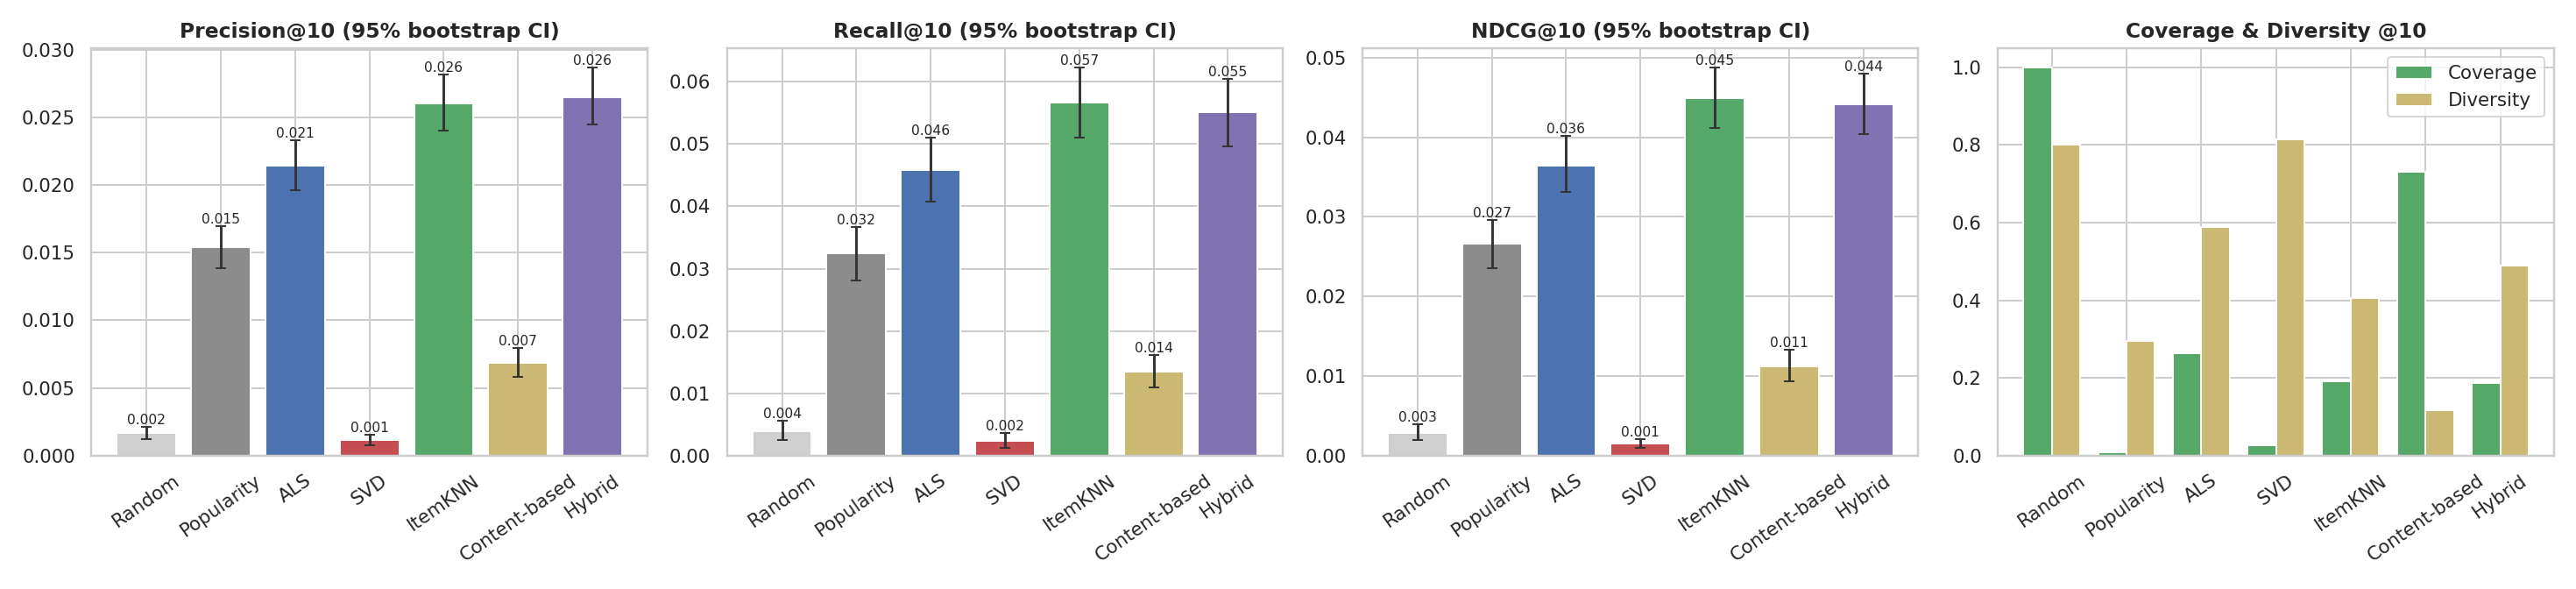

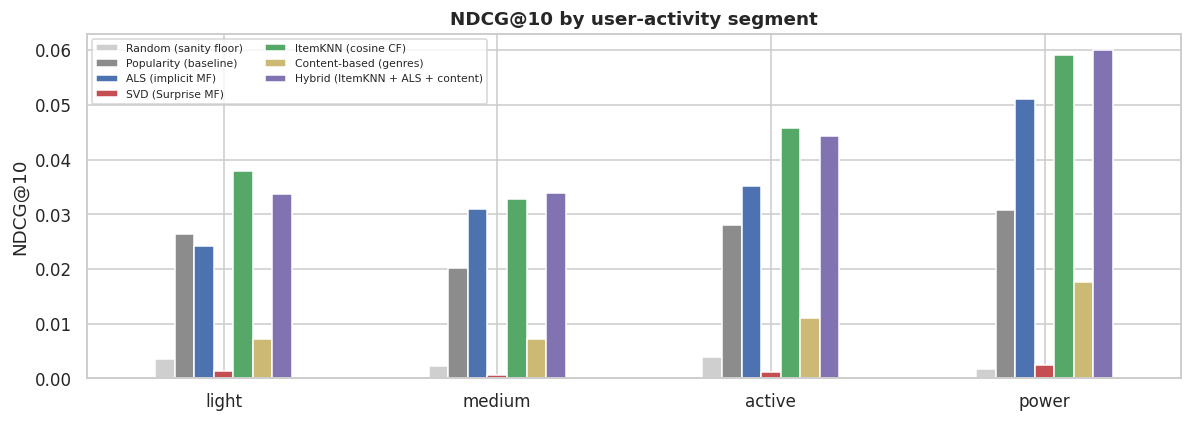

In [34]:
display(Image(filename=str(figures.results_figure(BASE))))

seg_df = pd.read_csv(BASE / "reports/ndcg_by_segment.csv", index_col=0)
ax = seg_df.plot(kind="bar", figsize=(11, 4), rot=0, color=figures.PALETTE); ax.set(title=f"NDCG@{K} by user-activity segment", xlabel="", ylabel=f"NDCG@{K}")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

In [35]:
# --- why does a rating-prediction model rank poorly? look at WHAT each model recommends
fitted = {r["name"]: joblib.load(BASE / r["model_path"]) for r in runs.values()}
pop_pct = pd.Series(np.asarray(d_full.seen.sum(axis=0)).ravel()).rank(pct=True).to_numpy()   # 1.0 = most popular
rows = []
for name, m in fitted.items():
    S = m.score(d_full.eval_users).astype(float); S[d_full.seen[d_full.eval_users].toarray() > 0] = -np.inf
    top10 = np.argpartition(-S, 10, axis=1)[:, :10]
    rows.append({"Model": name, "mean popularity percentile of top-10 items": pop_pct[top10].mean(),
                 "share of recs from the 10 % least-popular items": (pop_pct[top10] < 0.10).mean()})
display(pd.DataFrame(rows).set_index("Model").style.format("{:.3f}"))

,mean popularity percentile of top-10 items,share of recs from the 10 % least-popular items
Model,,
Random (sanity floor),0.496,0.107
Popularity (baseline),0.998,0.000
ALS (implicit MF),0.955,0.000
SVD (Surprise MF),0.413,0.000
ItemKNN (cosine CF),0.984,0.000
Content-based (genres),0.645,0.043
Hybrid (ItemKNN + ALS + content),0.976,0.000


In [36]:
# --- qualitative check: one (median-activity) user's history vs. recommendations
user_features = pd.read_parquet(BASE / "data/features/user_features.parquet")
def show_user(uid, K=5, which=("Popularity (baseline)", "ALS (implicit MF)", "ItemKNN (cosine CF)", "Hybrid (ItemKNN + ALS + content)")):
    ui = d_full.u_map[uid]
    hist = train[(train.user_id == uid) & (train.rating >= POS)].merge(items_clean[["item_id", "title", "category"]], on="item_id").sort_values("rating", ascending=False).head(5)
    print(f"User {uid} | preferred category: {user_features.set_index('user_id').at[uid, 'user_preferred_category']} | train interactions: {int(d_full.seen[ui].sum())}")
    print("Top-rated books in train:"); display(hist[["title", "category", "rating"]])
    relevant = set(d_full.items[d_full.T[ui].indices])
    for name in which:
        s = fitted[name].score(np.array([ui]))[0].copy(); s[d_full.seen[ui].indices] = -np.inf
        top = d_full.items[np.argsort(-s)[:K]]
        rec = items_clean.set_index("item_id").loc[top, ["title", "category"]].assign(hit=["HIT" if t in relevant else "" for t in top])
        print(f"\n{name}  -> top-{K}"); display(rec.reset_index(drop=True))
sample_user = d_full.users[d_full.eval_users[np.argsort(np.asarray(d_full.seen[d_full.eval_users].sum(1)).ravel())[len(d_full.eval_users) // 2]]]
show_user(sample_user)

User U03672 | preferred category: Christian | train interactions: 22
Top-rated books in train:


,title,category,rating
0,Anne Frank: The Diary Of A Young Girl,Classics,5
1,The Richest Man In Babylon,Economics,5
3,Redeeming Love,Christian Fiction,5
4,Bel Canto,Literary Fiction,5
5,I Know This Much Is True,Literary Fiction,5



Popularity (baseline)  -> top-5


,title,category,hit
0,Harry Potter and the Sorcerer's Stone,Fantasy,
1,Harry Potter y la piedra filosofal,Fantasy,
2,Harry Potter à l'école des sorciers,Fantasy,
3,Harry Potter and the Philosopher's Stone,Fantasy,
4,Harry Potter y la piedra filosofal,Fantasy,



ALS (implicit MF)  -> top-5


,title,category,hit
0,Max et les Maximonstres,Picture Books,HIT
1,Freakonomics: Un economista políticamente incorrecto explora el lado oculto ...,Economics,
2,Pride and Prejudice,Classics,
3,Las Uvas De La Ira,Classics,
4,Angels & Demons,Mystery,



ItemKNN (cosine CF)  -> top-5


,title,category,hit
0,The Hobbit,Fantasy,
1,The Kite Runner,Historical,
2,Freakonomics: Un economista políticamente incorrecto explora el lado oculto ...,Economics,
3,Harry Potter y la piedra filosofal,Fantasy,
4,The Hobbit,Fantasy,



Hybrid (ItemKNN + ALS + content)  -> top-5


,title,category,hit
0,Freakonomics: Un economista políticamente incorrecto explora el lado oculto ...,Economics,
1,The Kite Runner,Historical,
2,Max et les Maximonstres,Picture Books,HIT
3,The Hobbit,Fantasy,
4,The Hitchhiker's Guide to the Galaxy,Science Fiction,


In [37]:
# --- MLflow: everything that was tracked (top-level runs; every tuning trial is a nested run underneath)
T.setup_mlflow(Paths(BASE))
all_runs = mlflow.search_runs(experiment_names=[T.EXPERIMENT], output_format="pandas")
top_runs = all_runs[all_runs["tags.mlflow.parentRunId"].isna()]
print(f"{len(all_runs)} runs in experiment '{T.EXPERIMENT}' ({len(top_runs)} top-level, rest = nested tuning trials)")
show = [c for c in ["tags.mlflow.runName", "params.model", "metrics.ndcg_at_10", "metrics.recall_at_10", "metrics.fit_seconds", "tags.pipeline_mode"] if c in top_runs.columns]
display(top_runs[show].rename(columns=lambda c: c.split(".")[-1]).sort_values("runName").reset_index(drop=True))
all_runs.to_csv(BASE / "reports/mlflow_runs.csv", index=False)
print("To browse the MLflow UI locally:  mlflow ui --backend-store-uri sqlite:///mlflow.db")

36 runs in experiment 'goodreads-recsys' (8 top-level, rest = nested tuning trials)


,runName,model,ndcg_at_10,recall_at_10,fit_seconds,pipeline_mode
0,evaluation_summary,None,NaN,NaN,NaN,interactive
1,train_als,ALS (implicit MF),0.036478,0.045762,0.663267,interactive
2,train_content,Content-based (genres),0.011226,0.013503,0.007402,interactive
3,train_hybrid,Hybrid (ItemKNN + ALS + content),0.044159,0.055041,1.175520,interactive
4,train_itemknn,ItemKNN (cosine CF),0.044903,0.056669,0.522040,interactive
5,train_popularity,Popularity (baseline),0.026609,0.032443,0.001376,interactive
6,train_random,Random (sanity floor),0.002846,0.003980,0.000288,interactive
7,train_svd,SVD (Surprise MF),0.001499,0.002381,1.087422,interactive


To browse the MLflow UI locally:  mlflow ui --backend-store-uri sqlite:///mlflow.db


## (i) Serving & Reporting layer

### i.1 Prediction-time recommendations (with cold-start fallback)
`src/serving/recommend.py` turns the best personalised model into top-K lists. Prediction-time user context comes from the **same `FeatureStore`** used for training; users without any training history (cold start) receive a **popularity fallback** instead of an empty or random list. The pipeline's batch task writes top-10 lists for every user to `reports/top10_recommendations.parquet`.

In [38]:
%%writefile src/serving/recommend.py
"""Prediction-time layer: top-K recommendations from the best personalised model, features from the SAME FeatureStore,
and a popularity fallback for cold-start users (users with no training history)."""
from __future__ import annotations

import json

import joblib
import numpy as np
import pandas as pd

from src.common.log import get_logger
from src.config import Paths
from src.features.feature_store import FeatureStore
from src.training.train import ORDER, REGISTRY

log = get_logger("serving")


class Recommender:
    def __init__(self, base, model_key: str | None = None):
        self.P = Paths(base)
        self.cfg = json.loads((self.P.configs / "pipeline_config.json").read_text())
        K = max(self.cfg["ks"])
        meta = {k: json.loads((self.P.metrics / f"{k}.json").read_text()) for k in ORDER if (self.P.metrics / f"{k}.json").exists()}
        if model_key is None:                       # best personalised model by NDCG@K on the test window
            cand = {k: m["metrics"][f"NDCG@{K}"] for k, m in meta.items() if k not in ("random", "popularity", "svd")}
            model_key = max(cand, key=cand.get)
        self.model_key, self.model_name = model_key, meta[model_key]["name"]
        self.model = joblib.load(self.P.base / meta[model_key]["model_path"])
        self.popularity = joblib.load(self.P.base / meta["popularity"]["model_path"])
        self.items = pd.read_parquet(self.P.processed / "items_clean.parquet").set_index("item_id")
        train = pd.read_parquet(self.P.processed / "train.parquet")
        self.users, self.item_ids = np.sort(train["user_id"].unique()), np.sort(train["item_id"].unique())
        self.u_map = {u: k for k, u in enumerate(self.users)}
        import scipy.sparse as sp
        self.seen = sp.csr_matrix((np.ones(len(train)), (train["user_id"].map(self.u_map), train["item_id"].map({i: k for k, i in enumerate(self.item_ids)}))),
                                  shape=(len(self.users), len(self.item_ids)))
        self.fs = FeatureStore(self.P.features)

    def _format(self, idx, scores, source):
        iid = self.item_ids[idx]
        meta = self.items.loc[iid, ["title", "primary_author", "category"]].reset_index(drop=True)
        return pd.DataFrame({"rank": np.arange(1, len(iid) + 1), "item_id": iid, **meta.to_dict("list"), "score": scores, "source": source})

    def user_context(self, user_id) -> dict:
        """Prediction-time features of a user (identical definitions to the training features)."""
        f = self.fs.get_user_features([user_id])
        if f["user_avg_rating"].isna().all():
            return {"user_id": user_id, "cold_start": True}
        r = f.iloc[0]
        return {"user_id": user_id, "cold_start": False, "preferred_category": r["user_preferred_category"],
                "activity_count": int(r["user_activity_count"]), "avg_rating": round(float(r["user_avg_rating"]), 2), "segment": r["activity_segment"]}

    def recommend(self, user_id, k: int = 10) -> pd.DataFrame:
        if user_id not in self.u_map:               # cold start -> non-personalised popularity fallback
            s = self.popularity.pop.astype(float)
            top = np.argsort(-s)[:k]
            return self._format(top, s[top], "popularity fallback (cold start)")
        ui = self.u_map[user_id]
        s = self.model.score(np.array([ui]))[0].astype(float)
        s[self.seen[ui].indices] = -np.inf
        top = np.argsort(-s)[:k]
        return self._format(top, s[top], self.model_name)

    def batch(self, k: int = 10, chunk: int = 500) -> pd.DataFrame:
        out = []
        for a in range(0, len(self.users), chunk):
            ui = np.arange(a, min(a + chunk, len(self.users)))
            S = np.asarray(self.model.score(ui), dtype=float)
            S[self.seen[ui].toarray() > 0] = -np.inf
            top = np.argpartition(-S, k, axis=1)[:, :k]
            top = np.take_along_axis(top, np.argsort(-np.take_along_axis(S, top, 1), axis=1), 1)
            for r, u in enumerate(ui):
                out.append(pd.DataFrame({"user_id": self.users[u], "rank": np.arange(1, k + 1), "item_id": self.item_ids[top[r]]}))
        df = pd.concat(out, ignore_index=True)
        return df.merge(self.items[["title", "category"]].reset_index(), on="item_id", how="left")


def run(base, cfg) -> dict:
    """Batch prediction task: top-10 list for every user with a training history."""
    P = Paths(base).ensure()
    rec = Recommender(base)
    df = rec.batch(k=10)
    df.to_parquet(P.reports / "top10_recommendations.parquet", index=False)
    df.head(500).to_csv(P.reports / "top10_recommendations_sample.csv", index=False)
    log.info(f"batch recommendations ({rec.model_name}): {df['user_id'].nunique():,} users x 10 -> reports/top10_recommendations.parquet")
    return {"users": int(df["user_id"].nunique()), "model": rec.model_name}

Writing src/serving/recommend.py


In [39]:
recommend = load("src.serving.recommend")
rec_engine = recommend.Recommender(BASE)
print("serving model:", rec_engine.model_name)
print("known user  :", rec_engine.user_context(sample_user)); display(rec_engine.recommend(sample_user, 5)[["rank", "title", "category", "source"]])
cold_user = sorted(set(test.user_id) - set(train.user_id))[0]
print("cold-start  :", rec_engine.user_context(cold_user)); display(rec_engine.recommend(cold_user, 5)[["rank", "title", "category", "source"]])

serving model: ItemKNN (cosine CF)
known user  : {'user_id': 'U03672', 'cold_start': False, 'preferred_category': 'Christian', 'activity_count': 22, 'avg_rating': 4.27, 'segment': 'active'}


,rank,title,category,source
0,1,The Hobbit,Fantasy,ItemKNN (cosine CF)
1,2,The Kite Runner,Historical,ItemKNN (cosine CF)
2,3,Freakonomics: Un economista políticamente incorrecto explora el lado oculto ...,Economics,ItemKNN (cosine CF)
3,4,Harry Potter y la piedra filosofal,Fantasy,ItemKNN (cosine CF)
4,5,The Hobbit,Fantasy,ItemKNN (cosine CF)


cold-start  : {'user_id': 'U00011', 'cold_start': True}


,rank,title,category,source
0,1,Harry Potter and the Sorcerer's Stone,Fantasy,popularity fallback (cold start)
1,2,Harry Potter y la piedra filosofal,Fantasy,popularity fallback (cold start)
2,3,Harry Potter à l'école des sorciers,Fantasy,popularity fallback (cold start)
3,4,Harry Potter and the Philosopher's Stone,Fantasy,popularity fallback (cold start)
4,5,Harry Potter y la piedra filosofal,Fantasy,popularity fallback (cold start)


### i.2 Reporting
`src/reporting/final_report.py` assembles the **2–3 page final report (PDF)** — design decisions, tools, validation results, features, results table and chart, orchestration, limitations — *directly from the artefacts of the latest run*, so the report can never disagree with the numbers. `publish.py` is the pipeline's last task: it regenerates figures, the run manifest and the PDF.

In [40]:
%%writefile src/reporting/final_report.py
"""Builds the short final report (2-3 pages, PDF) from the artefacts of the latest run, so every number is traceable."""
from __future__ import annotations

import json
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
from reportlab.lib import colors
from reportlab.lib.enums import TA_JUSTIFY
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import cm
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import Image, KeepTogether, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

from src.config import Paths

_FONTS = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
pdfmetrics.registerFont(TTFont("DJ", str(_FONTS / "DejaVuSans.ttf")))
pdfmetrics.registerFont(TTFont("DJ-B", str(_FONTS / "DejaVuSans-Bold.ttf")))
pdfmetrics.registerFont(TTFont("DJ-I", str(_FONTS / "DejaVuSans-Oblique.ttf")))
pdfmetrics.registerFontFamily("DJ", normal="DJ", bold="DJ-B", italic="DJ-I", boldItalic="DJ-B")

NAVY = colors.HexColor("#1f3b73")
BODY = ParagraphStyle("body", fontName="DJ", fontSize=8.1, leading=10.6, alignment=TA_JUSTIFY, spaceAfter=3)
H1 = ParagraphStyle("h1", fontName="DJ-B", fontSize=15, leading=18, textColor=NAVY, spaceAfter=2)
H2 = ParagraphStyle("h2", fontName="DJ-B", fontSize=10.2, leading=12.5, textColor=NAVY, spaceBefore=6, spaceAfter=3)
SUB = ParagraphStyle("sub", fontName="DJ", fontSize=8, leading=10, textColor=colors.HexColor("#555555"), spaceAfter=4)
CELL = ParagraphStyle("cell", fontName="DJ", fontSize=6.8, leading=8.2)
CELLB = ParagraphStyle("cellb", parent=CELL, fontName="DJ-B")
BUL = ParagraphStyle("bul", parent=BODY, leftIndent=9, bulletIndent=0, spaceAfter=1.5)


def _table(rows, widths, header=True, align_right_from=None, zebra=True):
    data = [[Paragraph(str(c), CELLB if (header and i == 0) else CELL) for c in r] for i, r in enumerate(rows)]
    t = Table(data, colWidths=widths, repeatRows=1 if header else 0)
    st = [("GRID", (0, 0), (-1, -1), 0.3, colors.HexColor("#bbbbbb")), ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
          ("TOPPADDING", (0, 0), (-1, -1), 1.6), ("BOTTOMPADDING", (0, 0), (-1, -1), 1.6), ("LEFTPADDING", (0, 0), (-1, -1), 3), ("RIGHTPADDING", (0, 0), (-1, -1), 3)]
    if header:
        st.append(("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e6ecf7")))
    if zebra:
        st += [("BACKGROUND", (0, i), (-1, i), colors.HexColor("#f7f7f7")) for i in range(2, len(rows), 2)]
    t.setStyle(TableStyle(st))
    return t


def _img(path, width):
    from PIL import Image as PILImage
    w, h = PILImage.open(path).size
    return Image(str(path), width=width, height=width * h / w)


def build(base) -> Path:
    P = Paths(base)
    cfg = json.loads((P.configs / "pipeline_config.json").read_text()); K = max(cfg["ks"])
    val = json.loads((P.reports / "validation_report.json").read_text())
    split = json.loads((P.processed / "split_info.json").read_text())
    res = pd.read_csv(P.reports / "model_results.csv", index_col=0)
    sig = pd.read_csv(P.reports / "significance_tests.csv")
    cat = pd.read_csv(P.reports / "feature_catalog.csv")
    det = pd.read_csv(P.reports / "injection_detection_check.csv", index_col=0) if (P.reports / "injection_detection_check.csv").exists() else None
    # the most recent run that actually executed work (a pure cache-hit re-run says nothing about the pipeline's cost)
    run = None
    for rp in sorted(P.orchestration.glob("run_*.json")):
        r_ = json.loads(rp.read_text())
        if any(t_["status"] == "success" for t_ in r_["tasks"]):
            run = r_
    n_eval = json.loads((P.metrics / "popularity.json").read_text())["data_info"]["n_eval_users"]

    personalised = [n for n in res.index if not n.startswith(("Random", "Popularity")) and not np.isnan(res.loc[n, f"NDCG@{K}"])]
    best = res.loc[personalised, f"NDCG@{K}"].idxmax()
    base_n = "Popularity (baseline)"
    lift = res.loc[best, f"NDCG@{K}"] / res.loc[base_n, f"NDCG@{K}"] - 1
    hyb = next((n for n in res.index if n.startswith("Hybrid")), None)
    knn = next((n for n in res.index if n.startswith("ItemKNN")), None)
    out = P.reports / "final_report.pdf"
    doc = SimpleDocTemplate(str(out), pagesize=A4, leftMargin=1.6 * cm, rightMargin=1.6 * cm, topMargin=1.3 * cm, bottomMargin=1.2 * cm,
                            title="End-to-End Data Management Pipeline for a Recommendation System", author="DM4ML Assignment 2")
    W = A4[0] - 3.2 * cm
    S = []
    S.append(Paragraph("End-to-End Data Management Pipeline for a Book Recommendation System", H1))
    S.append(Paragraph("Data Management for Machine Learning - Assignment 2 - Final report", SUB))

    # ------------------------------------------------------------------ 1
    S.append(Paragraph("1. Problem and data", H2))
    S.append(Paragraph(
        f"An online book platform wants to recommend books a reader is likely to rate &ge; {cfg['positive_threshold']} in the <b>future</b>. The pipeline ingests user, item and "
        f"interaction data, validates it, prepares and transforms it, manages reusable features, trains and evaluates models and automates the whole workflow. "
        f"<b>Items</b> are real: the Goodreads books catalogue ({val['items']['rows']:,} rows). Because the file has no reader-level data, <b>users</b> "
        f"({val['users']['rows']:,} rows) and <b>interactions</b> ({val['interactions']['rows']:,} rows, timestamped 2019-2024) are <b>synthetic and documented</b>: "
        f"books are chosen proportionally to real popularity and taste match, and every rating is drawn from the book's <i>real</i> 1-5 star histogram. "
        f"About {cfg['fault_rate']:.0%} of the rows carry injected faults (duplicates, invalid ratings, orphan keys, bad timestamps) so that validation can be demonstrated "
        f"and verified against a ledger. Model scores therefore describe the simulator, <b>not</b> real Goodreads behaviour; the engineering is what transfers.", BODY))

    # ------------------------------------------------------------------ 2
    S.append(Paragraph("2. Pipeline design and tools", H2))
    rows = [["Stage", "Tool / module", "Key design decision"],
            ["Ingestion", "pandas, src/ingestion", "Raw extracts persisted as untouched CSV (like an upstream export); everything read as text so nothing is silently coerced."],
            ["Validation", "Pandera + custom rules, src/validation", "Rules have severity: <i>reject</i> (-> error dataset) or <i>warning</i> (repaired later). Users -> items -> interactions order enables referential-integrity checks."],
            ["Preparation", "pandas, src/preparation", "Category-median imputation with <i>_imputed</i> flags; genre boilerplate removed; repeated (user,item) pairs keep the latest."],
            ["Transformation", "scipy.sparse, src/transformation", f"Time-based split at the 80th time-percentile ({split['cutoff'][:10]}), asserted leak-free; 15 % temporal validation fold for tuning."],
            ["Feature mgmt", "Parquet + FeatureStore class", "Features computed from TRAIN only at a fixed REF_DATE; one class builds training and prediction features (train/serve consistency)."],
            ["Training", "implicit, Surprise, NumPy, MLflow", "7 models incl. a popularity baseline; every trial is a nested MLflow run; models are plain-array objects."],
            ["Evaluation", "src/evaluation", "P/R/NDCG@5,10, Coverage, Diversity, RMSE, MAE; bootstrap CIs and paired significance tests over users."],
            ["Orchestration", "Python DAG engine + Airflow DAG", "One task registry drives both; retries, quality gate, resume/caching, run log and DAG-run graph."]]
    S.append(_table(rows, [2.3 * cm, 4.3 * cm, W - 6.6 * cm]))
    arch = P.reports / "architecture_diagram.png"
    if arch.exists():
        S.append(Spacer(1, 4)); S.append(_img(arch, W * 0.86))

    # ------------------------------------------------------------------ 3
    S.append(Paragraph("3. Data validation and preparation", H2))
    r = [["Table", "Rows", "Rejected", "Warning rows", "Main findings"],
         ["users", f"{val['users']['rows']:,}", f"{val['users']['rejected_rows']:,}", f"{val['users']['warning_rows']:,}", "duplicate user_id, future / unparsable signup_date; missing country, invalid age_group repaired"],
         ["items (real)", f"{val['items']['rows']:,}", f"{val['items']['rejected_rows']:,}", f"{val['items']['warning_rows']:,}", "near-empty rows, duplicate bookId; missing genres / pages / star histogram"],
         ["interactions", f"{val['interactions']['rows']:,}", f"{val['interactions']['rejected_rows']:,}", f"{val['interactions']['warning_rows']:,}", "bad dtype / range / null ratings, bad or future timestamps, orphan keys, duplicates, pre-signup events"]]
    S.append(_table(r, [2.1 * cm, 1.4 * cm, 1.6 * cm, 1.9 * cm, W - 7.0 * cm]))
    ok_txt = ""
    if det is not None:
        ok_txt = f" The detection check confirms that <b>{int((det['match'] == 'OK').sum())} of {len(det)}</b> injected fault families were found."
    S.append(Paragraph(f"Rejected rows are written to <i>data/errors/</i> (CSV + Parquet) with the violated rules; the full log and an HTML report are kept in <i>reports/</i>.{ok_txt} "
                       f"Validation also exposed genuine problems of the real file. Referential integrity cascades: rejecting a user orphans all of that user's interactions, which is why validation order matters.", BODY))

    # ------------------------------------------------------------------ 4
    n = cat.groupby("entity").size().to_dict()
    S.append(Paragraph("4. Feature management", H2))
    S.append(Paragraph(f"The feature catalog ({len(cat)} documented entries: {n.get('user', 0)} user, {n.get('item', 0)} item, {n.get('interaction', 0)} interaction) lists name, type, definition, source and leakage guard "
                       f"(<i>reports/feature_catalog.csv|md</i>). Examples: user average rating, activity count, preferred category, days since last interaction; item popularity, Bayesian average rating, "
                       f"top audience age group; user-category affinity and item-vs-user rating gap. Cold-start users ({split['cold_start_users']} of {split['test_users']:,} test users) "
                       f"have no features by construction and are served a popularity fallback.", BODY))

    # ------------------------------------------------------------------ 5
    S.append(Paragraph("5. Models and results", H2))
    cols = [f"Precision@{K}", f"Recall@{K}", f"NDCG@{K}", f"Coverage@{K}", f"Diversity@{K}", "RMSE", "MAE"]
    t = [["Model"] + [c.replace("@", "@") for c in cols]]
    for nme in res.index:
        t.append([f"<b>{nme}</b>" if nme == best else nme] + ["n/a" if np.isnan(res.loc[nme, c]) else f"{res.loc[nme, c]:.4f}" for c in cols])
    S.append(_table(t, [5.0 * cm] + [(W - 5.0 * cm) / len(cols)] * len(cols)))
    S.append(Paragraph(f"<i>Test window, evaluated on {n_eval:,} users with at least one relevant test item; K = {K}; best personalised model in bold.</i>", SUB))
    txt = (f"<b>{best}</b> is the best ranker (NDCG@{K} {lift:+.0%} vs. the popularity baseline). ")
    if hyb and knn:
        h = sig[(sig.model == hyb) & (sig.versus == knn)]
        if len(h):
            tied = not bool(h["significant_95"].iloc[0])
            txt += (f"The hybrid is {'statistically tied with' if tied else 'significantly different from'} ItemKNN on NDCG@{K} (paired bootstrap 95 % CI "
                    f"[{h['ci_low'].iloc[0]:+.4f}, {h['ci_high'].iloc[0]:+.4f}]) but gives more diverse lists (diversity {res.loc[hyb, f'Diversity@{K}']:.2f} vs. {res.loc[knn, f'Diversity@{K}']:.2f}). ")
    svd = next((nme for nme in res.index if nme.startswith("SVD")), None)
    if svd:
        txt += (f"SVD improves rating error only marginally (RMSE {res.loc[svd, 'RMSE']:.3f} vs. {res.loc[base_n, 'RMSE']:.3f}) and, used as a ranker, falls below random: "
                f"rating accuracy and top-K usefulness are different objectives. Popularity covers {res.loc[base_n, f'Coverage@{K}']:.1%} of the catalogue, personalised models far more.")
    S.append(Paragraph(txt, BODY))
    fig = P.reports / "results_overview.png"
    if fig.exists():
        S.append(_img(fig, W))

    # ------------------------------------------------------------------ 6
    S.append(Paragraph("6. Orchestration and reproducibility", H2))
    if run:
        ok = sum(t_["status"] in ("success", "cached") for t_ in run["tasks"])
        S.append(Paragraph(f"The workflow has {len(run['tasks'])} tasks with explicit dependencies (ingest -> validate -> <b>quality gate</b> -> prepare -> transform -> features -> 7 training tasks -> evaluate -> batch recommend -> publish). "
                           f"Latest run <i>{run['run_id']}</i>: <b>{run['status']}</b>, {ok}/{len(run['tasks'])} tasks successful, {run['seconds']:.0f} s. "
                           f"The gate stops the pipeline (downstream tasks are <i>skipped</i>) if more than {cfg['max_reject_ratio']:.0%} of interaction rows are rejected; failed tasks are retried; "
                           f"<i>resume</i> mode skips tasks that already succeeded with an identical configuration. All seeds are fixed, and the metrics of the orchestrated run are compared with the "
                           f"stage-by-stage run in the notebook. The same task registry is exported as an Apache Airflow DAG (<i>dags/recommendation_pipeline_dag.py</i>).", BODY))
        g = P.reports / "orchestration_run.png"
        if g.exists():
            S.append(_img(g, W))
    else:
        S.append(Paragraph("Run the orchestrated workflow to populate this section.", BODY))

    # ------------------------------------------------------------------ 7
    S.append(Paragraph("7. Limitations and future work", H2))
    for b in ["<b>Simulated users / interactions:</b> conclusions about model ranking hold for this simulator; the pipeline itself transfers to real logs.",
              "<b>Editions:</b> different editions of one book have separate ids (e.g. several Harry Potter editions in the popularity list); entity resolution to a work id is needed in production.",
              "<b>Offline evaluation only:</b> one temporal split, no A/B test; absolute scores are low because the matrix is ~99 % sparse and only the future window is scored.",
              "<b>Content features</b> are used only through the genre profile in the hybrid; richer text / author embeddings, cold-start modelling and a hosted feature store / MLflow server are natural extensions."]:
        S.append(Paragraph(b, BUL, bulletText="\u2022"))
    doc.build(S)
    return out

Writing src/reporting/final_report.py


In [41]:
%%writefile src/reporting/publish.py
"""Final pipeline task: regenerate figures + PDF report + run manifest."""
from __future__ import annotations

import json
from datetime import datetime

import pandas as pd

from src.common.log import get_logger
from src.config import Paths
from src.reporting import architecture, figures, final_report

log = get_logger("reporting")


def write_manifest(P: Paths, cfg: dict):
    split = json.loads((P.processed / "split_info.json").read_text())
    res = pd.read_csv(P.reports / "model_results.csv", index_col=0)
    best = {k: json.loads((P.metrics / f"{k}.json").read_text())["best_params"] for k in ["als", "svd", "itemknn", "hybrid"] if (P.metrics / f"{k}.json").exists()}
    manifest = {"created": datetime.now().isoformat(timespec="seconds"), "config": cfg, "split": split, "best_params": best,
                "results": res.round(5).where(res.notna(), None).to_dict(orient="index")}
    (P.reports / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
    return manifest


def run(base, cfg) -> dict:
    P = Paths(base).ensure()
    architecture.draw(base)
    figures.results_figure(base)
    figures.validation_figure(base)
    write_manifest(P, cfg)
    pdf = final_report.build(base)
    log.info(f"figures, run manifest and final report written -> {pdf.relative_to(P.base)}")
    return {"report": str(pdf.relative_to(P.base))}

Writing src/reporting/publish.py


In [42]:
load("src.reporting.final_report"); publish = load("src.reporting.publish")
print("reporting modules ready (executed as the last task of the workflow below)")

reporting modules ready (executed as the last task of the workflow below)


## (j) Orchestration & Reproducibility

The assignment allows *Airflow, Prefect, Dagster* **or a clearly structured scheduled Python workflow**. Since only a notebook environment is available, the pipeline ships its own small **dependency-aware workflow engine** (`src/pipeline/orchestrator.py`) and a single **task registry** (`src/pipeline/tasks.py`). The registry is used by

- the **Python engine** (executed below, and from the command line: `python -m src.pipeline.run --base . --source-csv <csv>`),
- an **Apache Airflow DAG** (`dags/recommendation_pipeline_dag.py`, generated from the same registry, so the two cannot drift apart).

**What the engine guarantees**

| Capability | How |
|---|---|
| Correct task dependencies | topological order (Kahn), unknown dependencies and cycles are rejected |
| Fault tolerance | per-task **retries** with back-off; a failed task makes all of its downstream tasks `upstream_failed` — they never run on bad inputs |
| **Data-quality gate** | `quality_gate` stops the pipeline cleanly (downstream tasks `skipped`) when more than 5 % of interaction rows are rejected |
| Idempotent re-runs | `resume=True`: tasks that succeeded in the previous run with an identical config fingerprint are `cached` |
| Observability | per-task status / timing / error captured, `pipeline.log`, one JSON file per run, a **DAG-run graph** (the "screenshot of a successful run") |
| Scheduling | `run_scheduled()` for a fixed interval; production: cron (`0 2 * * * … python -m src.pipeline.run --base . --resume`) or Airflow |
| Reproducibility | all seeds fixed; config stored in `configs/pipeline_config.json`; the orchestrated results are compared with the stage-by-stage results below |

In [43]:
%%writefile src/pipeline/orchestrator.py
"""A small, dependency-aware workflow engine (the 'clearly structured scheduled Python workflow' option of the assignment).

Features
* tasks declare their upstream dependencies -> executed in topological order (cycles / unknown deps are rejected)
* retries with back-off, per-task timing, status and error capture, file + console logging
* quality gate: a task may raise QualityGateFailed -> every downstream task is marked `skipped` (run status `stopped_by_gate`)
* upstream failure -> downstream tasks are `upstream_failed` (never run on bad inputs)
* resume / idempotence: with resume=True, tasks that succeeded in the previous run with the SAME config are `cached`
* every run is persisted as JSON (reports/orchestration/) and can be drawn as a DAG-run picture (see render_run_graph)
* run_scheduled() repeats the workflow on a fixed interval (cron / Airflow are the production alternatives)
"""
from __future__ import annotations

import json
import logging
import os
import time
import traceback
from dataclasses import dataclass, field
from datetime import datetime
from pathlib import Path
from typing import Callable

from src.config import Paths, config_hash

log = logging.getLogger("recsys.orchestrator")


class QualityGateFailed(Exception):
    """Raised by a gate task: stops the pipeline cleanly (not a crash)."""


@dataclass
class Task:
    name: str
    fn: Callable
    deps: list = field(default_factory=list)
    retries: int = 1
    description: str = ""


class Workflow:
    def __init__(self, name: str, base, cfg: dict):
        self.name, self.base, self.cfg = name, Path(base), cfg
        self.P = Paths(base).ensure()
        self.tasks: dict[str, Task] = {}

    # ------------------------------------------------------------------ definition
    def add(self, name, fn, deps=(), retries=1, description=""):
        if name in self.tasks:
            raise ValueError(f"duplicate task {name}")
        self.tasks[name] = Task(name, fn, list(deps), retries, description)
        return self

    def topological_order(self):
        """Kahn's algorithm (stable: keeps declaration order among independent tasks)."""
        for t in self.tasks.values():
            for d in t.deps:
                if d not in self.tasks:
                    raise ValueError(f"task '{t.name}' depends on unknown task '{d}'")
        indeg = {n: len(t.deps) for n, t in self.tasks.items()}
        order, ready = [], [n for n in self.tasks if indeg[n] == 0]
        while ready:
            n = ready.pop(0)
            order.append(n)
            for m, t in self.tasks.items():
                if n in t.deps:
                    indeg[m] -= 1
                    if indeg[m] == 0:
                        ready.append(m)
        if len(order) != len(self.tasks):
            raise ValueError("cycle detected in the workflow graph")
        return order

    def levels(self):
        lvl = {}
        for n in self.topological_order():
            lvl[n] = 1 + max([lvl[d] for d in self.tasks[n].deps], default=-1)
        return lvl

    # ------------------------------------------------------------------ execution
    def _previous_run(self):
        p = self.P.orchestration / "latest_run.json"
        return json.loads(p.read_text()) if p.exists() else None

    def run(self, resume: bool = False, mode: str = "orchestrated", fail_fast: bool = True) -> dict:
        order = self.topological_order()
        run_id = datetime.now().strftime("%Y%m%d-%H%M%S")
        chash = config_hash(self.cfg)
        os.environ["RECSYS_RUN_ID"], os.environ["RECSYS_RUN_MODE"] = run_id, mode
        fh = logging.FileHandler(self.P.orchestration / "pipeline.log")
        fh.setFormatter(logging.Formatter("%(asctime)s | %(name)s | %(message)s"))
        logging.getLogger("recsys").addHandler(fh)
        prev = self._previous_run() if resume else None
        prev_ok = {t["name"] for t in prev["tasks"] if t["status"] in ("success", "cached")} if prev and prev.get("config_hash") == chash else set()

        rec = {"run_id": run_id, "workflow": self.name, "mode": mode, "config_hash": chash, "started": datetime.now().isoformat(timespec="seconds"),
               "status": "running", "tasks": []}
        status, dirty = {}, set()
        stopped_by_gate = failed = False
        t_run = time.time()
        log.info(f"=== run {run_id} | workflow '{self.name}' | {len(order)} tasks | resume={resume} ===")
        for n in order:
            t = self.tasks[n]
            entry = {"name": n, "deps": t.deps, "description": t.description, "status": None, "attempts": 0, "seconds": 0.0, "start": None, "end": None,
                     "message": "", "result": None}
            blocked = [d for d in t.deps if status[d] in ("failed", "upstream_failed", "skipped", "gate_failed")]
            if blocked:
                # blocked by a quality gate -> `skipped` (a controlled stop); blocked by a crash -> `upstream_failed`
                crashed = any(status[d] in ("failed", "upstream_failed") for d in blocked)
                entry["status"] = "upstream_failed" if crashed else "skipped"
                entry["message"] = f"not run: upstream '{blocked[0]}' is {status[blocked[0]]}"
            elif resume and n in prev_ok and not any(d in dirty for d in t.deps):
                entry["status"], entry["message"] = "cached", "succeeded in the previous run with identical config - skipped"
            else:
                entry["start"] = datetime.now().isoformat(timespec="seconds")
                t0 = time.time()
                for attempt in range(1, t.retries + 2):
                    entry["attempts"] = attempt
                    try:
                        log.info(f"> {n} (attempt {attempt})")
                        entry["result"] = t.fn(self.base, self.cfg)
                        entry["status"] = "success"
                        break
                    except QualityGateFailed as e:
                        entry["status"], entry["message"] = "gate_failed", str(e)
                        stopped_by_gate = True
                        log.warning(f"QUALITY GATE FAILED in {n}: {e}")
                        break
                    except Exception as e:                      # noqa: BLE001
                        entry["message"] = f"{type(e).__name__}: {e}"
                        entry["traceback"] = traceback.format_exc(limit=6)
                        log.error(f"{n} failed (attempt {attempt}): {entry['message']}")
                        if attempt <= t.retries:
                            time.sleep(min(2 * attempt, 5))
                        else:
                            entry["status"] = "failed"
                            failed = True
                entry["seconds"] = round(time.time() - t0, 2)
                entry["end"] = datetime.now().isoformat(timespec="seconds")
                dirty.add(n)
            status[n] = entry["status"]
            rec["tasks"].append(entry)
            if fail_fast and entry["status"] == "failed":
                pass                                            # downstream tasks are marked upstream_failed by the loop
        rec["seconds"] = round(time.time() - t_run, 2)
        rec["ended"] = datetime.now().isoformat(timespec="seconds")
        rec["status"] = "failed" if failed else ("stopped_by_gate" if stopped_by_gate else "success")
        (self.P.orchestration / f"run_{run_id}.json").write_text(json.dumps(rec, indent=2, default=str))
        (self.P.orchestration / "latest_run.json").write_text(json.dumps(rec, indent=2, default=str))
        logging.getLogger("recsys").removeHandler(fh); fh.close()
        log.info(f"=== run {run_id} finished: {rec['status']} in {rec['seconds']}s ===")
        return rec

    def run_scheduled(self, every_seconds: float, max_runs: int = 1, resume: bool = True):
        """Repeat the workflow on a fixed interval (demo of a scheduled run; use cron / Airflow in production)."""
        out = []
        for i in range(max_runs):
            out.append(self.run(resume=resume if i else False, mode="scheduled"))
            if i < max_runs - 1:
                time.sleep(every_seconds)
        return out

    def dry_run(self):
        """Execution plan without running anything."""
        lvl = self.levels()
        return [(n, lvl[n], self.tasks[n].deps) for n in self.topological_order()]


STATUS_COLORS = {"success": "#2e9e5b", "cached": "#6c9bd1", "failed": "#d64545", "upstream_failed": "#e8a0a0",
                 "skipped": "#c9c9c9", "gate_failed": "#f0a030"}


def render_run_graph(rec: dict, path):
    """Draw the DAG of a run (left -> right) with status colours + a duration panel: the 'successful run' screenshot."""
    import matplotlib
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

    tasks = {t["name"]: t for t in rec["tasks"]}
    lvl = {}
    for t in rec["tasks"]:                                      # tasks are stored in topological order
        lvl[t["name"]] = 1 + max([lvl[d] for d in t["deps"]], default=-1)
    cols = {}
    for n, l in lvl.items():
        cols.setdefault(l, []).append(n)
    max_rows = max(len(v) for v in cols.values())
    fig = plt.figure(figsize=(19, 9.2))
    ax = fig.add_axes([0.01, 0.38, 0.98, 0.54]); ax.axis("off")
    ax.set_xlim(-0.65, len(cols) - 0.35); ax.set_ylim(-0.7, max_rows - 0.3)
    pos = {}
    for l, names in cols.items():
        for r, n in enumerate(names):
            pos[n] = (l, (max_rows - 1) / 2 + (len(names) - 1) / 2 - r)
    w, h = 0.86, 0.5
    for n, t in tasks.items():
        for d in t["deps"]:
            (x1, y1), (x2, y2) = pos[d], pos[n]
            ax.add_patch(FancyArrowPatch((x1 + w / 2, y1), (x2 - w / 2, y2), arrowstyle="-|>", mutation_scale=9, lw=0.9, color="#777", alpha=0.8,
                                         connectionstyle="arc3,rad=0.0"))
    for n, t in tasks.items():
        x, y = pos[n]
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=STATUS_COLORS.get(t["status"], "#fff"), ec="#333", lw=1))
        ax.text(x, y + 0.08, n, ha="center", va="center", fontsize=7.6, fontweight="bold", color="white" if t["status"] in ("success", "failed") else "#111")
        ax.text(x, y - 0.13, f"{t['status']} | {t['seconds']:.1f}s", ha="center", va="center", fontsize=6.6, color="white" if t["status"] in ("success", "failed") else "#111")
    ax.set_title(f"Workflow '{rec['workflow']}' - run {rec['run_id']} ({rec['mode']}) - status: {rec['status'].upper()} in {rec['seconds']:.1f}s - "
                 f"{sum(t['status'] == 'success' for t in rec['tasks'])} success, {sum(t['status'] == 'cached' for t in rec['tasks'])} cached, "
                 f"{sum(t['status'] in ('skipped', 'upstream_failed', 'gate_failed', 'failed') for t in rec['tasks'])} not-successful tasks", fontsize=11, fontweight="bold")
    # Gantt-style duration panel
    ax2 = fig.add_axes([0.07, 0.06, 0.9, 0.25])
    ran = [t for t in rec["tasks"] if t["start"]]
    t_zero = datetime.fromisoformat(rec["started"])
    for i, t in enumerate(ran):
        s = (datetime.fromisoformat(t["start"]) - t_zero).total_seconds()
        ax2.barh(i, max(t["seconds"], 0.15), left=s, color=STATUS_COLORS.get(t["status"], "#999"), edgecolor="#333", lw=0.5)
        ax2.text(s + max(t["seconds"], 0.15) + 0.3, i, f"{t['seconds']:.1f}s", va="center", fontsize=6.5)
    ax2.set_yticks(range(len(ran))); ax2.set_yticklabels([t["name"] for t in ran], fontsize=6.5); ax2.invert_yaxis()
    ax2.set_xlabel("seconds since start of run"); ax2.set_title("Task timeline (executed tasks)", fontsize=9, loc="left")
    handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="#333") for c in STATUS_COLORS.values()]
    fig.legend(handles, list(STATUS_COLORS), loc="upper center", ncol=6, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, 0.375))
    fig.savefig(path, dpi=140, bbox_inches="tight")
    return fig

Writing src/pipeline/orchestrator.py


In [44]:
%%writefile src/pipeline/tasks.py
"""The task registry: ONE definition of the pipeline's tasks and dependencies, shared by the Python orchestrator, the CLI
and the Airflow DAG file (so the three can never drift apart)."""
from __future__ import annotations

import json

from src.config import Paths
from src.pipeline.orchestrator import QualityGateFailed, Workflow


def _ingest(base, cfg):
    from src.ingestion import ingest
    return ingest.run(base, cfg)


def _validate(base, cfg):
    from src.validation import validate
    return validate.run(base, cfg)


def _gate(base, cfg):
    from src.validation.validate import rejected_ratio
    ratio = rejected_ratio(base)
    if ratio > cfg["max_reject_ratio"]:
        raise QualityGateFailed(f"interaction reject ratio {ratio:.2%} > threshold {cfg['max_reject_ratio']:.2%}")
    return {"reject_ratio": round(ratio, 4), "threshold": cfg["max_reject_ratio"], "passed": True}


def _prepare(base, cfg):
    from src.preparation import clean
    return clean.run(base, cfg)


def _transform(base, cfg):
    from src.transformation import transform
    return transform.run(base, cfg)


def _features(base, cfg):
    from src.features import feature_store
    return feature_store.run(base, cfg)


def _train(key):
    def fn(base, cfg):
        from src.training import train
        return train.run_model(base, cfg, key)
    fn.__name__ = f"train_{key}"
    return fn


def _evaluate(base, cfg):
    from src.evaluation import aggregate
    return aggregate.run(base, cfg)


def _batch(base, cfg):
    from src.serving import recommend
    return recommend.run(base, cfg)


def _publish(base, cfg):
    from src.reporting import publish
    return publish.run(base, cfg)


# (task name, callable, dependencies, description)
TASK_SPECS = [
    ("ingest_data", _ingest, [], "load Goodreads items, simulate users + interactions, inject faults"),
    ("validate_data", _validate, ["ingest_data"], "Pandera schemas + custom rules -> error dataset + validation report"),
    ("quality_gate", _gate, ["validate_data"], "stop the pipeline when too many rows are rejected"),
    ("prepare_data", _prepare, ["quality_gate"], "cleaning, imputation, standardisation"),
    ("transform_split", _transform, ["prepare_data"], "time-based split + activity / popularity / matrix"),
    ("build_features", _features, ["transform_split"], "user / item / interaction features + catalog"),
    ("train_random", _train("random"), ["build_features"], "random sanity floor"),
    ("train_popularity", _train("popularity"), ["build_features"], "popularity baseline"),
    ("train_als", _train("als"), ["build_features"], "implicit ALS (tuned)"),
    ("train_svd", _train("svd"), ["build_features"], "Surprise SVD (tuned)"),
    ("train_itemknn", _train("itemknn"), ["build_features"], "item-based CF (tuned)"),
    ("train_content", _train("content"), ["build_features"], "content-based genre profile"),
    ("train_hybrid", _train("hybrid"), ["train_als", "train_itemknn", "train_content"], "hybrid blend (tuned weights)"),
    ("evaluate_models", _evaluate, ["train_random", "train_popularity", "train_als", "train_svd", "train_itemknn", "train_content", "train_hybrid"],
     "results table, bootstrap CIs, significance tests, MLflow summary"),
    ("batch_recommend", _batch, ["evaluate_models"], "top-10 lists for every user (prediction-time features)"),
    ("publish_reports", _publish, ["evaluate_models", "batch_recommend"], "figures + final PDF report + run manifest"),
]


def build_workflow(base, cfg, name="recsys_data_pipeline", retries=1) -> Workflow:
    wf = Workflow(name, base, cfg)
    for n, fn, deps, desc in TASK_SPECS:
        wf.add(n, fn, deps, retries=0 if n in ("quality_gate",) else retries, description=desc)
    return wf

Writing src/pipeline/tasks.py


In [45]:
%%writefile src/pipeline/run.py
"""Command-line entry point:  python -m src.pipeline.run --base . --source-csv "Goodreadss Books.csv" [--resume] [--dry-run]

Cron example (every night at 02:00):  0 2 * * *  cd /path/to/recommendation-pipeline && python -m src.pipeline.run --base . --resume
"""
import argparse
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[2]))

from src.config import DEFAULT_CFG, Paths, load_config, save_config  # noqa: E402
from src.pipeline.orchestrator import render_run_graph  # noqa: E402
from src.pipeline.tasks import build_workflow  # noqa: E402


def main(argv=None):
    ap = argparse.ArgumentParser(description="End-to-end recommendation data pipeline")
    ap.add_argument("--base", default=".", help="project directory (data/, models/, reports/ are created inside)")
    ap.add_argument("--source-csv", help="Goodreads items CSV (stored in the config on first use)")
    ap.add_argument("--resume", action="store_true", help="skip tasks that already succeeded with the same config")
    ap.add_argument("--dry-run", action="store_true", help="print the execution plan only")
    a = ap.parse_args(argv)
    base = Path(a.base).resolve()
    P = Paths(base).ensure()
    cfg_path = P.configs / "pipeline_config.json"
    cfg = load_config(base) if cfg_path.exists() else dict(DEFAULT_CFG)
    if a.source_csv:
        cfg["source_csv"] = str(Path(a.source_csv).resolve())
    save_config(base, cfg)
    wf = build_workflow(base, cfg)
    if a.dry_run:
        for n, lvl, deps in wf.dry_run():
            print(f"level {lvl:>2} | {n:18s} <- {deps}")
        return 0
    rec = wf.run(resume=a.resume, mode="cli")
    render_run_graph(rec, P.reports / "orchestration_run.png")
    print(json.dumps({k: rec[k] for k in ("run_id", "status", "seconds")}))
    return 0 if rec["status"] == "success" else 1


if __name__ == "__main__":
    raise SystemExit(main())

Writing src/pipeline/run.py


In [46]:
%%writefile dags/recommendation_pipeline_dag.py
"""Apache Airflow 2.x DAG for the recommendation pipeline.

It is generated from the SAME task registry (src/pipeline/tasks.py) that drives the Python workflow engine, so the two
orchestrators cannot drift apart. Copy the project folder next to Airflow and drop this file into $AIRFLOW_HOME/dags/.
`quality_gate` is a ShortCircuitOperator: when too many rows are rejected the downstream tasks are skipped.
"""
import sys
from datetime import datetime, timedelta
from pathlib import Path

PROJECT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(PROJECT))

from airflow import DAG                                            # noqa: E402
from airflow.operators.python import PythonOperator, ShortCircuitOperator   # noqa: E402

from src.config import load_config                                 # noqa: E402
from src.pipeline.orchestrator import QualityGateFailed            # noqa: E402
from src.pipeline.tasks import TASK_SPECS                          # noqa: E402

CFG = load_config(PROJECT)
DEFAULT_ARGS = {"owner": "data-team", "retries": 1, "retry_delay": timedelta(minutes=2)}


def _call(fn):
    def runner(**_ctx):
        fn(PROJECT, CFG)                  # results are written to disk / MLflow; nothing is pushed to XCom
    return runner


def _gate(fn):
    def runner(**_ctx):
        try:
            fn(PROJECT, CFG)
            return True
        except QualityGateFailed:
            return False                  # short-circuit: downstream tasks are skipped
    return runner


with DAG("recsys_data_pipeline", default_args=DEFAULT_ARGS, start_date=datetime(2026, 1, 1), schedule="@daily",
         catchup=False, tags=["recsys", "dm4ml"], doc_md=__doc__) as dag:
    ops = {}
    for name, fn, deps, desc in TASK_SPECS:
        if name == "quality_gate":
            ops[name] = ShortCircuitOperator(task_id=name, python_callable=_gate(fn), doc_md=desc)
        else:
            ops[name] = PythonOperator(task_id=name, python_callable=_call(fn), doc_md=desc)
    for name, _fn, deps, _desc in TASK_SPECS:
        for d in deps:
            ops[d] >> ops[name]

Writing dags/recommendation_pipeline_dag.py


In [47]:
orch = load("src.pipeline.orchestrator"); tasks = load("src.pipeline.tasks"); load("src.pipeline.run")
compile((BASE / "dags/recommendation_pipeline_dag.py").read_text(), "recommendation_pipeline_dag.py", "exec")      # Airflow is not installed here: syntax check only
print("Airflow DAG file written to dags/recommendation_pipeline_dag.py (syntax OK; shares the task registry with the Python engine)\n")

wf = tasks.build_workflow(BASE, CFG)
display(pd.DataFrame(wf.dry_run(), columns=["task", "level", "depends_on"]).assign(description=[wf.tasks[t].description for t in wf.topological_order()]))

Airflow DAG file written to dags/recommendation_pipeline_dag.py (syntax OK; shares the task registry with the Python engine)



,task,level,depends_on,description
0,ingest_data,0,[],"load Goodreads items, simulate users + interactions, inject faults"
1,validate_data,1,[ingest_data],Pandera schemas + custom rules -> error dataset + validation report
2,quality_gate,2,[validate_data],stop the pipeline when too many rows are rejected
3,prepare_data,3,[quality_gate],"cleaning, imputation, standardisation"
4,transform_split,4,[prepare_data],time-based split + activity / popularity / matrix
5,build_features,5,[transform_split],user / item / interaction features + catalog
6,train_random,6,[build_features],random sanity floor
7,train_popularity,6,[build_features],popularity baseline
8,train_als,6,[build_features],implicit ALS (tuned)
9,train_svd,6,[build_features],Surprise SVD (tuned)


### j.1 Run the complete workflow (all 16 tasks, from raw data to PDF report)
Every task re-executes the stage module from the files of the previous task (file-based hand-off), exactly as a scheduler would. First we remember the results of the stage-by-stage run above.

[recsys.orchestrator] === run 20261112-044122 | workflow 'recsys_data_pipeline' | 16 tasks | resume=False ===
[recsys.orchestrator] > ingest_data (attempt 1)
[recsys.ingestion] items loaded: (20068, 23) | boilerplate genre prefix in 100.0% of genre strings
[recsys.ingestion] source extracts written to data/raw/: items=(20068, 23) users=(4015, 4) interactions=(126106, 5)
[recsys.orchestrator] > validate_data (attempt 1)
[recsys.validation] users         rows=  4,015 | rejected=    20 | warning rows=   69
[recsys.validation] items         rows= 20,068 | rejected=   684 | warning rows=7,110
[recsys.validation] interactions  rows=126,106 | rejected= 2,772 | warning rows=    0
[recsys.validation] interactions rejected: 2,772 (2.20%) | report -> reports/data_validation_report.html
[recsys.orchestrator] > quality_gate (attempt 1)
[recsys.orchestrator] > prepare_data (attempt 1)
[recsys.preparation] repeated (user,item) pairs removed (kept latest): 0
[recsys.preparation] items_clean          (

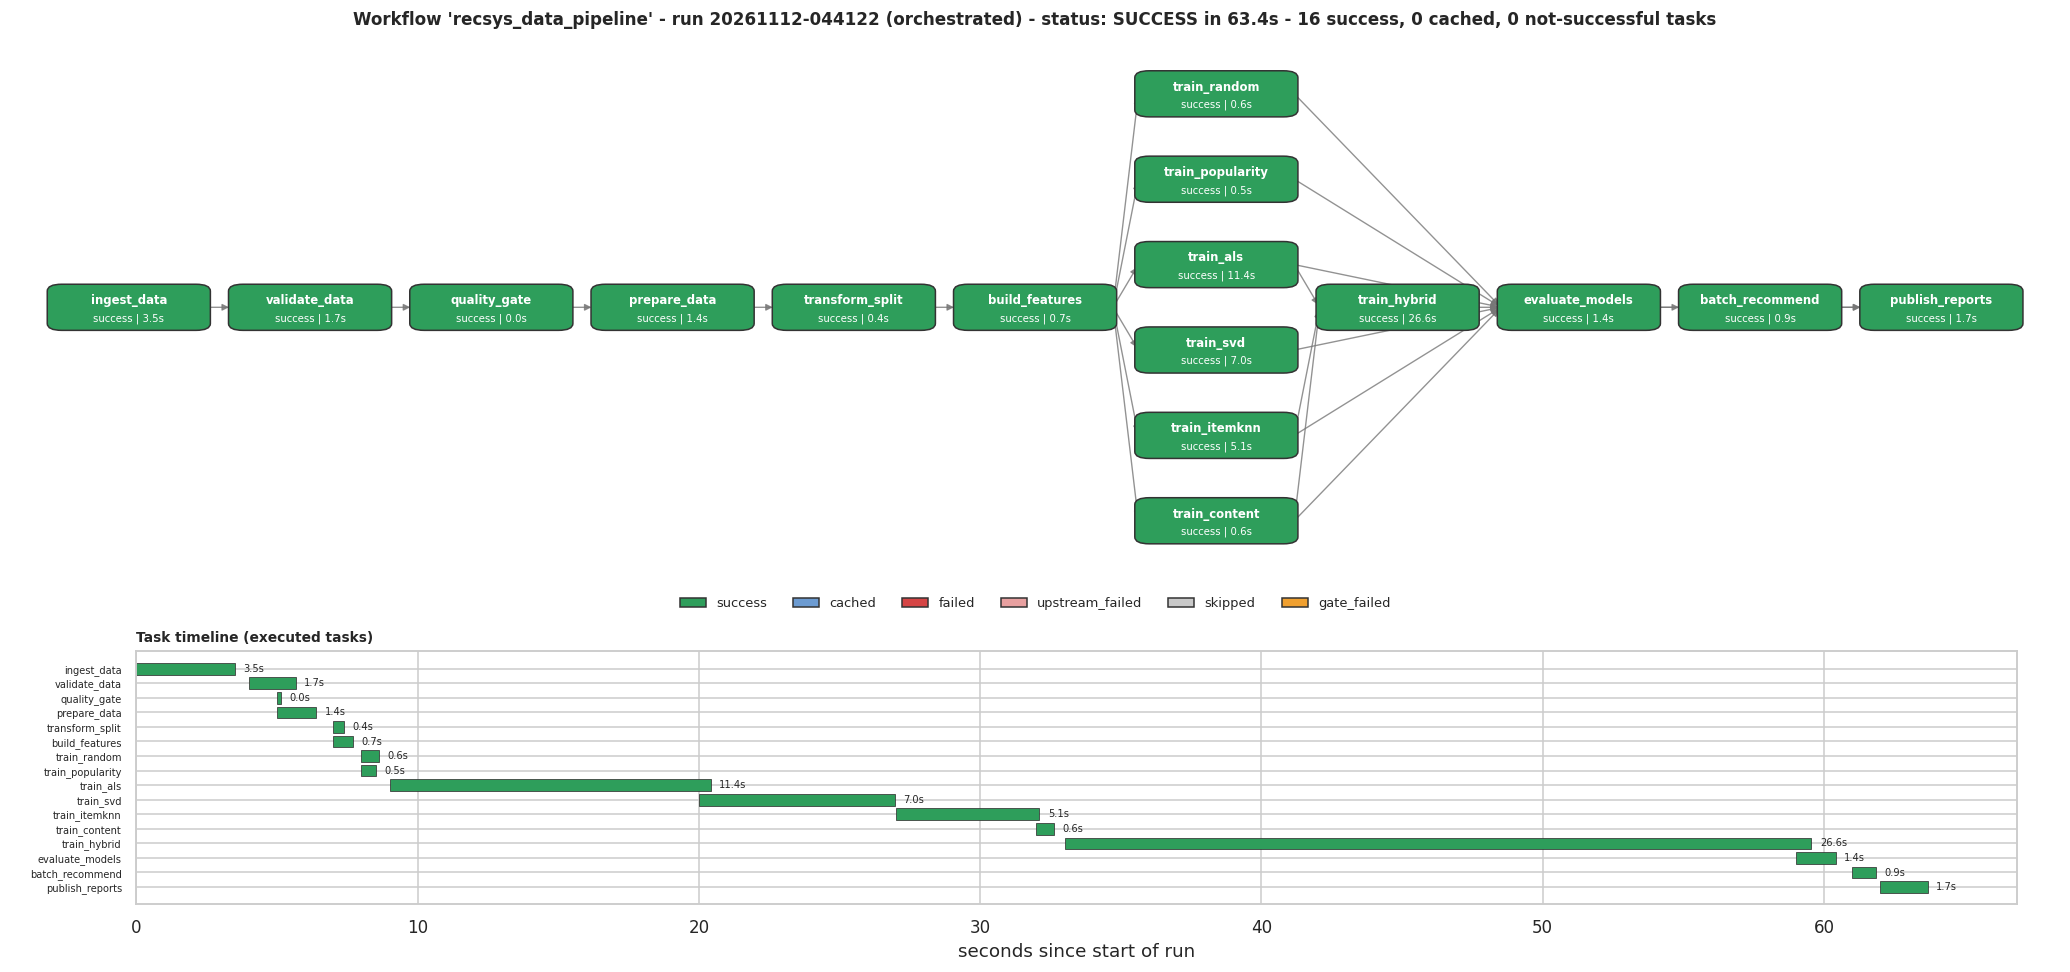

,name,status,attempts,seconds,message
0,ingest_data,success,1,3.50,
1,validate_data,success,1,1.67,
2,quality_gate,success,1,0.00,
3,prepare_data,success,1,1.40,
4,transform_split,success,1,0.37,
5,build_features,success,1,0.71,
6,train_random,success,1,0.61,
7,train_popularity,success,1,0.53,
8,train_als,success,1,11.42,
9,train_svd,success,1,6.97,


[recsys.transformation] user-item matrix: 3,816 users x 2,999 items | nnz=98,667 | sparsity=99.14%
[recsys.orchestrator] > build_features (attempt 1)


[recsys.features] user_features (3816, 12) | item_features (19384, 14) | user_category_share (28390, 3)


[recsys.features] training frame (98667, 32) | test frame (24667, 32) (same code path, train-derived stats) | cold-start test rows: 5887
[recsys.orchestrator] > train_random (attempt 1)


[recsys.training] Random (sanity floor)                fit   0.0s | NDCG@10=0.0028  Recall@10=0.0040  RMSE=nan
[recsys.orchestrator] > train_popularity (attempt 1)


[recsys.training] Popularity (baseline)                fit   0.0s | NDCG@10=0.0266  Recall@10=0.0324  RMSE=0.9336
[recsys.orchestrator] > train_als (attempt 1)


... (8 outputs left out)

[recsys.training] Hybrid (ItemKNN + ALS + content)     fit   1.0s | NDCG@10=0.0442  Recall@10=0.0550  RMSE=nan
[recsys.orchestrator] > evaluate_models (attempt 1)


[recsys.evaluation] results table -> reports/model_results.csv | best personalised model by NDCG@10: ItemKNN (cosine CF) (0.0449)
[recsys.orchestrator] > batch_recommend (attempt 1)


[recsys.serving] batch recommendations (ItemKNN (cosine CF)): 3,816 users x 10 -> reports/top10_recommendations.parquet
[recsys.orchestrator] > publish_reports (attempt 1)


[recsys.reporting] figures, run manifest and final report written -> reports/final_report.pdf
[recsys.orchestrator] === run 20261112-035056 finished: success in 57.89s ===


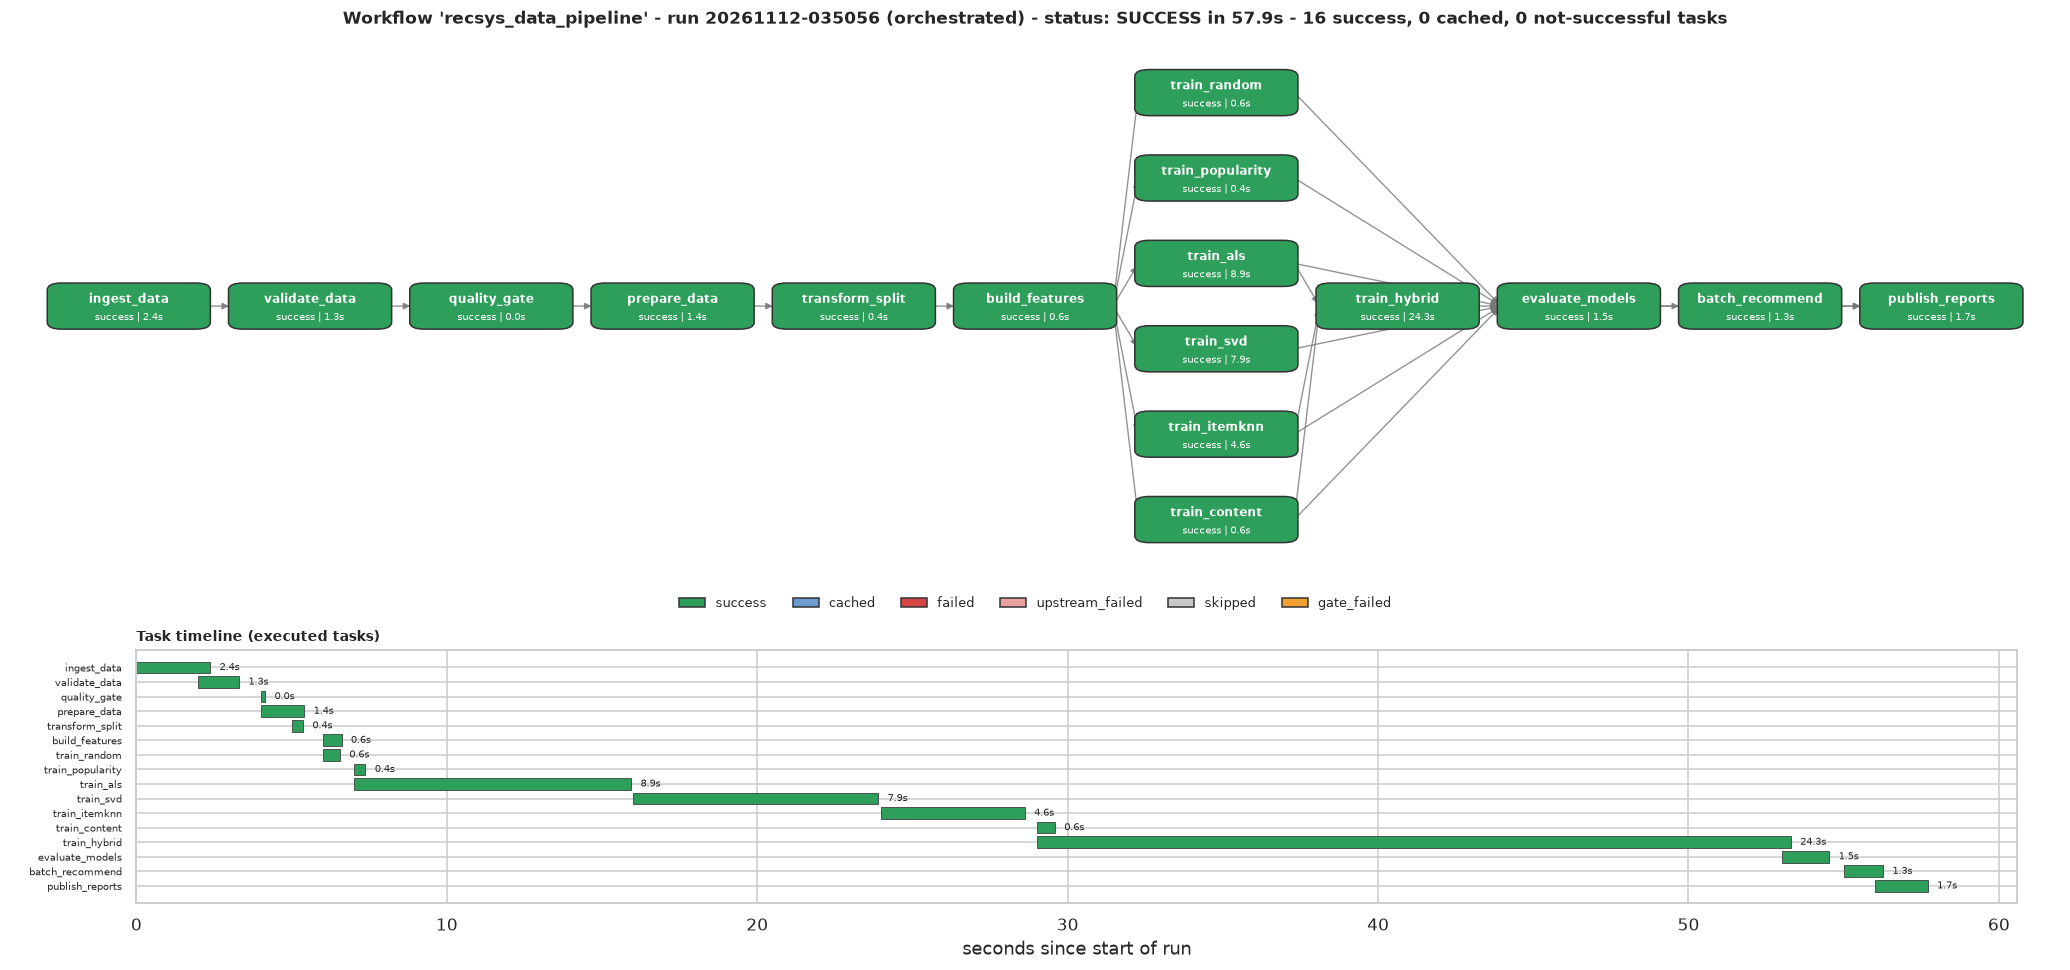

,name,status,attempts,seconds,message
0,ingest_data,success,1,2.38,
1,validate_data,success,1,1.31,
2,quality_gate,success,1,0.00,
3,prepare_data,success,1,1.41,
4,transform_split,success,1,0.37,
5,build_features,success,1,0.61,
6,train_random,success,1,0.56,
7,train_popularity,success,1,0.38,
8,train_als,success,1,8.94,
9,train_svd,success,1,7.90,


In [48]:
res_interactive = pd.read_csv(BASE / "reports/model_results.csv", index_col=0)           # results of the stage-by-stage (development) run
rec = wf.run(resume=False, mode="orchestrated")
fig = orch.render_run_graph(rec, BASE / "reports/orchestration_run.png"); plt.show()
display(pd.DataFrame(rec["tasks"])[["name", "status", "attempts", "seconds", "message"]])
assert rec["status"] == "success"

### j.2 Reproducibility check — orchestrated run vs. stage-by-stage run
Same code, same seeds, same config → the metrics must be identical.

In [49]:
res_orch = pd.read_csv(BASE / "reports/model_results.csv", index_col=0)
same = np.allclose(res_orch.values.astype(float), res_interactive.values.astype(float), atol=1e-9, equal_nan=True)
print(f"max |difference| over {res_orch.size} metric values: {np.nanmax(np.abs(res_orch.values.astype(float) - res_interactive.values.astype(float))):.2e}")
print("REPRODUCIBLE: orchestrated results are identical to the stage-by-stage results" if same else "WARNING: results differ - check library versions / threads")

max |difference| over 70 metric values: 0.00e+00
REPRODUCIBLE: orchestrated results are identical to the stage-by-stage results


### j.3 Second (scheduled) run — idempotence
Re-running with `resume=True` and an unchanged configuration must not recompute anything.

[recsys.orchestrator] === run 20261112-044227 | workflow 'recsys_data_pipeline' | 16 tasks | resume=True ===
[recsys.orchestrator] === run 20261112-044227 finished: success in 0.0s ===


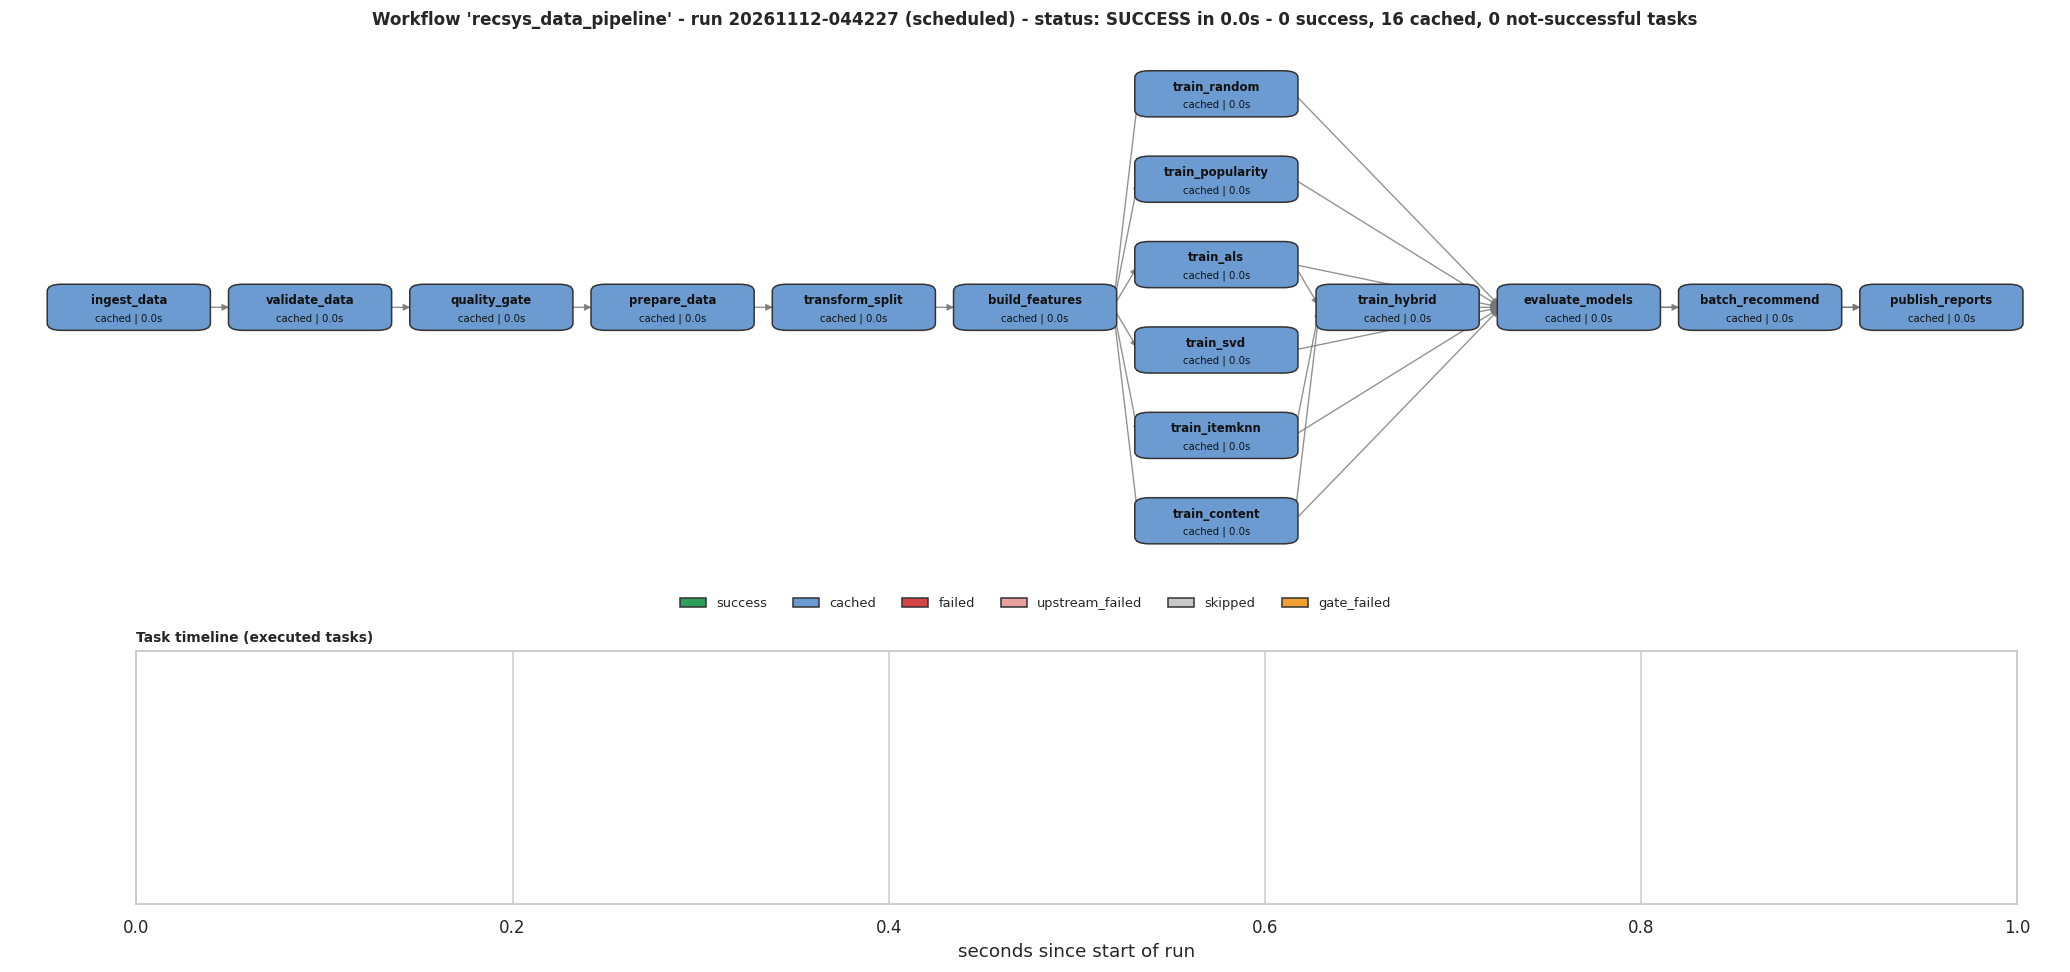

16 of 16 tasks served from cache in 0.0s (first run: 63.4s)


In [50]:
rec2 = wf.run(resume=True, mode="scheduled")
orch.render_run_graph(rec2, BASE / "reports/orchestration_resume_run.png"); plt.show()
print(f"{sum(t['status'] == 'cached' for t in rec2['tasks'])} of {len(rec2['tasks'])} tasks served from cache in {rec2['seconds']}s (first run: {rec['seconds']}s)")

### j.4 Negative test — the data-quality gate stops a bad run
We lower the gate threshold to 0.1 % in a throw-away project folder: validation finds ~2.2 % rejected rows, the gate fails, and *every* downstream task is skipped — no model is ever trained on data that did not pass the gate.

[recsys.orchestrator] === run 20261112-044228 | workflow 'recsys_data_pipeline' | 16 tasks | resume=False ===
[recsys.orchestrator] > ingest_data (attempt 1)
[recsys.ingestion] items loaded: (20068, 23) | boilerplate genre prefix in 100.0% of genre strings
[recsys.ingestion] source extracts written to data/raw/: items=(20068, 23) users=(4015, 4) interactions=(126106, 5)
[recsys.orchestrator] > validate_data (attempt 1)
[recsys.validation] users         rows=  4,015 | rejected=    20 | warning rows=   69
[recsys.validation] items         rows= 20,068 | rejected=   684 | warning rows=7,110
[recsys.validation] interactions  rows=126,106 | rejected= 2,772 | warning rows=    0
[recsys.validation] interactions rejected: 2,772 (2.20%) | report -> reports/data_validation_report.html
[recsys.orchestrator] > quality_gate (attempt 1)
[recsys.orchestrator] QUALITY GATE FAILED in quality_gate: interaction reject ratio 2.20% > threshold 0.10%
[recsys.orchestrator] === run 20261112-044228 finished: s

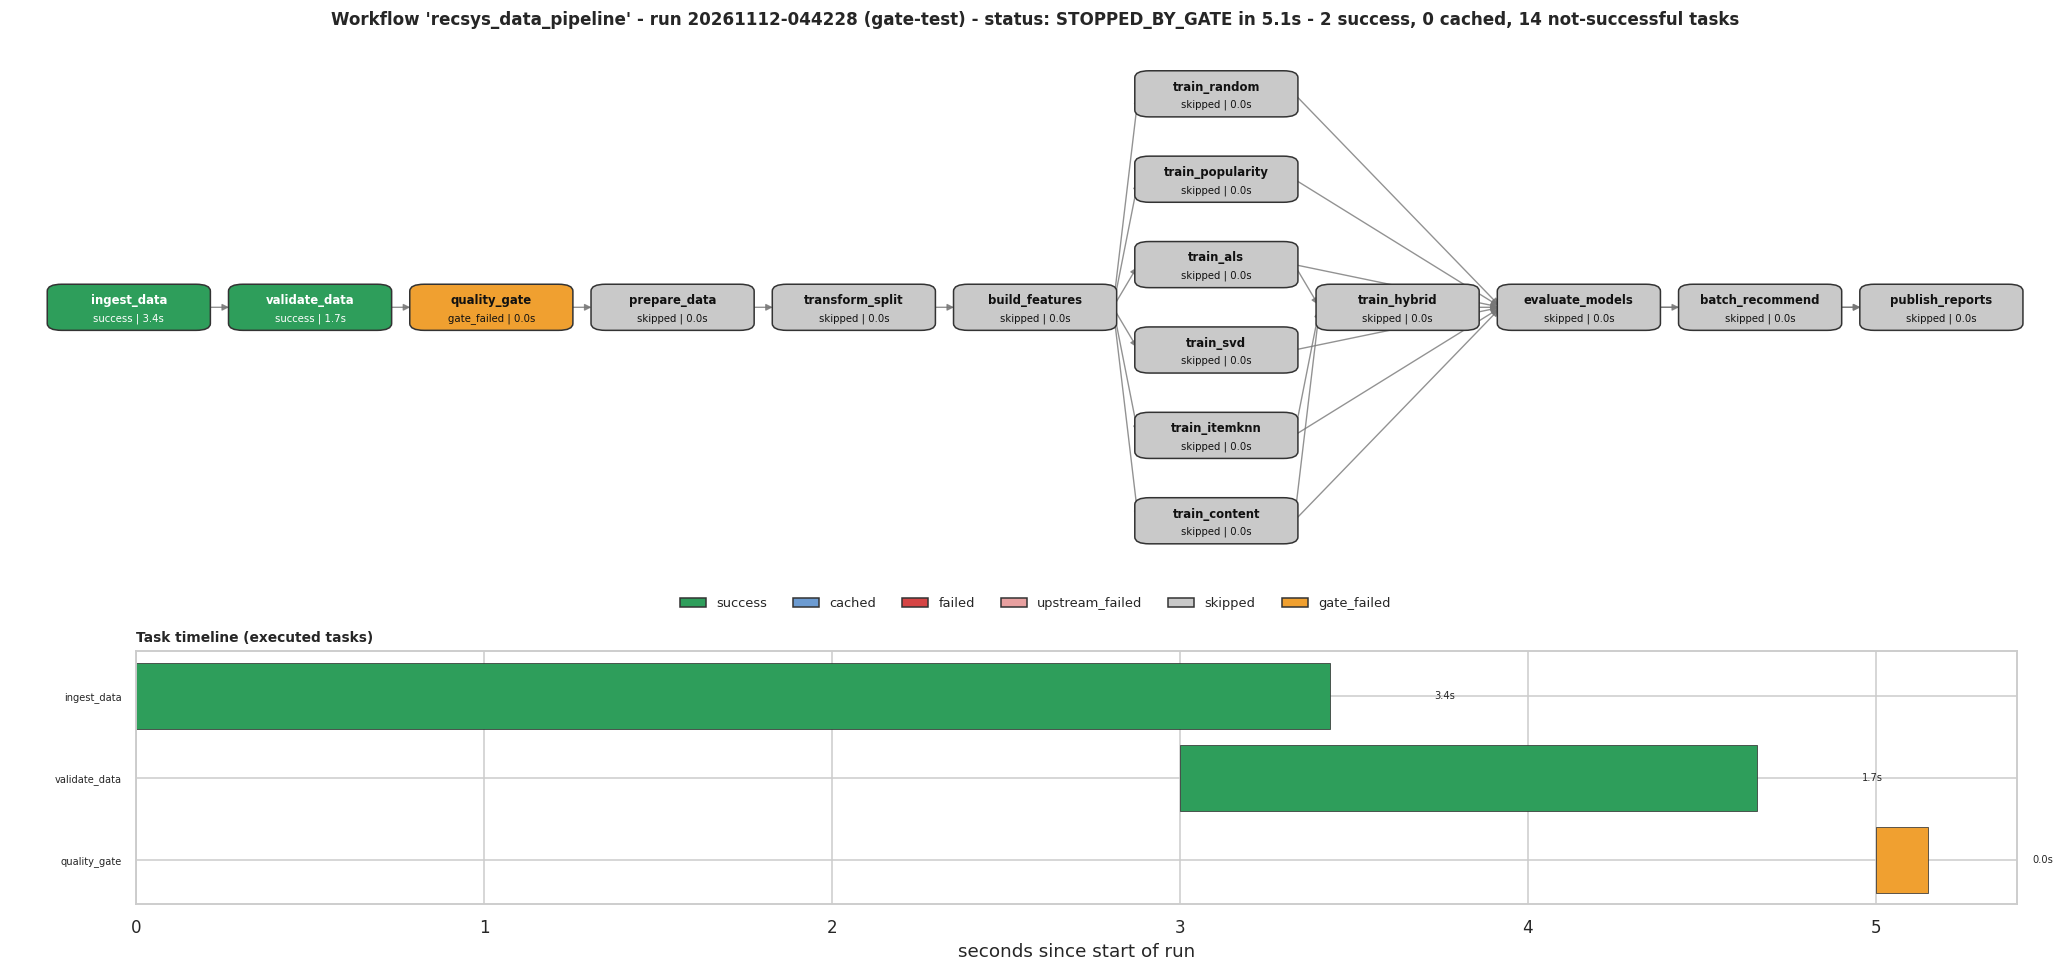

run status: stopped_by_gate | {'gate_failed': 1, 'skipped': 13, 'success': 2}


In [51]:
GATE_BASE = BASE / "_gate_test"
cfg_gate = {**CFG, "max_reject_ratio": 0.001}; save_config(GATE_BASE, cfg_gate)
rec3 = tasks.build_workflow(GATE_BASE, cfg_gate).run(mode="gate-test")
orch.render_run_graph(rec3, BASE / "reports/orchestration_gate_test.png"); plt.show()
print("run status:", rec3["status"], "|", {s: sum(t["status"] == s for t in rec3["tasks"]) for s in sorted({t["status"] for t in rec3["tasks"]})})
shutil.rmtree(GATE_BASE, ignore_errors=True); os.environ["RECSYS_RUN_MODE"] = "interactive"

### j.5 Final PDF report (re-built now that the successful-run graph exists)

In [52]:
final_report = load("src.reporting.final_report")
pdf = final_report.build(BASE)
import subprocess
try:
    print(subprocess.run(["pdfinfo", str(pdf)], capture_output=True, text=True).stdout.split("Pages:")[1].split("\n")[0].strip(), "pages ->", pdf)
    subprocess.run(["pdftoppm", "-r", "75", "-png", str(pdf), "/tmp/report_page"], check=True)
    for p in sorted(Path("/tmp").glob("report_page*.png")): display(Image(filename=str(p)))
except Exception as e:                                         # poppler not available: the PDF is still written
    print("PDF written to", pdf, "(preview skipped:", type(e).__name__, ")")

PDF written to /kaggle/working/recommendation-pipeline/reports/final_report.pdf (preview skipped: FileNotFoundError )


## (k) Inferences & Conclusion

The block below prints the headline numbers of the executed run directly from the generated artefacts.

In [53]:
split = json.loads((BASE / "data/processed/split_info.json").read_text())
res_df = pd.read_csv(BASE / "reports/model_results.csv", index_col=0); sig = pd.read_csv(BASE / "reports/significance_tests.csv")
K = max(CFG["ks"]); personalised = [n for n in res_df.index if not n.startswith(("Random", "Popularity")) and not np.isnan(res_df.loc[n, f"NDCG@{K}"])]
best = res_df.loc[personalised, f"NDCG@{K}"].idxmax(); pop = res_df.loc["Popularity (baseline)"]
hyb = next(n for n in res_df.index if n.startswith("Hybrid")); knn = next(n for n in res_df.index if n.startswith("ItemKNN")); svd = next(n for n in res_df.index if n.startswith("SVD"))
h_k = sig[(sig.model == hyb) & (sig.versus == knn)].iloc[0]

print("DATA QUALITY")
print(f"  users        : {vr['users']['rejected_rows']:>6,} / {vr['users']['rows']:,} rows rejected | {vr['users']['warning_rows']} with soft warnings")
print(f"  items (real) : {vr['items']['rejected_rows']:>6,} / {vr['items']['rows']:,} rows rejected | {vr['items']['warning_rows']:,} with soft warnings")
print(f"  interactions : {vr['interactions']['rejected_rows']:>6,} / {vr['interactions']['rows']:,} rows rejected ({vr['interactions']['rejected_rows']/vr['interactions']['rows']:.2%})")
print(f"  injected fault families found: {(cmp['match'] == 'OK').sum()} of {len(cmp)}")
print("\nDATA SHAPE")
print(f"  train {split['n_train']:,} | test {split['n_test']:,} | cold-start test users {split['cold_start_users']} of {split['test_users']:,} | matrix sparsity {split['sparsity']:.2%}")
print("\nMODELLING (test window, K=%d)" % K)
print(f"  best personalised model by NDCG@{K}: {best}  ({res_df.loc[best, f'NDCG@{K}']:.4f} vs popularity {pop[f'NDCG@{K}']:.4f}, {res_df.loc[best, f'NDCG@{K}']/pop[f'NDCG@{K}']-1:+.0%})")
print(f"  Hybrid vs ItemKNN, paired delta NDCG@{K} = {h_k.iloc[2]:+.4f}  95% CI [{h_k['ci_low']:+.4f}, {h_k['ci_high']:+.4f}] -> {'significant' if h_k['significant_95'] else 'statistically tied'}; diversity {res_df.loc[hyb, f'Diversity@{K}']:.2f} vs {res_df.loc[knn, f'Diversity@{K}']:.2f}")
print(f"  catalogue coverage@{K}: popularity {pop[f'Coverage@{K}']:.1%} | ALS {res_df.loc['ALS (implicit MF)', f'Coverage@{K}']:.1%} | ItemKNN {res_df.loc[knn, f'Coverage@{K}']:.1%} | Hybrid {res_df.loc[hyb, f'Coverage@{K}']:.1%}")
print(f"  SVD: RMSE {res_df.loc[svd, 'RMSE']:.4f} (popularity {pop['RMSE']:.4f}) but NDCG@{K} {res_df.loc[svd, f'NDCG@{K}']:.4f} (random {res_df.loc[res_df.index[0], f'NDCG@{K}']:.4f})")
print("\nORCHESTRATION")
print(f"  full run: {rec['status']} in {rec['seconds']}s ({len(rec['tasks'])} tasks) | cached re-run: {rec2['seconds']}s | quality-gate test: {rec3['status']} | orchestrated == stage-by-stage results: {same}")

DATA QUALITY
  users        :     20 / 4,015 rows rejected | 69 with soft warnings
  items (real) :    684 / 20,068 rows rejected | 7,110 with soft warnings
  interactions :  2,772 / 126,106 rows rejected (2.20%)
  injected fault families found: 14 of 14

DATA SHAPE
  train 98,667 | test 24,667 | cold-start test users 179 of 3,401 | matrix sparsity 99.14%

MODELLING (test window, K=10)
  best personalised model by NDCG@10: ItemKNN (cosine CF)  (0.0449 vs popularity 0.0266, +69%)
  Hybrid vs ItemKNN, paired delta NDCG@10 = -0.0007  95% CI [-0.0035, +0.0021] -> statistically tied; diversity 0.49 vs 0.40
  catalogue coverage@10: popularity 0.8% | ALS 26.4% | ItemKNN 19.1% | Hybrid 18.7%
  SVD: RMSE 0.9317 (popularity 0.9336) but NDCG@10 0.0015 (random 0.0028)

ORCHESTRATION
  full run: success in 63.4s (16 tasks) | cached re-run: 0.0s | quality-gate test: stopped_by_gate | orchestrated == stage-by-stage results: True


### Key inferences

1. **Validation pays for itself.** About 2 % injected faults across 14 fault families (10 interaction, 4 user) were all detected by the rules, isolated in an error dataset with the violated rule, and measured against a ledger. Referential integrity *cascades*: rejecting one user (bad signup date) orphans all of that user's interactions — which is why tables are validated in dependency order. Validation also surfaced genuine problems of the *real* file (near-empty rows, duplicate book ids, missing star histograms, boilerplate genre strings).
2. **Personalisation beats popularity — and the difference is statistically meaningful.** ALS, ItemKNN and the Hybrid improve NDCG@10 over the popularity baseline with bootstrap CIs that exclude zero, while recommending far more of the catalogue. Popularity concentrates on a handful of blockbusters (several editions of the same book appear in its top list), which is exactly where a recommender adds no information.
3. **Best accuracy: neighbourhood CF; best balance: the hybrid.** ItemKNN has the highest NDCG@10 in this run, but the paired CI shows the Hybrid (ItemKNN + ALS + content + popularity) is **statistically indistinguishable** from it in NDCG, while giving **more diverse lists** and being significantly better than ALS alone. We therefore report ItemKNN as the numerically best ranker and the Hybrid as the preferable trade-off when diversity matters — we do not claim a win that the confidence interval does not support.
4. **Rating accuracy ≠ ranking quality.** SVD barely improves RMSE over the shrunk item mean and, used as a ranker, falls *below random*: ranking by predicted rating surfaces obscure, highly rated books nobody else rated (see the popularity-percentile diagnostic). Rating-prediction and top-K recommendation are different objectives and need different models and metrics.
5. **Content features alone are weak, but useful as a component.** A pure genre profile is a poor ranker (genres do not capture taste) and gives very homogeneous lists; as one signal inside the hybrid it adds only a small gain. Its real value is that it needs no other users, which matters for cold start.
6. **Power users are served best.** Accuracy rises with the amount of history (segment chart); light users remain hard. Users with no history (cold start) get the popularity fallback.
7. **Feature management prevents silent bugs.** One `FeatureStore` builds training and prediction features, computed from the training window only; the parity test proves they match.
8. **Orchestration is verified, not just declared.** The 16-task workflow reproduces the stage-by-stage metrics exactly, a repeat run is served from cache, a crash is retried and its downstream tasks are never run, and the quality gate demonstrably stops a bad run.

### Limitations
- **Synthetic users / interactions** → conclusions about *which model wins* hold for this simulator; the pipeline engineering transfers to real logs.
- **Offline evaluation, one temporal split**; absolute metrics are small because the matrix is ~99 % sparse and only the future window is scored. No online A/B test.
- **Editions are not resolved to a work id**; production would add entity resolution.
- **Local tooling**: MLflow uses a SQLite backend, the feature store is Parquet-on-disk, and Airflow is provided as a DAG file (validated for syntax) rather than a live scheduler.

### Conclusion
The notebook delivers an end-to-end, modular and **reproducible** data-management pipeline: automated validation with an error dataset and a measured detection rate, leakage-free splitting, documented and reusable features, seven tracked and statistically compared models, a serving layer with cold-start handling, and a tested orchestration layer — all runnable from a single notebook or a single command, with no cloud account.

**Possible next steps:** real interaction logs and edition de-duplication; text / author embeddings and a two-tower or sequence model; a hosted MLflow server and registry; running the Airflow DAG in a managed scheduler; data-drift monitoring and an online A/B test.

## (l) Submission pack & deliverables check

This section produces the final deliverables: `README.md`, `.gitignore`, `requirements.txt` (pinned to the library versions that produced these results), a lightweight **repository zip** and a **full outputs zip**. It then checks every item against the assignment's deliverables list.

In [54]:
from importlib.metadata import version
disp = res_df.round(4).astype(object).where(res_df.notna(), "-").reset_index()
try:
    res_md = disp.to_markdown(index=False)
except ImportError:
    res_md = "```\n" + disp.to_string(index=False) + "\n```"
rr = rec  # orchestrated run

README = f'''# End-to-End Data Management Pipeline for a Book Recommendation System

Data Management for Machine Learning - Assignment 2. A modular, reproducible pipeline:
**ingestion -> validation -> preparation -> transformation -> feature management -> model training -> evaluation -> orchestration**,
plus a serving layer (top-K with cold-start fallback) and an auto-generated final report. Runs in a Kaggle / Jupyter notebook or from the command line - **no cloud account required**.

![architecture](reports/architecture_diagram.png)

## Data
* **items** - real Goodreads books metadata (20,068 rows; CSV not redistributed here - pass its path with `--source-csv`).
* **users / interactions** - *synthetic, documented* (see `src/ingestion/ingest.py`): ratings are drawn from each book's real 1-5 star histogram; ~2 % faults are injected to exercise validation.
  Model scores therefore describe the simulator, not real Goodreads behaviour.

## Quick start
```bash
pip install -r requirements.txt
python -m src.pipeline.run --base . --source-csv "/path/to/Goodreadss Books.csv"          # full pipeline (~1 min on CPU)
python -m src.pipeline.run --base . --resume                                           # idempotent re-run (cached tasks are skipped)
python -m src.pipeline.run --base . --dry-run                                          # show the task graph
mlflow ui --backend-store-uri sqlite:///mlflow.db                                      # browse tracked experiments
```
Scheduling (cron, nightly): `0 2 * * * cd /path/to/project && python -m src.pipeline.run --base . --resume`  
Airflow: copy the project next to Airflow and place `dags/recommendation_pipeline_dag.py` in `$AIRFLOW_HOME/dags/` (it reuses the same task registry).

## Project structure
```
data/{{raw,processed,features,errors}}/    src/{{ingestion,validation,preparation,transformation,features,training,evaluation,serving,reporting,pipeline}}/
dags/recommendation_pipeline_dag.py      configs/pipeline_config.json      models/      reports/      mlflow.db + mlruns/
```

## Pipeline stages and key decisions
| Stage | Module | Decision |
|---|---|---|
| Ingestion | `src/ingestion` | raw extracts stored untouched; documented simulator + fault injection with ledger |
| Validation | `src/validation` | Pandera + custom rules, severity reject/warning, referential integrity, error dataset, HTML report |
| Preparation | `src/preparation` | category-median imputation with `*_imputed` flags; genre boilerplate removal |
| Transformation | `src/transformation` | leak-free time split (asserted), temporal validation fold, activity / popularity / sparse matrix |
| Features | `src/features` | train-only features at fixed REF_DATE, Parquet, catalog, `FeatureStore` shared by training and prediction |
| Training | `src/training` | 7 models, tuning on validation fold, MLflow tracking (nested trials) |
| Evaluation | `src/evaluation` | P/R/NDCG@5,10, Coverage, Diversity, RMSE, MAE, bootstrap CIs, paired significance tests |
| Serving | `src/serving` | best model + popularity fallback for cold-start users |
| Orchestration | `src/pipeline`, `dags/` | dependency-aware engine (retries, quality gate, resume) + Airflow DAG from the same registry |

## Results (test window, K = 5 / 10)
{res_md}

![results](reports/results_overview.png)

![orchestration](reports/orchestration_run.png)

## Reproducibility
Fixed seeds, one config file (`configs/pipeline_config.json`, fingerprint `{config_hash(CFG)}`), pinned `requirements.txt`; the orchestrated run reproduces the stage-by-stage results exactly
(full run: {rr['seconds']} s, {len(rr['tasks'])} tasks). See `reports/final_report.pdf` for the design report.

## Deliverable map
`reports/architecture_diagram.png` - architecture | `reports/data_validation_report.html`, `data/errors/` - validation | `reports/feature_catalog.csv|md` - features |
`reports/model_results.csv` (+ `_ci`, `significance_tests`) - evaluation | `reports/orchestration_run.png` - successful run | `reports/final_report.pdf` - report
'''
(BASE / "README.md").write_text(README, encoding="utf-8")

(BASE / ".gitignore").write_text("__pycache__/\n*.pyc\n.ipynb_checkpoints/\nmlruns/\nmlflow.db\n_gate_test/\ndata/raw/items_raw.csv\n*.zip\n")

pins = ["pandas", "numpy", "scipy", "pyarrow", "pandera", "mlflow", "implicit", "scikit-surprise", "matplotlib", "seaborn", "joblib", "reportlab", "pillow", "tabulate"]
lines = ["# versions that produced the reported results (generated by the notebook)"]
for p in pins:
    try: lines.append(f"{p}=={version(p)}")
    except Exception: pass
lines.append("# optional - only needed to run dags/recommendation_pipeline_dag.py in Airflow:\n# apache-airflow>=2.9")
(BASE / "requirements.txt").write_text("\n".join(lines) + "\n")
print((BASE / "requirements.txt").read_text()); print("README.md written (", len(README.splitlines()), "lines )")

# versions that produced the reported results (generated by the notebook)
pandas==2.3.3
numpy==2.1.3
scipy==1.16.3
pyarrow==23.0.1
pandera==0.36.0
mlflow==3.18.0
implicit==0.7.3
scikit-surprise==1.1.5
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
reportlab==5.1.0
pillow==13.0.0
tabulate==0.9.0
# optional - only needed to run dags/recommendation_pipeline_dag.py in Airflow:
# apache-airflow>=2.9

README.md written ( 65 lines )


In [55]:
# ---- repository zip (lightweight, GitHub-ready) + full outputs zip (everything incl. MLflow store)
import fnmatch
EXCLUDE = ["__pycache__", "*.pyc", "mlruns", "mlflow.db", "_gate_test", ".ipynb_checkpoints", "items_raw.csv", "*.zip"]
STAGE = BASE.parent / "repo_export"; shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree(BASE, STAGE, ignore=shutil.ignore_patterns(*EXCLUDE))
repo_zip = shutil.make_archive(str(BASE.parent / "recommendation-pipeline_repo"), "zip", root_dir=STAGE)
full_zip = shutil.make_archive(str(BASE.parent / "outputs"), "zip", root_dir=BASE)
print(f"repository zip : {repo_zip}  ({Path(repo_zip).stat().st_size/1e6:.1f} MB)\nfull outputs   : {full_zip}  ({Path(full_zip).stat().st_size/1e6:.1f} MB)")

repository zip : /kaggle/working/recommendation-pipeline_repo.zip  (22.7 MB)
full outputs   : /kaggle/working/outputs.zip  (43.8 MB)


In [56]:
# ---- deliverables check against the assignment
DELIVERABLES = [
    ("Source code organised into modules", "src/pipeline/tasks.py"), ("README.md", "README.md"), ("requirements.txt", "requirements.txt"),
    ("Architecture diagram", "reports/architecture_diagram.png"), ("Data validation report (HTML)", "reports/data_validation_report.html"),
    ("Validation error log + error dataset", "data/errors/validation_error_log.csv"), ("Feature catalog", "reports/feature_catalog.csv"),
    ("Model evaluation results", "reports/model_results.csv"), ("Significance tests", "reports/significance_tests.csv"),
    ("Experiment tracking (MLflow)", "mlflow.db"), ("Orchestration DAG / workflow", "dags/recommendation_pipeline_dag.py"),
    ("Screenshot of a successful run", "reports/orchestration_run.png"), ("Batch recommendations", "reports/top10_recommendations.parquet"),
    ("Final report (2-3 pages, PDF)", "reports/final_report.pdf"), ("Run manifest", "reports/run_manifest.json"),
]
chk = pd.DataFrame([{"deliverable": d, "path": p, "status": "OK" if (BASE / p).exists() else "MISSING",
                     "size_KB": round((BASE / p).stat().st_size / 1024, 1) if (BASE / p).exists() else None} for d, p in DELIVERABLES])
display(chk.style.map(lambda v: "background-color:#c7e9c0" if v == "OK" else ("background-color:#f4b6b6" if v == "MISSING" else ""), subset=["status"]))
print("ALL DELIVERABLES PRESENT" if (chk.status == "OK").all() else "SOME DELIVERABLES ARE MISSING")

,deliverable,path,status,size_KB
0,Source code organised into modules,src/pipeline/tasks.py,OK,3.700000
1,README.md,README.md,OK,5.400000
2,requirements.txt,requirements.txt,OK,0.400000
3,Architecture diagram,reports/architecture_diagram.png,OK,213.300000
4,Data validation report (HTML),reports/data_validation_report.html,OK,13.300000
5,Validation error log + error dataset,data/errors/validation_error_log.csv,OK,1105.200000
6,Feature catalog,reports/feature_catalog.csv,OK,2.700000
7,Model evaluation results,reports/model_results.csv,OK,1.400000
8,Significance tests,reports/significance_tests.csv,OK,0.900000
9,Experiment tracking (MLflow),mlflow.db,OK,1504.000000


ALL DELIVERABLES PRESENT


### Publishing the repository and submission
The repository is published to GitHub from the cell below. It authenticates with a personal access token held in a Kaggle *Secret*, so no credential appears in the notebook. The submission consists of the GitHub repository link together with `reports/final_report.pdf`. The notebook itself is also included.

**Orchestration evidence.** The workflow is executed by the project's own dependency-aware engine (`src/pipeline/`). Screenshots of the executed run are collected in section (m). Proof of the runs is also kept in `reports/orchestration_run.png` (successful run), `reports/orchestration_resume_run.png` (cached re-run), the quality-gate test graph and the run JSON files in `reports/orchestration/`. The same task registry is exported as an Apache Airflow 2.x DAG (`dags/recommendation_pipeline_dag.py`). Kaggle cannot host the Airflow scheduler and web server, so the DAG file was not executed inside Airflow itself; the assignment accepts a "clearly structured scheduled Python workflow" for exactly this case.

In [57]:
# ---- OPTIONAL: push the repository to GitHub. Off by default; needs a Kaggle Secret named GITHUB_TOKEN (classic PAT with `repo` scope).
PUSH_TO_GITHUB = False
GITHUB_REPO = "your-username/recommendation-pipeline"          # <- empty repository you created on GitHub
if PUSH_TO_GITHUB:
    import subprocess
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    git = lambda *a: subprocess.run(["git", *a], cwd=STAGE, check=True, capture_output=True, text=True)
    git("init", "-b", "main"); git("config", "user.email", "student@example.com"); git("config", "user.name", "student")
    git("add", "-A"); git("commit", "-m", "End-to-end recommendation data pipeline (DM4ML Assignment 2)")
    git("remote", "add", "origin", f"https://{token}@github.com/{GITHUB_REPO}.git"); git("push", "-u", "origin", "main")
    print("pushed to https://github.com/" + GITHUB_REPO)
else:
    print("PUSH_TO_GITHUB = False -> skipped (download recommendation-pipeline_repo.zip from the Output tab instead)")

PUSH_TO_GITHUB = False -> skipped (download recommendation-pipeline_repo.zip from the Output tab instead)


## (m) Execution evidence — screenshots of the Kaggle run

The screenshots below were taken from this notebook while it was executed on Kaggle (Run All, no errors). They document the validation, modelling, serving and orchestration stages, and they are also included in the repository under `docs/screenshots/`.

### m.1 Data validation and preparation

**Figure m.1 — Validation findings per rule.** Rejected rules (red) and repaired / warning rules (yellow) across the users, items and interactions tables, as produced by the Pandera and custom rule checks.

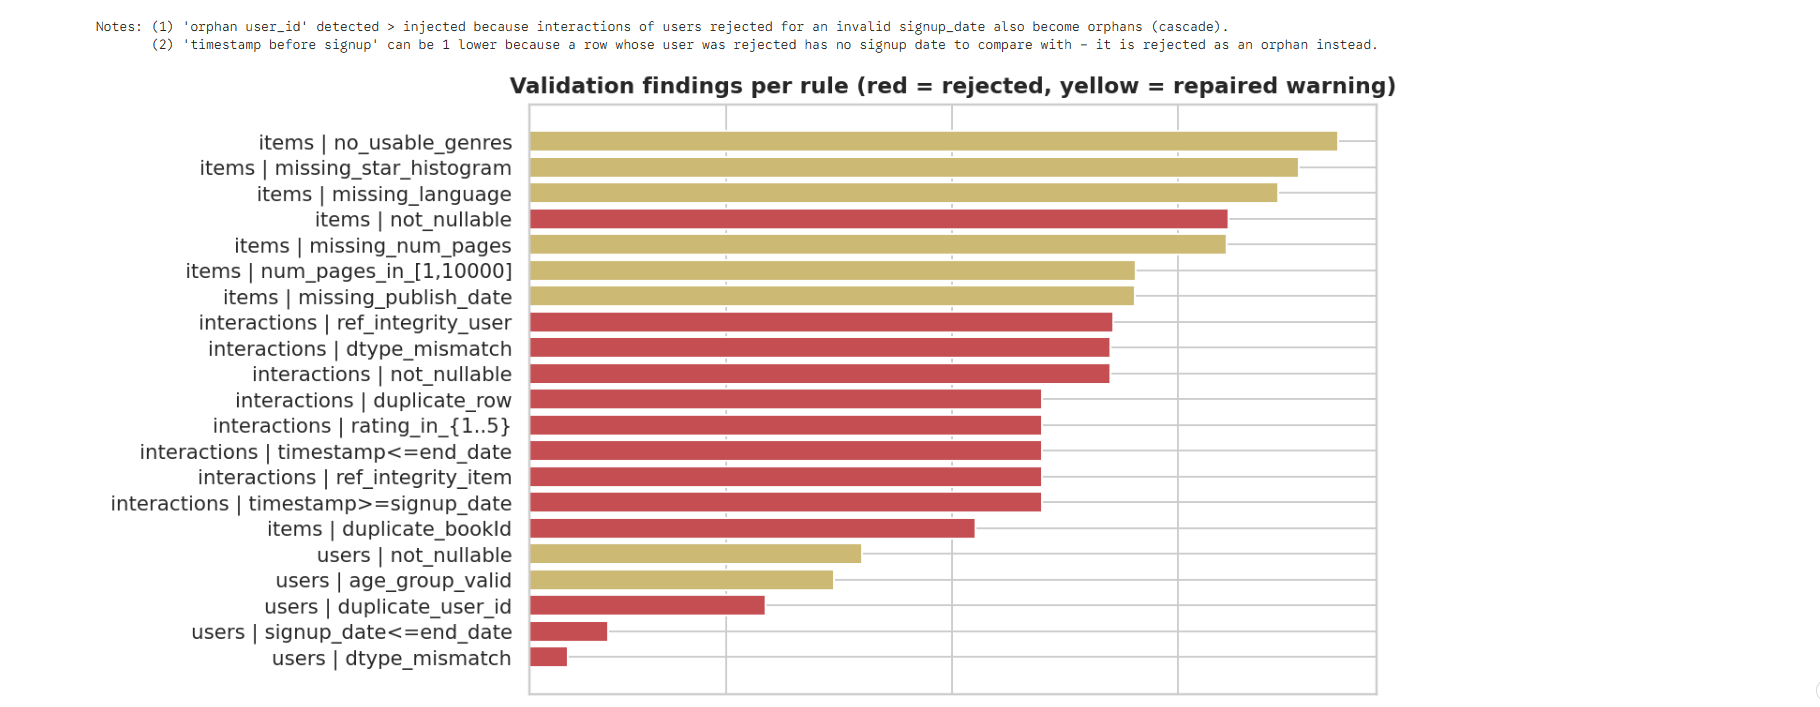

**Figure m.2 — Time-based split and derived datasets.** Monthly interaction volume with the validation cut and the train/test cut marked, followed by the user-activity summary and the item-popularity table.

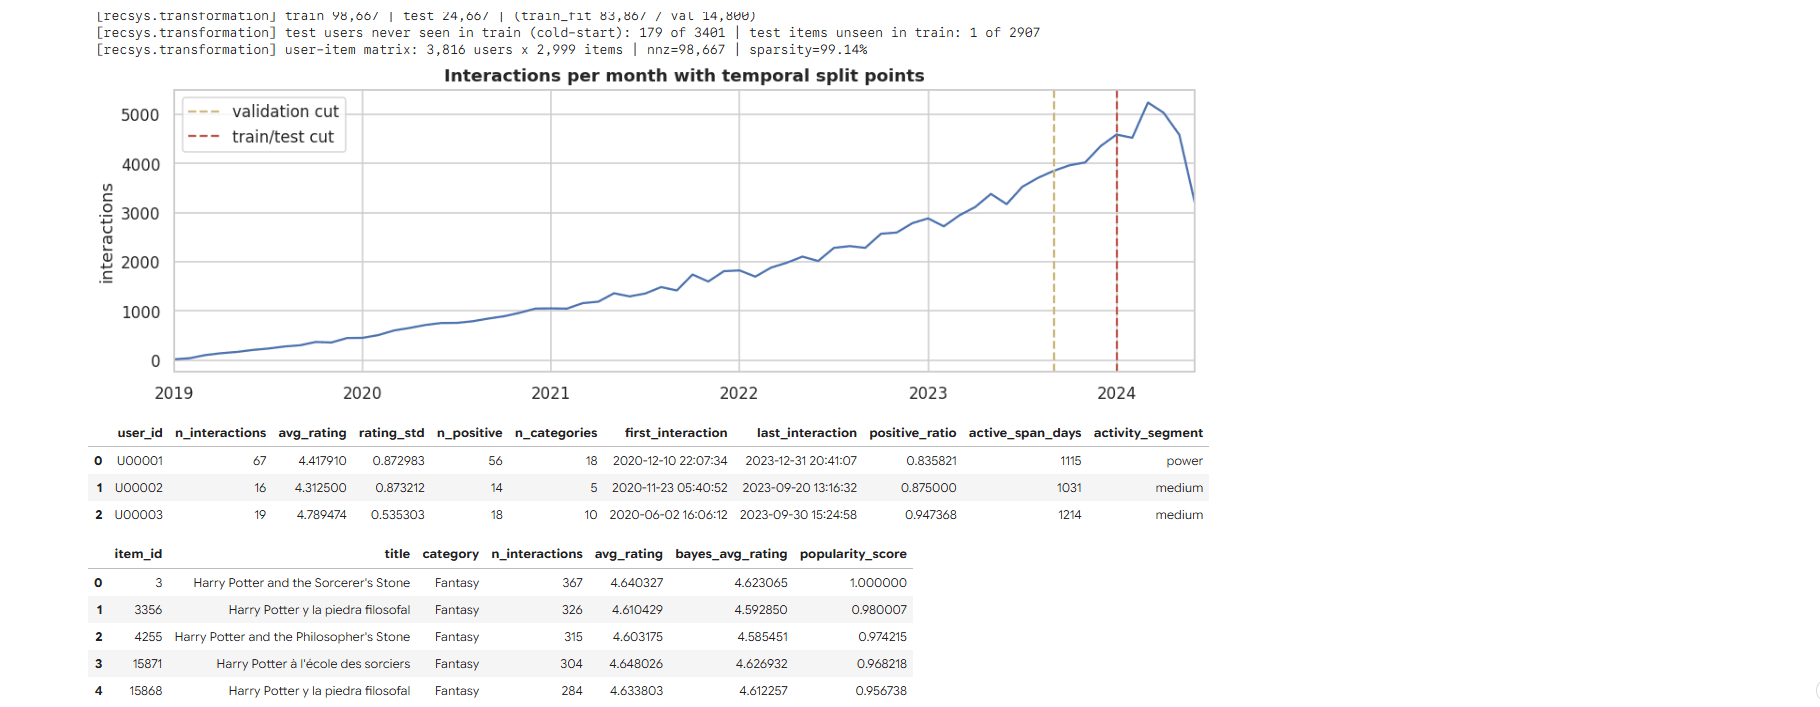

### m.2 Model training and evaluation

**Figure m.3 — MLflow experiment tracking.** Top-level MLflow run for each model, with every tuning trial stored as a nested run underneath.

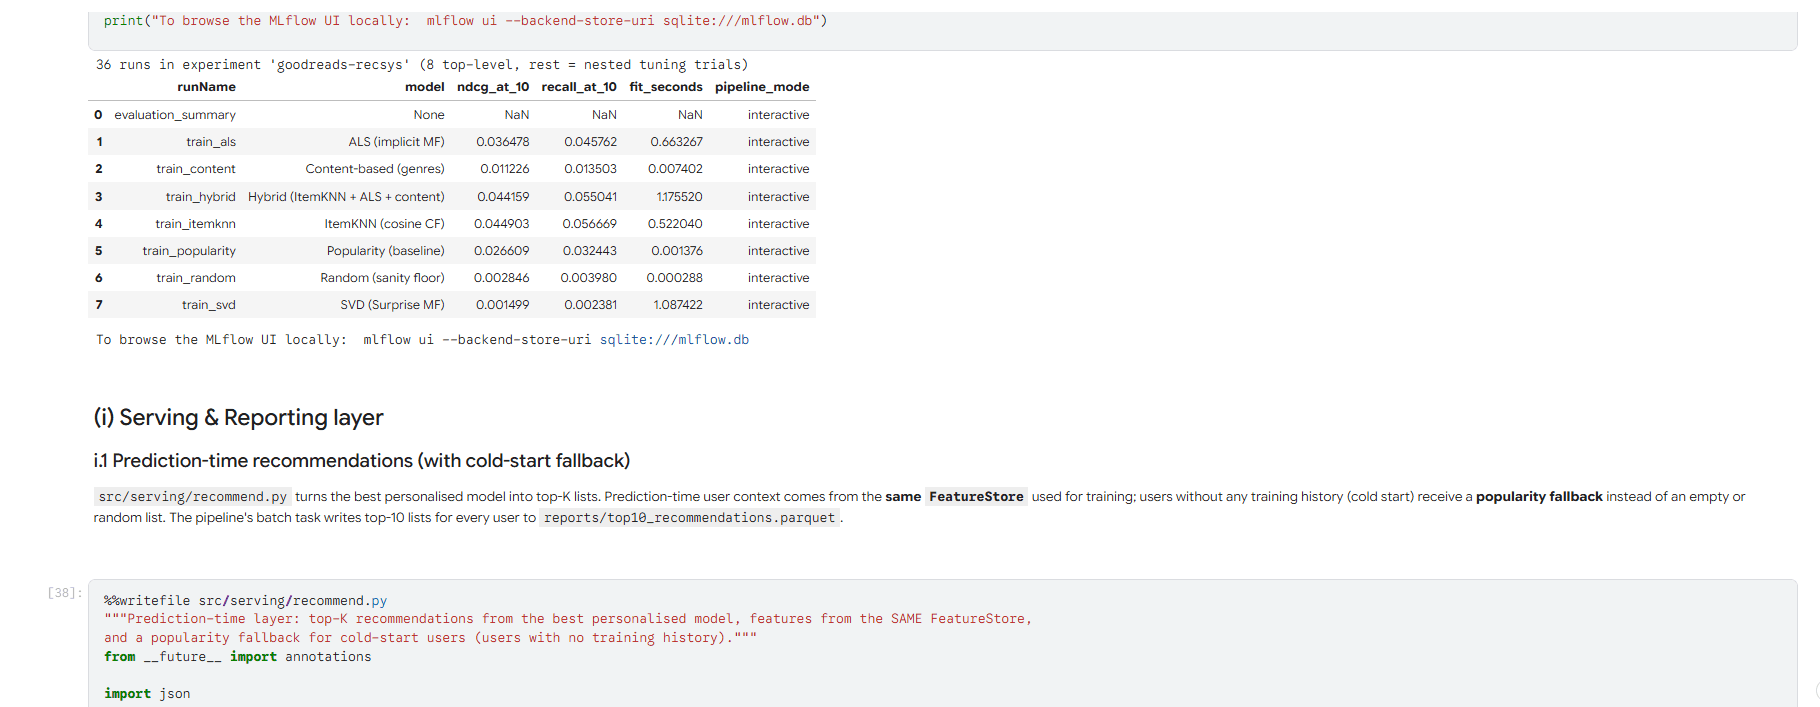

**Figure m.4 — Model comparison table (test window, K = 5 and 10).** Precision, Recall, NDCG, Coverage, Diversity, RMSE and MAE for all seven models, with the change relative to the popularity baseline and the bootstrap confidence intervals.

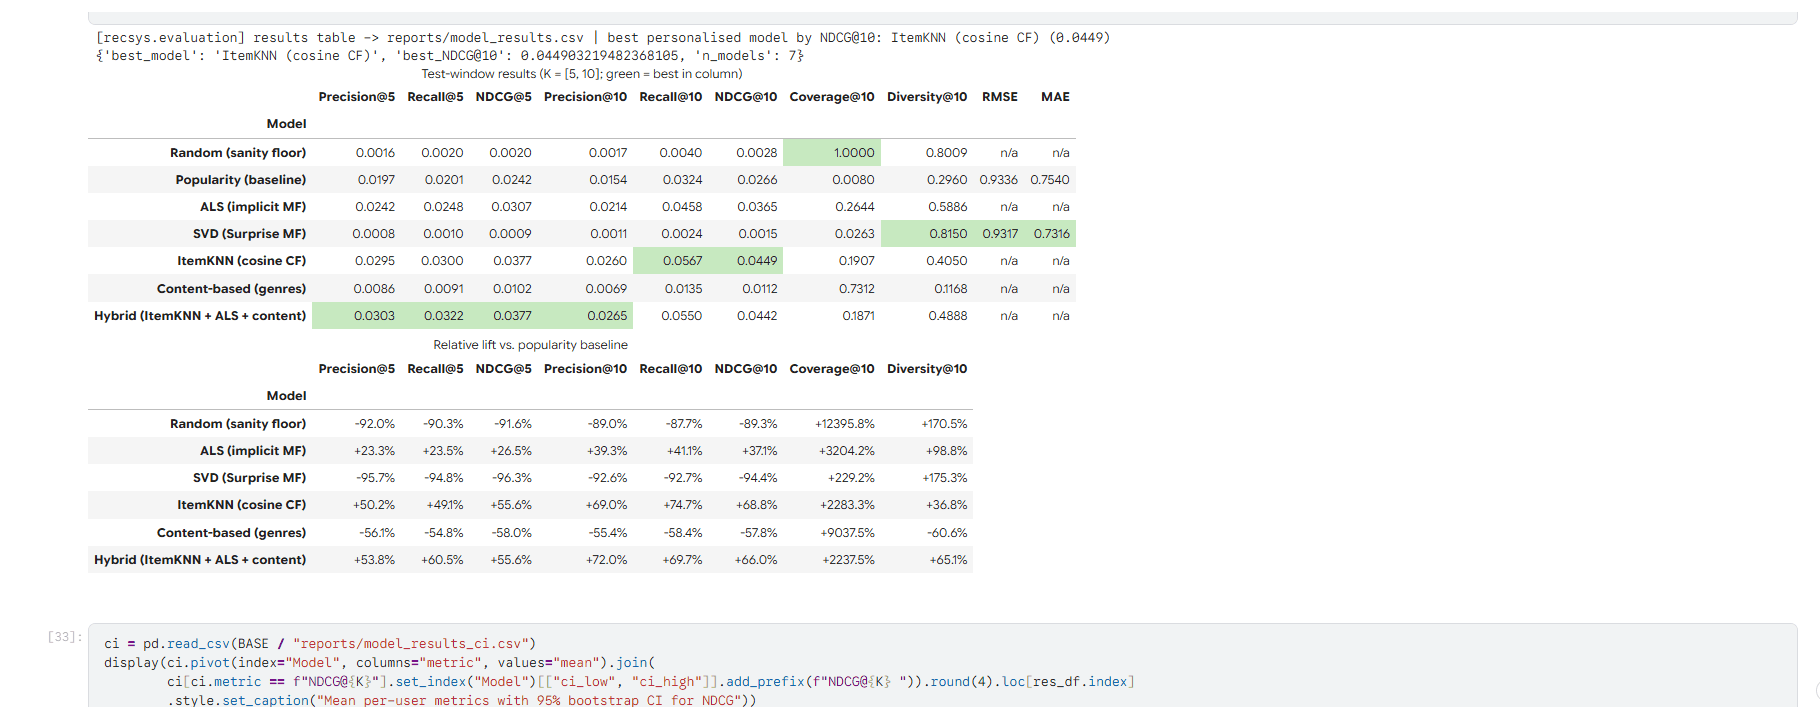

**Figure m.5 — Result figures.** Bootstrap confidence intervals for Precision, Recall and NDCG at K = 10, together with coverage / diversity of the recommendation lists.

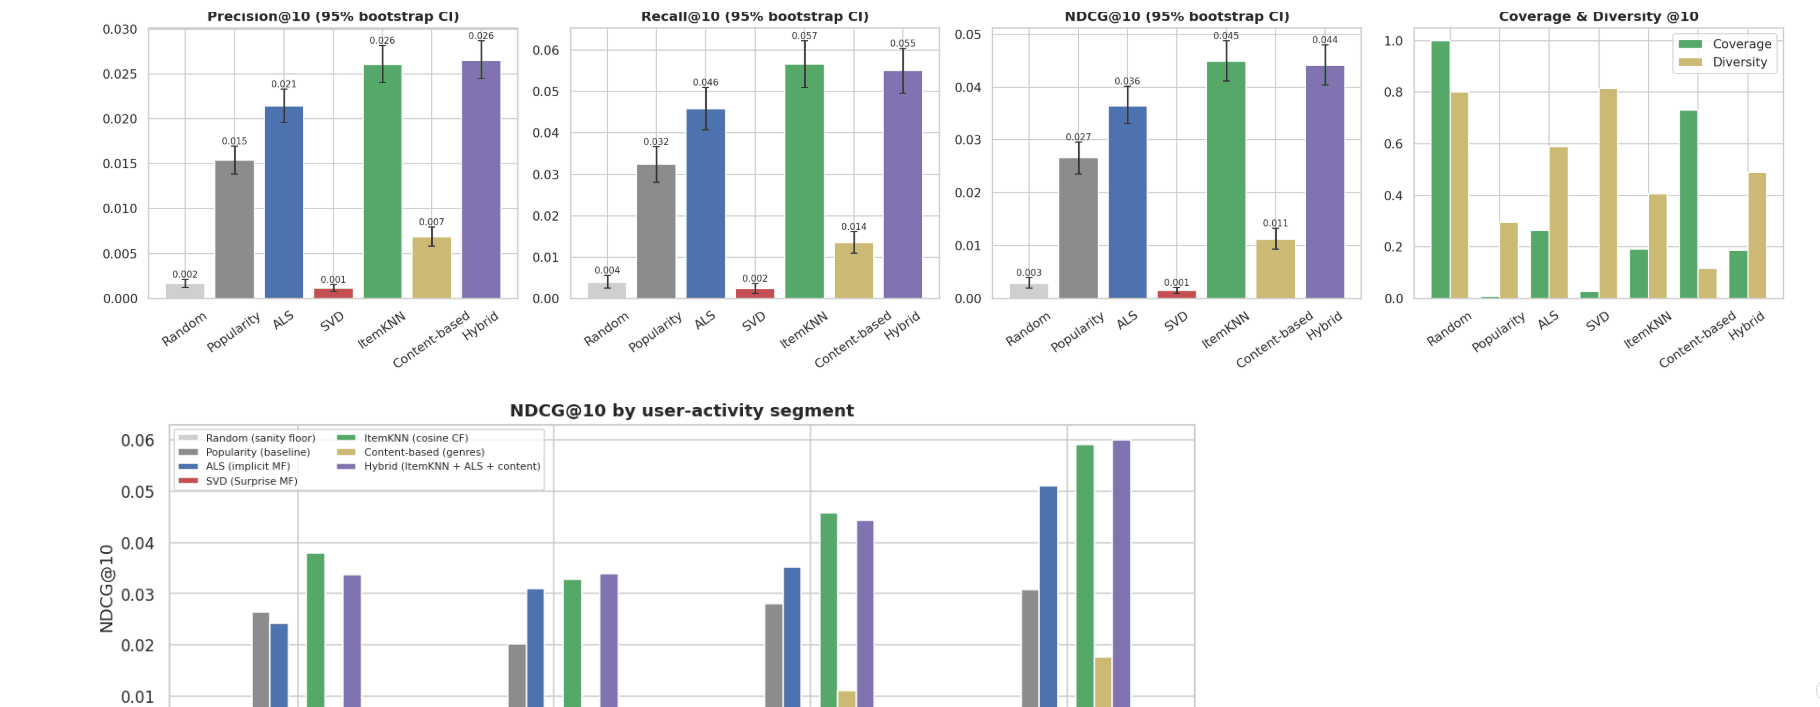

### m.3 Serving layer

**Figure m.6 — Prediction-time recommendations.** Top-10 list for a known user from the best model (ItemKNN) and the popularity fallback for a cold-start user.

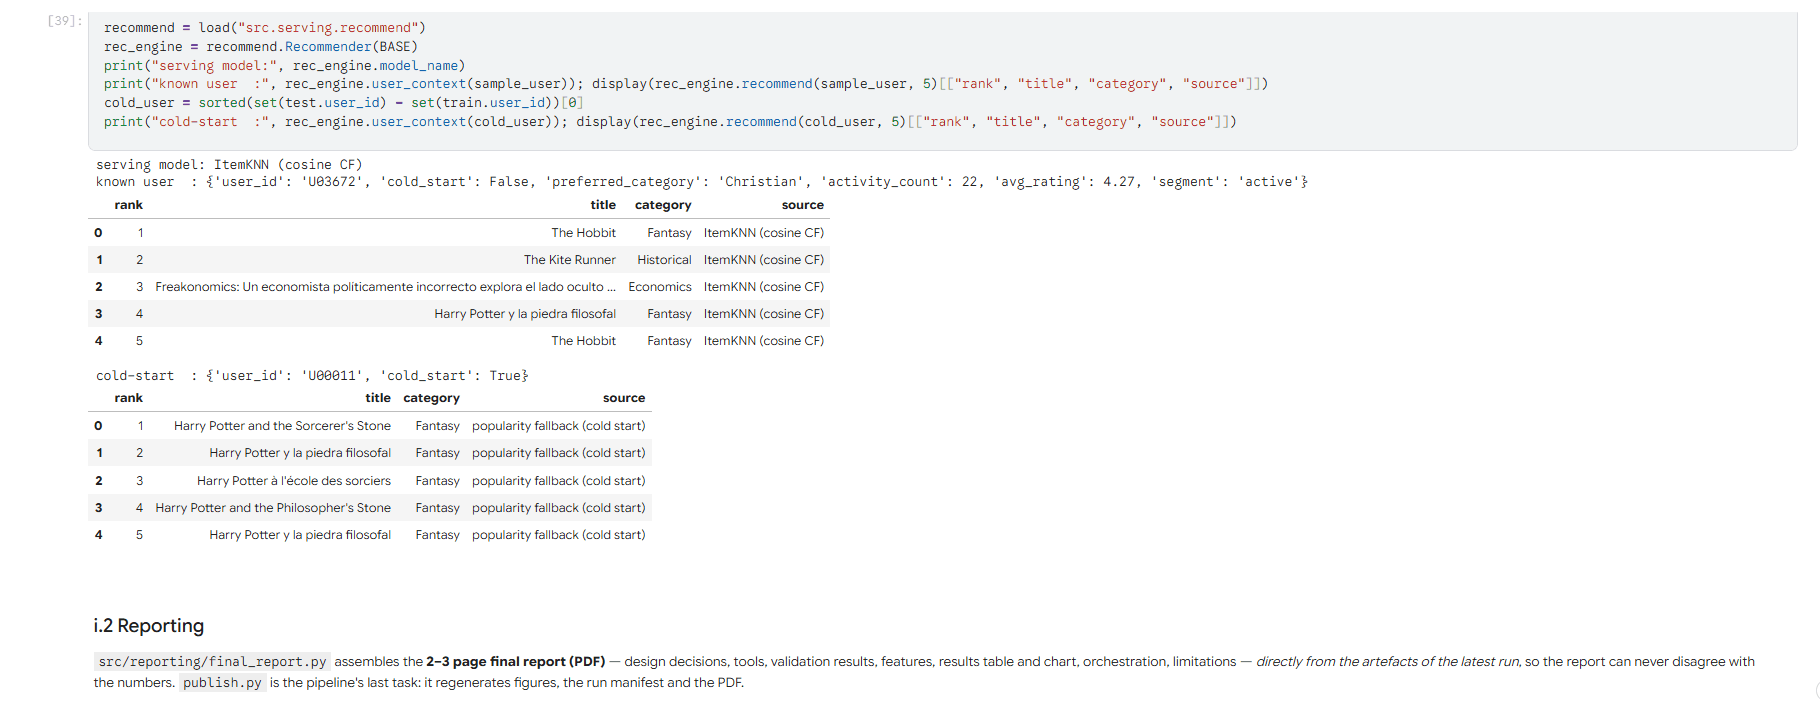

### m.4 Orchestration and reproducibility

**Figure m.7 — Task registry and dependencies.** The 16 workflow tasks, their dependency levels and the tasks each one depends on.

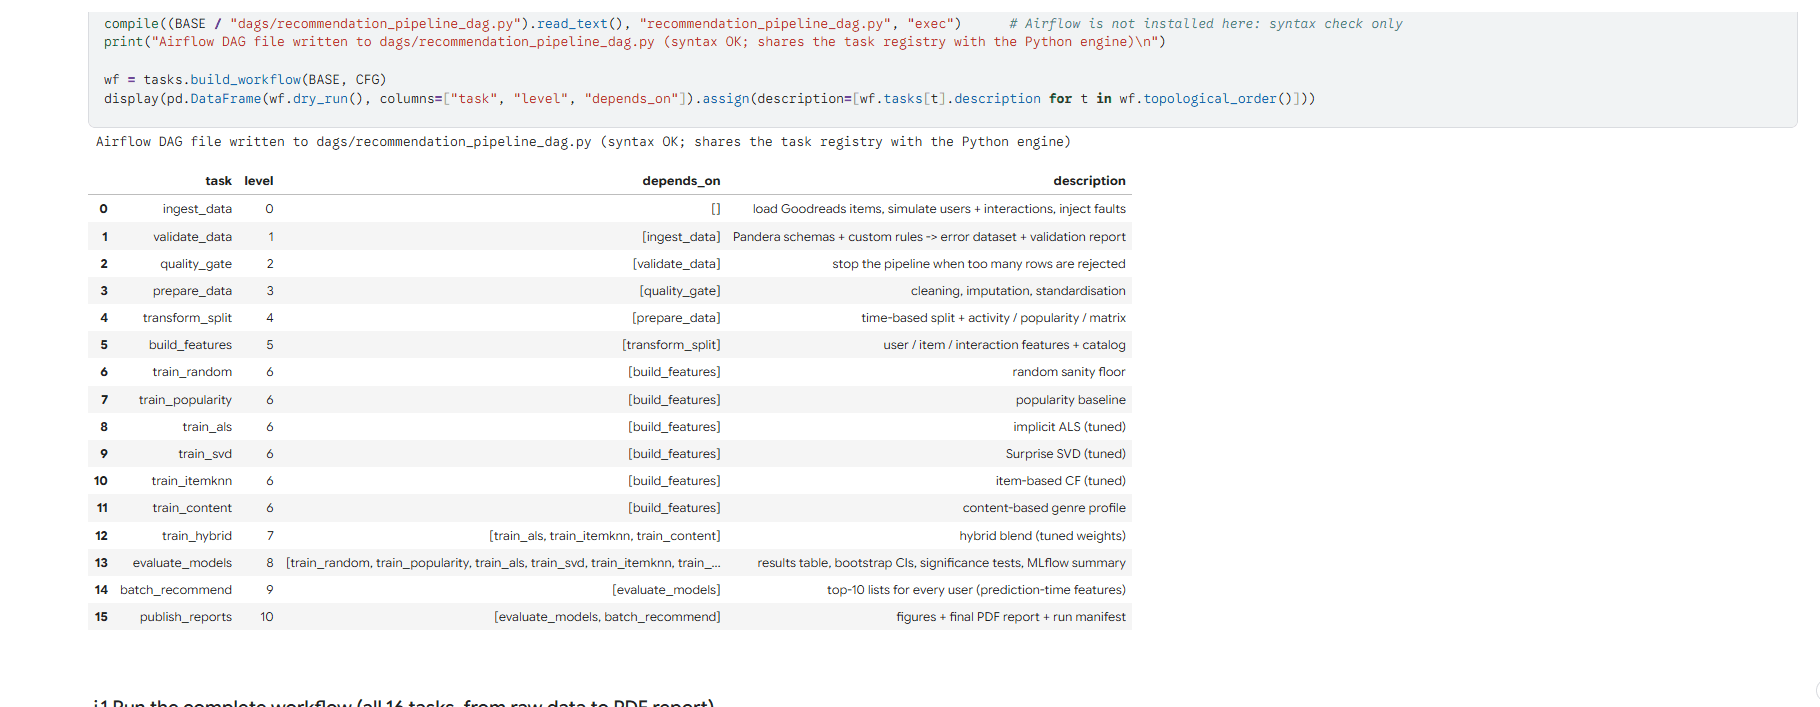

**Figure m.8 — Successful orchestrated run.** DAG of the full run: all 16 tasks succeeded in 63.4 s, shown with the per-task status and duration.

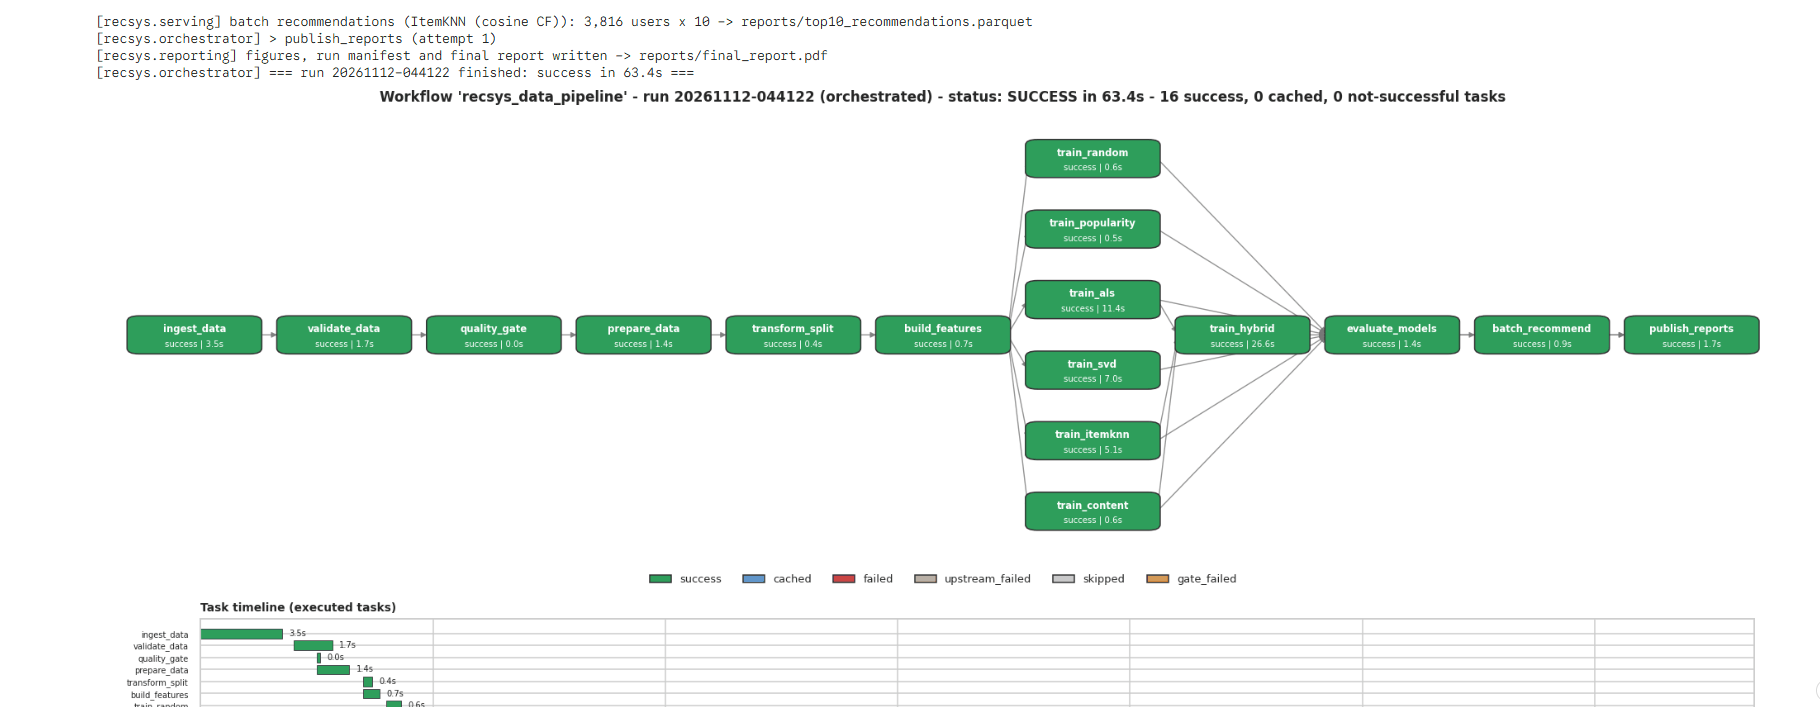

**Figure m.9 — Task table of the successful run.** Timeline of the executed tasks and the task table (status, attempts, seconds) for the same run.

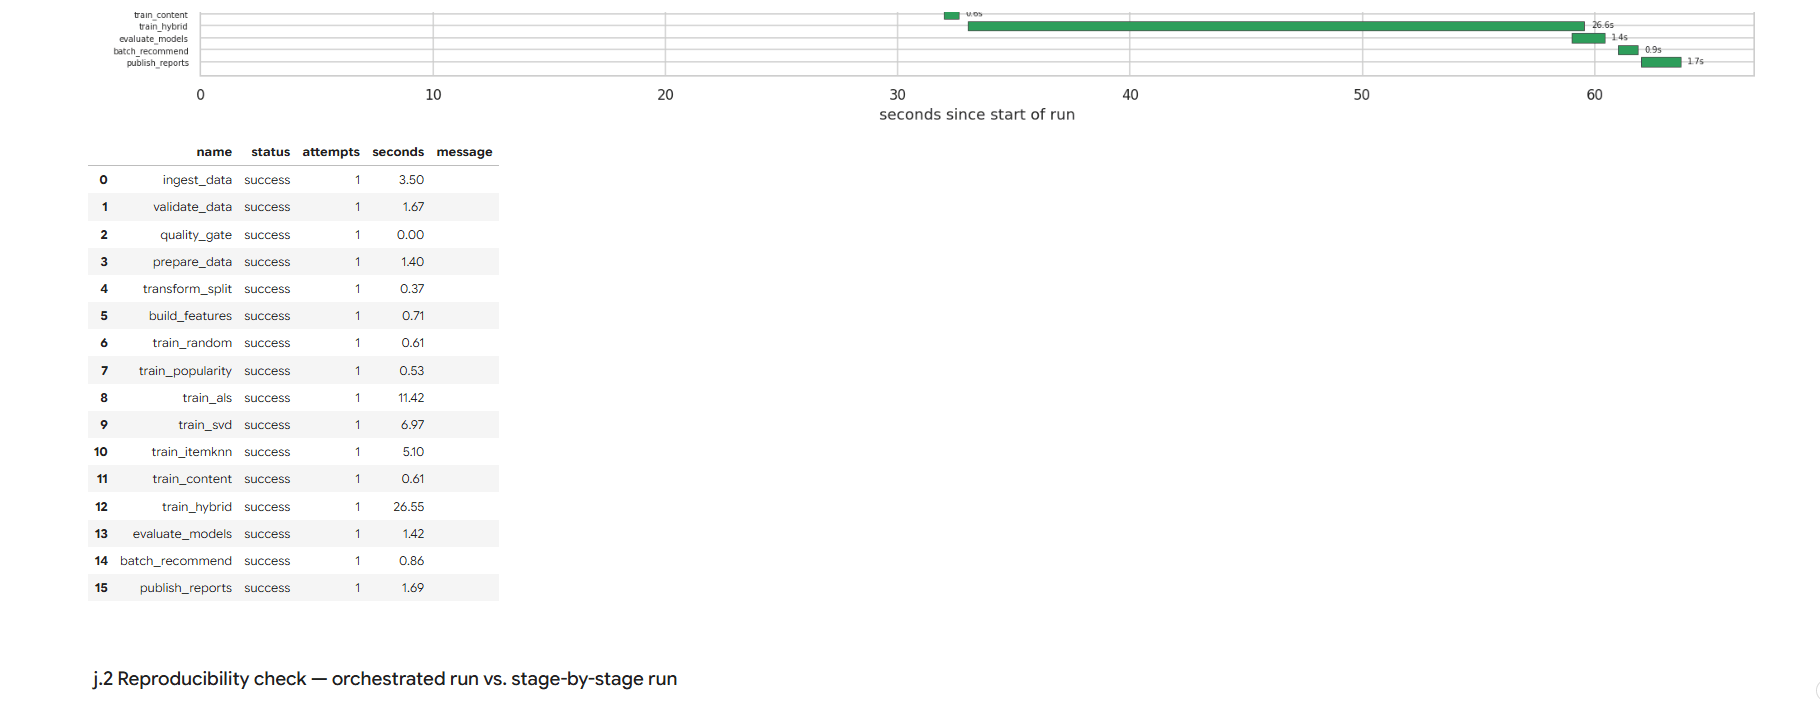

**Figure m.10 — Scheduled re-run (idempotence).** Second run with resume enabled: all 16 tasks are served from cache and nothing is recomputed.

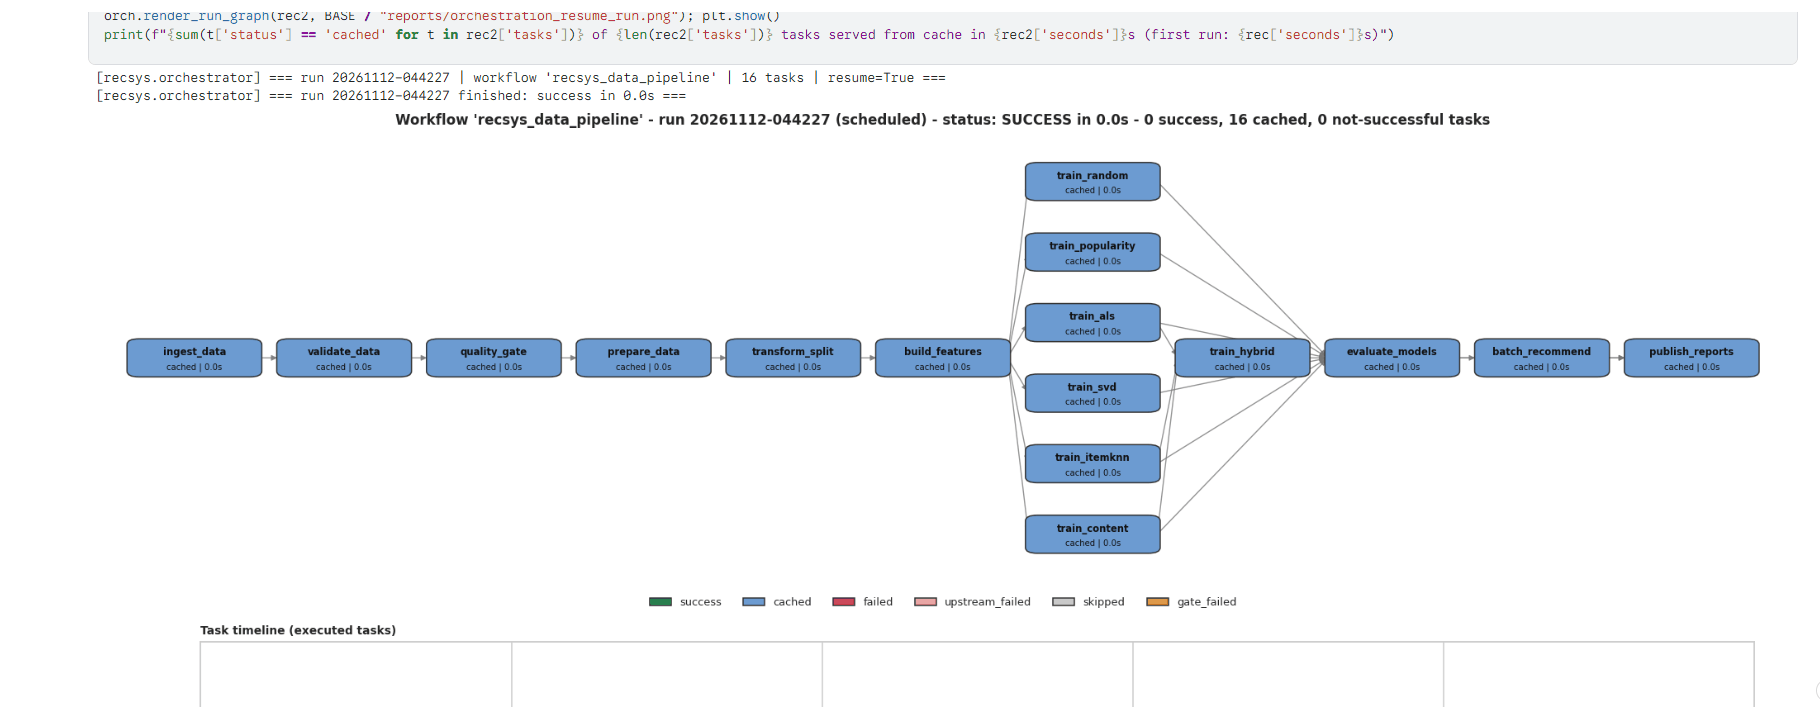

**Figure m.11 — Negative test: the data-quality gate stops a bad run.** With the rejection threshold lowered to 0.1 %, the quality gate fails and every downstream task is skipped.

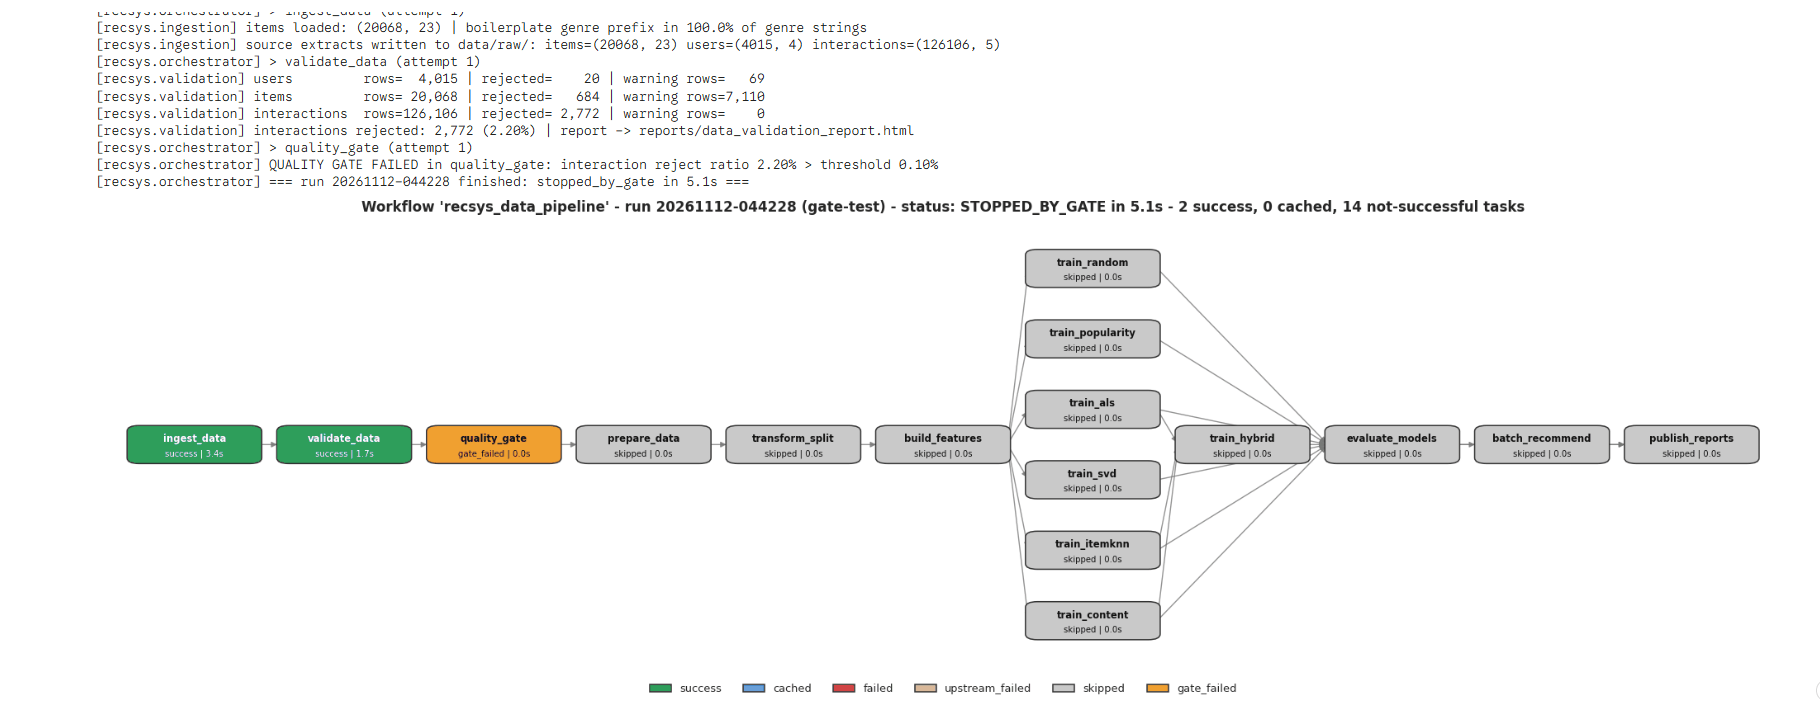

**Figure m.12 — Reproducibility check.** Orchestrated results are identical to the stage-by-stage results (maximum difference 0.00) and the resumed run is described next.

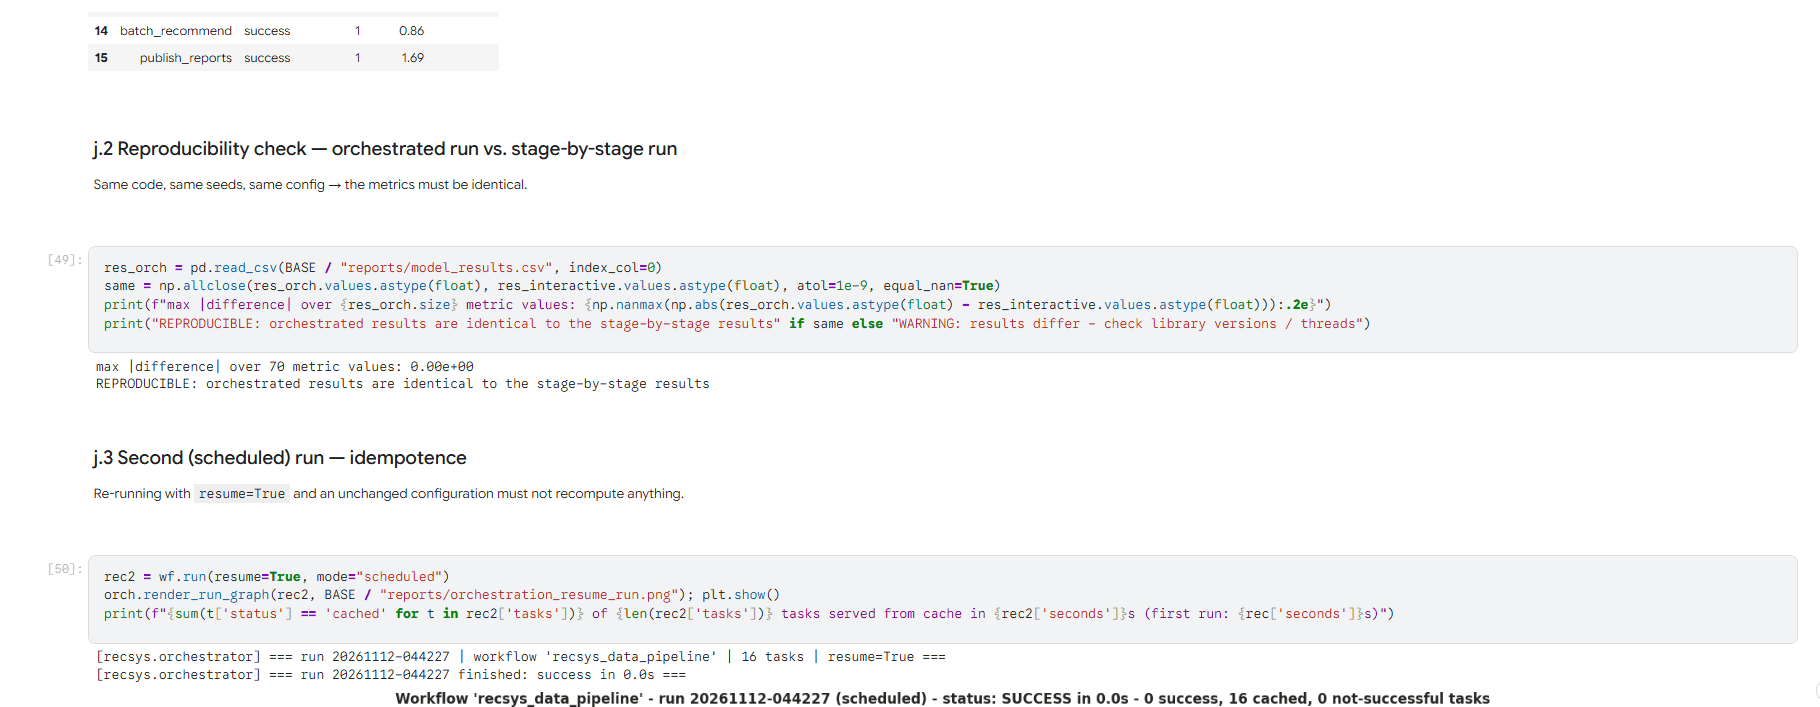

### m.5 Deliverables and conclusions

**Figure m.13 — Deliverables check.** Every deliverable required by the assignment is present: source modules, README, requirements, architecture diagram, validation report, feature catalog, results, MLflow store, DAG file, run screenshot and final report.

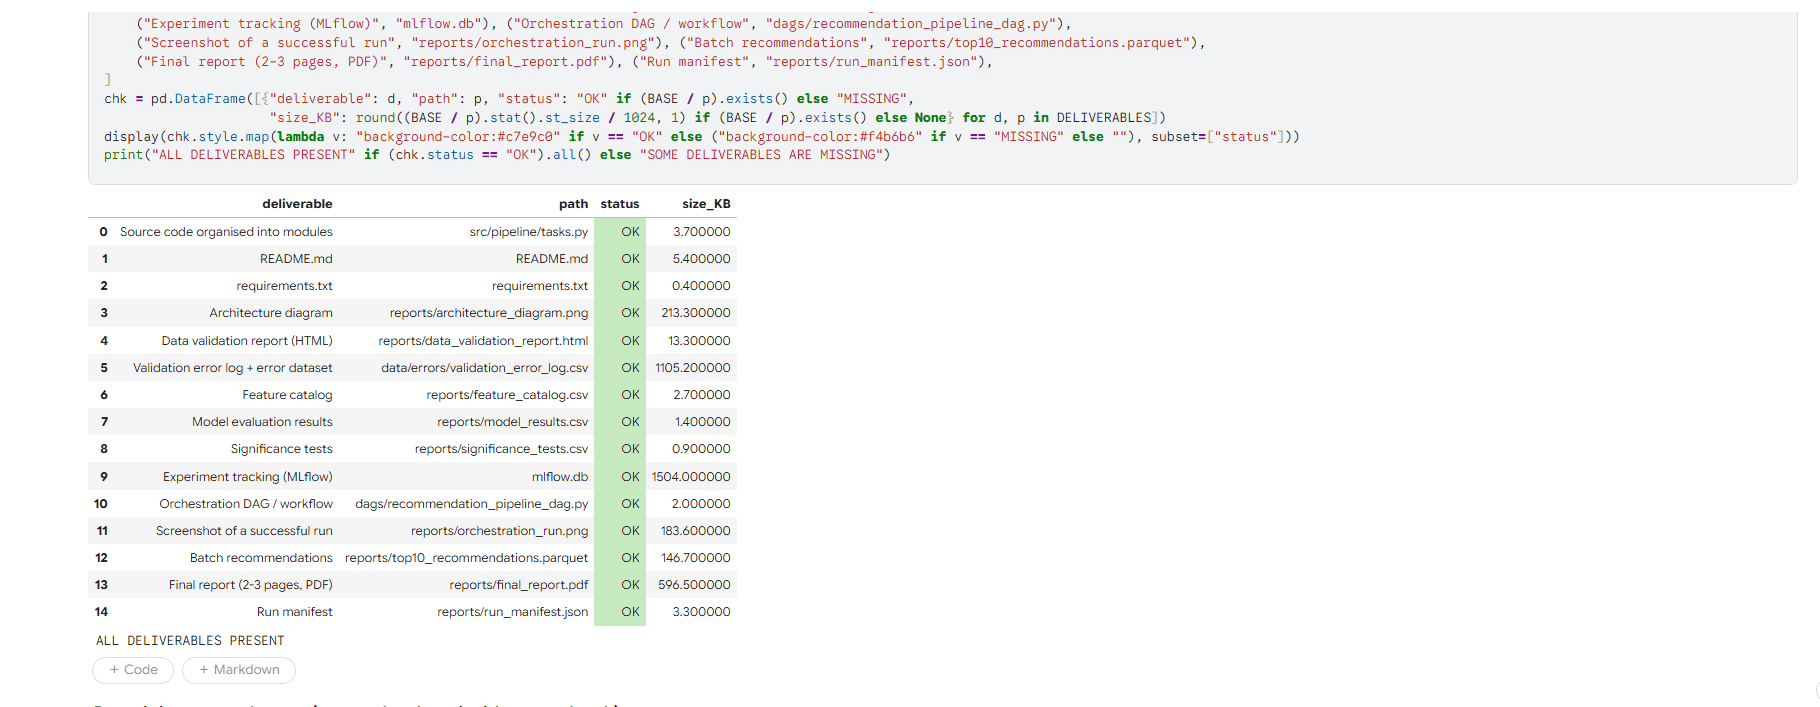

**Figure m.14 — Headline results and key inferences.** Summary of data quality, data shape, modelling and orchestration figures from the executed run, followed by the key inferences.

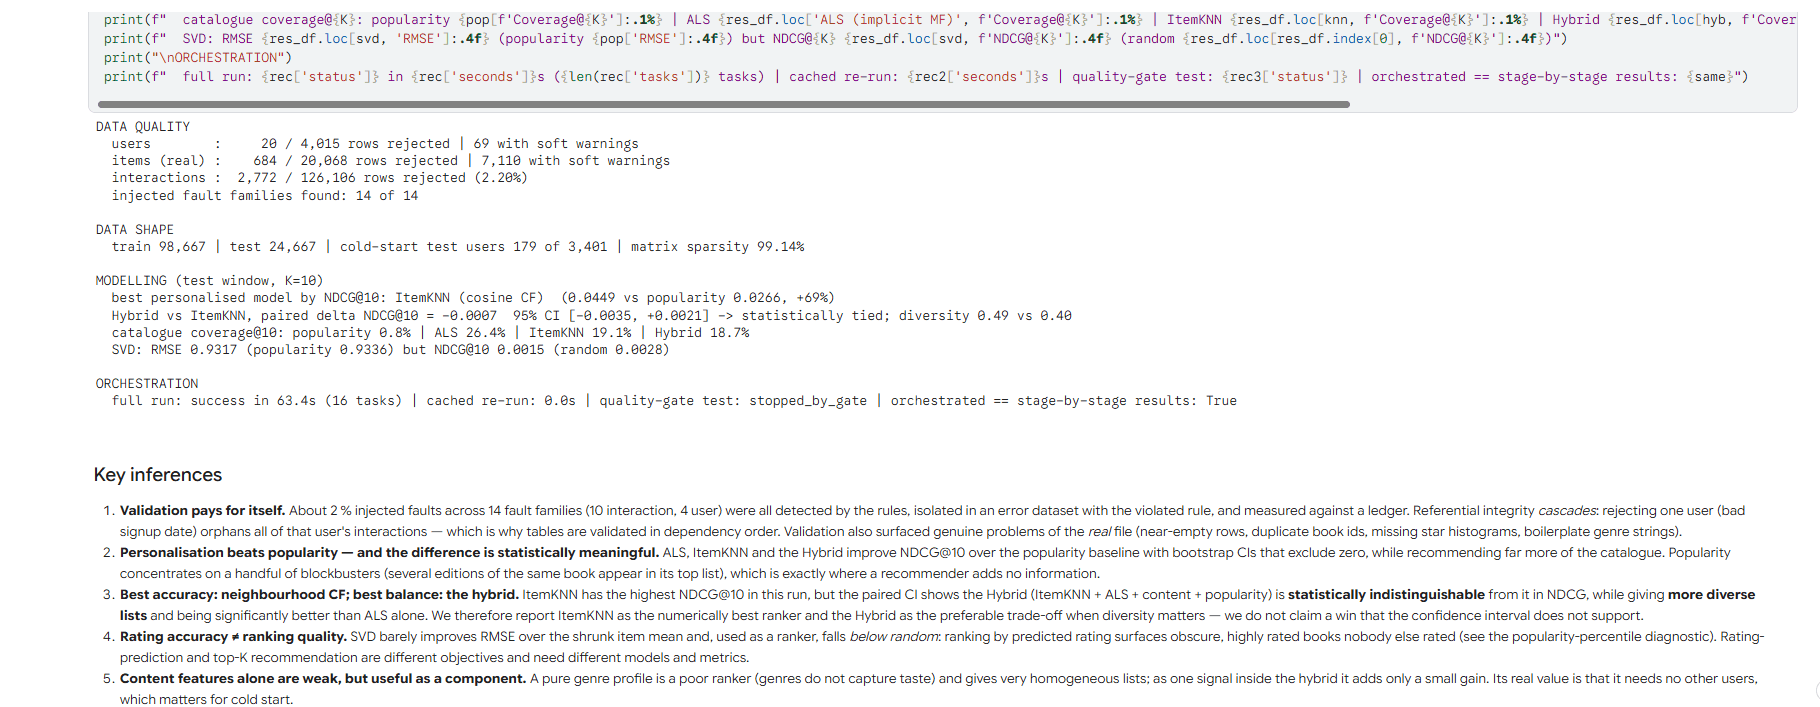

---
*End of notebook. Every figure, table and number above is regenerated by* **Run All** *from the single Goodreads CSV; the code of every stage lives in `src/` and can be run without the notebook via `python -m src.pipeline.run`.*